# P1 RESUELTA Y COMENTADA + BANCO DE EJERCICIOS DE EXAMEN

- **Parte 1:** enunciado original de la P1 con **todas las soluciones comentadas línea a línea**.
- **Parte 2 (al final):** banco de ejercicios tipo examen resueltos, por bloques A–J.

> Este notebook debe estar en la misma carpeta que `images_notebook/`. Ejecuta primero la celda de imports.
> Si algo falla en el PC del laboratorio por la versión de skimage: `channel_axis=-1` → `multichannel=True`.

# Computer Vision - P1

### *Carefully read the following instructions before start coding.*

### **Prerequisite**

- Before starting P1, you must **complete the 'p1_tutorial'.** The tutorial introduces the key concepts and steps needed to complete the practice successfully. Completing it first will help you understand the requirements and avoid common mistakes.


==============================================================================================

## **P1: Basics on Image Processing and Manipulation**
==============================================================================================

### The main topics are:

1. Image loading, saving and creation

2. Color manipulation

To complete this exercise, we will work with the following concepts: **image creation**, **data types**, and **image manipulation**.

==============================================================================================
### Packages loading

First we need to import the required Python packages for basic image manipulation.

Run the following code:

In [1]:
# ============================================================================
# IMPORTS BÁSICOS
# ============================================================================
import numpy as np                    # NumPy: una imagen ES un array de NumPy (matriz de números)
from skimage import io                # io.imread() para leer imágenes, io.imsave() para guardarlas
from matplotlib import pyplot as plt  # plt.imshow() para VER imágenes (ver != modificar)

# Imports extra que se usan a lo largo de la práctica (los pongo aquí para no olvidarlos)
import os                                         # crear carpetas, construir rutas
from skimage.color import rgb2gray, rgba2rgb, gray2rgb   # conversiones de color
from skimage.util import img_as_ubyte, img_as_float      # conversiones de tipo QUE REESCALAN
from skimage.exposure import rescale_intensity           # estirar el contraste
from skimage.transform import rescale, resize            # cambiar el tamaño

Note that commands starting with the percentage sign (`%`) are special internal commands to ipython (as opposed to Python code to be run). In the case below, we set the matplotlib environment to display images results inline (i.e. the images will be shown **inside the
notebook**):

In [2]:
# Comando "mágico" de Jupyter (empieza por %): muestra las figuras DENTRO del notebook
%matplotlib inline

==============================================================================================

### **1.1 Image creation**

Remember that [Numpy](https://docs.scipy.org/doc/numpy-1.13.0/reference/) allows us to define images of different kinds treating them as matrices.

The most common examples are:

* Binary: with values of 0 or 1, interpreted as black or white, respectively.
* Grayscale: with possible data types uint8, uint16, double, whose pixel values define their intensity.
* RGB Image: color images consisting of 3 matrices (usually called 'channels'), which contain intensity values for each color separately R (red), G (green) and B (blue).


**a) Create and display a 100 × 100 grayscale image represented as a 2D array.**
 - Each element of the array must be an 8-bit unsigned integer (`uint8`). 
 - Initialize all elements to zero. 
 - Hide the axes when displaying the image.
 - Print the data type (dtype) of the created image.

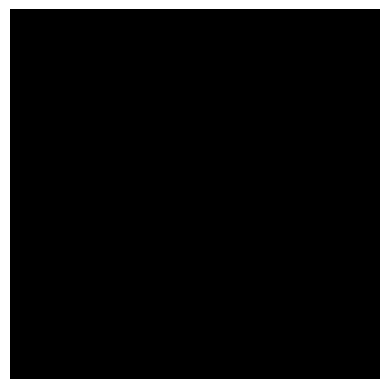

Image data type: uint8
Shape: (100, 100)


In [3]:
# ----------------------------------------------------------------------------
# 1.1 a) Imagen gris 100x100, uint8, todo ceros
# ----------------------------------------------------------------------------
# np.zeros(shape, dtype) crea un array lleno de ceros.
#   - shape (100, 100) -> 2 dimensiones = imagen en ESCALA DE GRISES (filas, columnas)
#   - dtype=np.uint8   -> enteros sin signo de 8 bits: valores de 0 a 255
#     (si no pones dtype, NumPy usa float64 por defecto -> ¡error típico!)
img = np.zeros((100, 100), dtype=np.uint8)

# imshow dibuja la matriz.
#   - cmap='gray'          -> un array 2D no tiene color; con 'gray' 0=negro y máximo=blanco
#                             (sin cmap saldría en 'viridis', morado/amarillo)
#   - vmin=0, vmax=255     -> fija el rango de visualización al rango real de uint8.
#                             Sin esto, una imagen CONSTANTE se pinta de un color arbitrario
#                             porque imshow autoescala entre min y max (que aquí son iguales).
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.axis('off')        # oculta los ejes (números y marcas)
plt.show()             # muestra la figura

print('Image data type:', img.dtype)   # -> uint8
print('Shape:', img.shape)             # -> (100, 100)

**b) How many distinct intensity levels can each pixel represent in this uint8 grayscale image? Explain your answer.**

In [4]:
# ----------------------------------------------------------------------------
# 1.1 b) ¿Cuántos niveles de intensidad distintos tiene un píxel uint8?
# ----------------------------------------------------------------------------
niveles = 2**8          # 8 bits, cada bit tiene 2 estados -> 2*2*...*2 (8 veces) = 256
print(niveles)          # 256

# También se puede consultar con NumPy:
print(np.iinfo(np.uint8).min, np.iinfo(np.uint8).max)   # 0 255 -> 256 valores (0..255)

# EXPLICACIÓN:
# uint8 = "unsigned integer de 8 bits". Con 8 bits se pueden formar 2^8 = 256 combinaciones
# distintas, así que cada píxel puede tomar 256 valores enteros: de 0 (negro) a 255 (blanco).
# (uint16 -> 2^16 = 65536 niveles; bool -> 2 niveles; int8 -> -128..127)

256
0 255


**c) Create and display a 100 × 100 RGB image represented as a 3D array.**
 - Each element of the array must be an 8-bit unsigned integer (`uint8`). 
 - Initialize all elements to zero. 
 - Then, convert the RGB image to Grayscale using `rgb2gray`.
 - Print the data type (dtype) and dimension (shape) of both images.

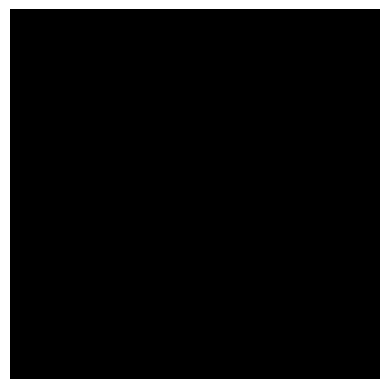

RGB image:       uint8 (100, 100, 3)
Grayscale image: float64 (100, 100)


In [5]:
# ----------------------------------------------------------------------------
# 1.1 c) Imagen RGB 100x100x3 uint8 a ceros -> pasarla a gris con rgb2gray
# ----------------------------------------------------------------------------
from skimage.color import rgb2gray

# shape (100, 100, 3): 3 dimensiones = alto, ancho, CANALES (R, G, B)
img_rgb = np.zeros((100, 100, 3), dtype=np.uint8)

# Para imágenes 3D (RGB) imshow IGNORA cmap/vmin/vmax: los colores salen de los canales.
# Para uint8 Matplotlib entiende el rango 0..255. Todo a 0 -> negro.
plt.imshow(img_rgb)
plt.axis('off')
plt.show()

# rgb2gray:
#   - elimina la 3ª dimensión: (100,100,3) -> (100,100)
#   - DEVUELVE float64 con valores en [0, 1] (¡cambia el tipo y el rango!)
#   - fórmula: Y = 0.2125*R + 0.7154*G + 0.0721*B  (media ponderada, el verde pesa más)
img_gray = rgb2gray(img_rgb)

print('RGB image:      ', img_rgb.dtype, img_rgb.shape)     # uint8   (100, 100, 3)
print('Grayscale image:', img_gray.dtype, img_gray.shape)   # float64 (100, 100)

**d) Modify the pixel values of the image created in Section 1.1(a) to reproduce the images shown below. Display the modified images using a figure with three subplots.**

![./images_notebook/gray_grid.png](./images_notebook/gray_grid.png)

Visualize the images and print the values of its first row.

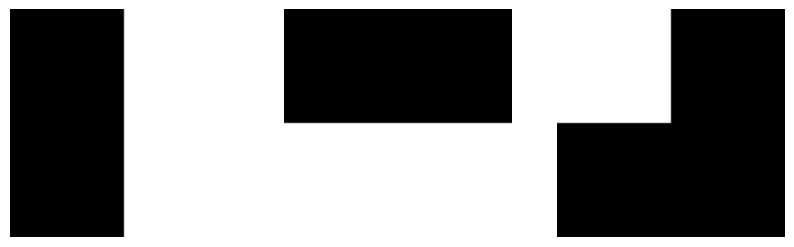

[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0 255 255 255 255
 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255
 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255
 255 255 255 255 255 255 255 255 255 255]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
[255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255
 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255 255
 255 255 255 255 255 255 255 255 255 255 255 255 255 255   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0

In [6]:
# ----------------------------------------------------------------------------
# 1.1 d) Modificar la imagen de (a) para obtener las 3 imágenes de la figura
# ----------------------------------------------------------------------------
# IMPORTANTE: .copy() -> si hiciera img1 = img, img1 y img serían EL MISMO array
# y al modificar img1 estropearía img (y las siguientes saldrían mal).

# Imagen 1: mitad DERECHA blanca
img1 = img.copy()
img1[:, 50:] = 255      # todas las filas (:), columnas desde la 50 hasta el final (50:)

# Imagen 2: mitad INFERIOR blanca
img2 = img.copy()
img2[50:, :] = 255      # filas desde la 50 hasta el final, todas las columnas

# Imagen 3: cuadrante SUPERIOR IZQUIERDO blanco
img3 = img.copy()
img3[:50, :50] = 255    # filas 0..49 y columnas 0..49  (el final del slice NO se incluye)

# Figura con 3 subplots: 1 fila, 3 columnas. axes es un array con 3 "Axes".
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

axes[0].imshow(img1, cmap='gray', vmin=0, vmax=255)
axes[1].imshow(img2, cmap='gray', vmin=0, vmax=255)
axes[2].imshow(img3, cmap='gray', vmin=0, vmax=255)

for ax in axes:          # recorro los 3 subplots para ocultar los ejes
    ax.axis('off')
plt.show()

# Primera fila de cada imagen: img[0, :] = fila 0, todas las columnas
print(img1[0, :])   # 50 ceros y 50 doscientoscincuentaycincos
print(img2[0, :])   # todo ceros (la fila 0 está en la mitad de ARRIBA, que es negra)
print(img3[0, :])   # 50 valores 255 y luego 50 ceros

**e) Vertically flip the third image, generated above, to create a mirror illusion, as illustrated below.**
- Display the resulting image while preserving the axes. 
- You can consult the NumPy documentation for help: [NumPy `flip` documentation](https://numpy.org/devdocs/reference/generated/numpy.flip.html).


![./images_notebook/mirror.png](./images_notebook/mirror.png)

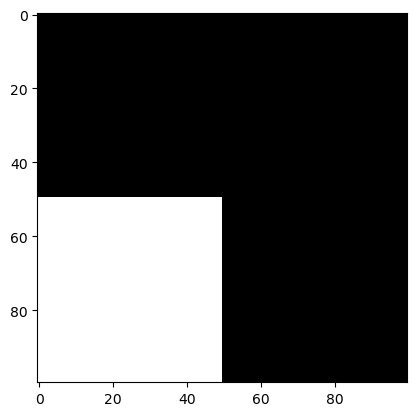

In [7]:
# ----------------------------------------------------------------------------
# 1.1 e) Voltear VERTICALMENTE img3 (efecto espejo), CONSERVANDO los ejes
# ----------------------------------------------------------------------------
# Voltear verticalmente = arriba <-> abajo = invertir el orden de las FILAS.
# Tres formas equivalentes:
img_flipped = np.flipud(img3)          # "flip up-down"
img_flipped = img3[::-1, :]            # slicing con paso -1 en las filas
img_flipped = np.flip(img3, axis=0)    # axis=0 = eje de las filas

# (Volteo HORIZONTAL izquierda<->derecha sería: np.fliplr(img3) / img3[:, ::-1] / np.flip(img3, axis=1))

plt.imshow(img_flipped, cmap='gray', vmin=0, vmax=255)
# NO pongo plt.axis('off') porque el enunciado pide preservar los ejes
plt.show()


**f) Create an RGB image by combining the three grayscale images created in the previous steps.**

Follow these steps:

1. Create a **100 × 100 RGB image** using the `uint8` data type and initialize all pixel values to zero.
2. Use the first grayscale image (`img1`) to define the **red channel** of the RGB image.
3. Use the second grayscale image (`img2`) to define the **green channel**.
4. Use the third grayscale image (`img3`) to define the **blue channel**.
5. Display the resulting RGB image (the expected result is illustrated below).
 
![./images_notebook/color_grid.png](./images_notebook/color_grid.png)

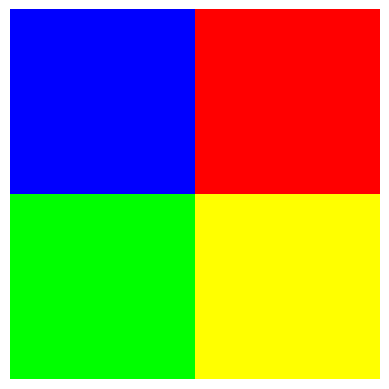

In [8]:
# ----------------------------------------------------------------------------
# 1.1 f) Crear una RGB usando img1, img2, img3 como canales R, G, B
# ----------------------------------------------------------------------------
# 1. Imagen RGB negra 100x100x3 uint8
img_color = np.zeros((100, 100, 3), dtype=np.uint8)

# 2-4. Cada canal es una matriz 2D (100x100). img_color[:, :, k] selecciona el canal k.
img_color[:, :, 0] = img1     # canal 0 = ROJO   <- mitad derecha
img_color[:, :, 1] = img2     # canal 1 = VERDE  <- mitad inferior
img_color[:, :, 2] = img3     # canal 2 = AZUL   <- cuadrante sup. izq.

# Alternativa en una línea: apilar las 3 matrices en la 3ª dimensión
# img_color = np.stack([img1, img2, img3], axis=2)

# Resultado por cuadrantes (mezcla ADITIVA de luz):
#   sup-izq: solo B      -> AZUL
#   sup-der: solo R      -> ROJO
#   inf-izq: G + B       -> CIAN
#   inf-der: R + G       -> AMARILLO
plt.imshow(img_color)
plt.axis('off')
plt.show()

### **1.2 Image saving and loading**

**a) Use the `io` module to save the previously generated RGB image in a directory named `output`.**
- If the directory does not exist, we create it using Python.
- Save the image with the filename `rgb_image.png`.


In [9]:
# Crear la carpeta 'output' si no existe
import os
if not os.path.exists("output"):   # ¿existe ya?
    os.mkdir("output")             # si no, la creo
# Alternativa en una línea: os.makedirs("output", exist_ok=True)

In [10]:
# ----------------------------------------------------------------------------
# 1.2 a) Guardar la imagen RGB en output/rgb_image.png
# ----------------------------------------------------------------------------
# os.path.join construye la ruta con el separador correcto (\ en Windows, / en Mac/Linux)
ruta = os.path.join('output', 'rgb_image.png')

# io.imsave(ruta, array). Guardar SIEMPRE en uint8 (aquí ya lo es).
# PNG = sin pérdida -> al releer obtendremos exactamente los mismos valores.
io.imsave(ruta, img_color)

**b) Load the saved image and display it.**
- Additionally, print its dimensions, the value of the pixel at `(10, 10)`, and its data type (`dtype`) to verify that everything is correct.

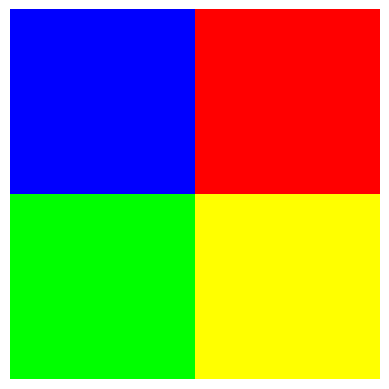

(100, 100, 3)
[  0   0 255]
uint8
Idéntica: True


In [11]:
# ----------------------------------------------------------------------------
# 1.2 b) Cargar la imagen guardada, mostrarla e imprimir shape, píxel (10,10) y dtype
# ----------------------------------------------------------------------------
img_loaded = io.imread(os.path.join('output', 'rgb_image.png'))   # -> array NumPy

plt.imshow(img_loaded)
plt.axis('off')
plt.show()

print(img_loaded.shape)      # (100, 100, 3)
print(img_loaded[10, 10])    # [  0   0 255] -> fila 10, col 10 está en el cuadrante sup-izq = azul
print(img_loaded.dtype)      # uint8

# Comprobación extra: ¿es idéntica a la que guardé? (en PNG sí; en JPG NO por la compresión)
print('Idéntica:', np.array_equal(img_loaded, img_color))

### **1.3 Basic image manipulations: RGB to grayscale, data type conversion, thresholding, and more**

**a) Load and display the image `panda.jpg` from the `images_notebook` directory.**
 - Print the image dimensions and data type. 
 - Then, convert it to grayscale using `rgb2gray`. 
 - Display the resulting grayscale image using an appropriate colormap.
 - Print the image dimensions and data type of the grayscale image. 


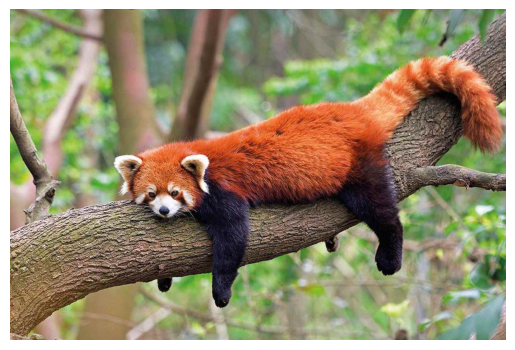

(800, 1200, 3)
uint8


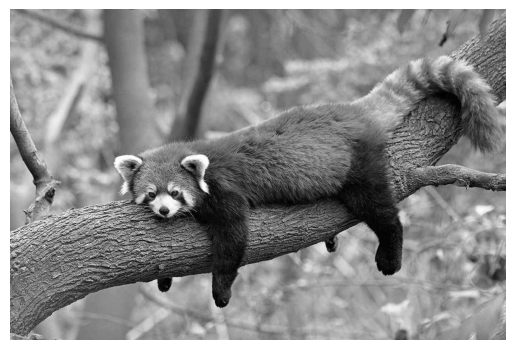

(800, 1200)
float64


In [12]:
# ----------------------------------------------------------------------------
# 1.3 a) Cargar panda.jpg, info, pasar a gris, mostrar, info
# ----------------------------------------------------------------------------
from skimage.color import rgb2gray

img_panda = io.imread('images_notebook/panda.jpg')   # JPG a color -> uint8 (alto, ancho, 3)

plt.imshow(img_panda)       # RGB: no hace falta cmap
plt.axis('off')
plt.show()

print(img_panda.shape)      # (800, 1200, 3) -> 800 filas, 1200 columnas, 3 canales
print(img_panda.dtype)      # uint8

img_gray = rgb2gray(img_panda)   # -> (800, 1200), float64 en [0, 1]

plt.imshow(img_gray, cmap='gray')   # colormap apropiado para gris: 'gray'
plt.axis('off')
plt.show()

print(img_gray.shape)       # (800, 1200)  -> desaparece la dimensión de canales
print(img_gray.dtype)       # float64      -> rgb2gray cambia el tipo

**b) Save the grayscale image**

- Save the grayscale image generated above in the `output` directory with the filename `panda_gray.jpg`.
- Check the [documentation](https://scikit-image.org/docs/stable/api/skimage.util.html#skimage.util.img_as_ubyte) for `img_as_ubyte` to understand how to convert the grayscale image to `uint8` before saving it.
- Display the original RGB image and the grayscale image side by side in a figure with two subplots.
- Print the minimum and maximum values of each image:
  - RGB
  - Grayscale (original)
  - Grayscale (after converting it to uint8)

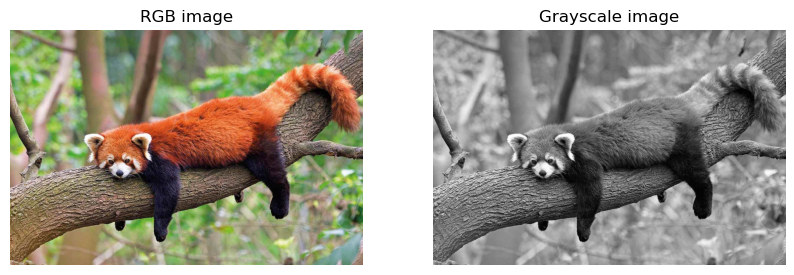

RGB               : uint8 0 255
Gray (original)   : float64 0.0 1.0
Gray (uint8)      : uint8 0 255


In [13]:
# ----------------------------------------------------------------------------
# 1.3 b) Guardar la gris como panda_gray.jpg + subplots + min/max
# ----------------------------------------------------------------------------
from skimage.util import img_as_ubyte

# img_gray es float64 en [0,1]. Para guardarla en JPG hay que pasarla a uint8 [0,255].
# img_as_ubyte multiplica por 255 y redondea -> uint8.
# ¡NO usar img_gray.astype(np.uint8)! eso TRUNCA: 0.7 -> 0, y casi toda la imagen sería 0 (negra).
img_gray_uint8 = img_as_ubyte(img_gray)

io.imsave(os.path.join('output', 'panda_gray.jpg'), img_gray_uint8)

# Dos subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_panda)
axes[0].set_title('RGB image')                # en un Axes se usa set_title (no plt.title)
axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title('Grayscale image')
for ax in axes:
    ax.axis('off')
plt.show()

print('RGB               :', img_panda.dtype,      img_panda.min(),      img_panda.max())       # uint8 0 255
print('Gray (original)   :', img_gray.dtype,       img_gray.min(),       img_gray.max())        # float64 0.0 1.0
print('Gray (uint8)      :', img_gray_uint8.dtype, img_gray_uint8.min(), img_gray_uint8.max())  # uint8 0 255

**c) Compute the mean of the previous grayscale image (before converting it to `uint8`) and use a logical operation to obtain a binary image.** 
- Pixels with values greater than the mean should be displayed as white (`1`), while all other pixels should be displayed as black (`0`). 
- Display the resulting binary image.


Media: 0.5023766645825162
bool (800, 1200)


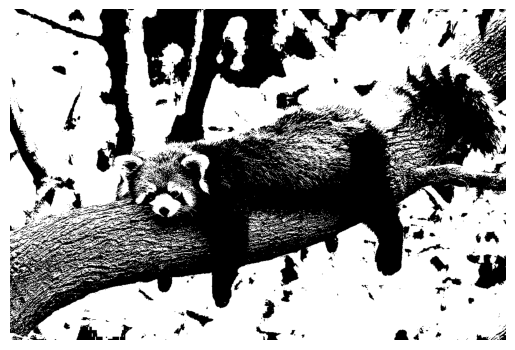

In [14]:
# ----------------------------------------------------------------------------
# 1.3 c) Binarizar: píxel > media -> 1 (blanco), resto -> 0 (negro)
# ----------------------------------------------------------------------------
mean_value = img_gray.mean()          # (o np.mean(img_gray)) media de TODOS los píxeles
print('Media:', mean_value)

# Una COMPARACIÓN sobre un array devuelve un array de bool (True/False) del mismo shape.
# Eso ya es una imagen binaria: True=1=blanco, False=0=negro.
img_binary = img_gray > mean_value

print(img_binary.dtype, img_binary.shape)   # bool (800, 1200)
# Si te pidieran 0/1 en enteros:   img_binary.astype(np.uint8)
# Si te pidieran 0/255 en uint8:   img_binary.astype(np.uint8) * 255

plt.imshow(img_binary, cmap='gray')
plt.axis('off')
plt.show()

**d) Display the original RGB image, the grayscale image, and the binary image side by side in a figure with three subplots.**
- Add the titles `Original`, `Grayscale`, and `Binary`, respectively, and hide the axes.

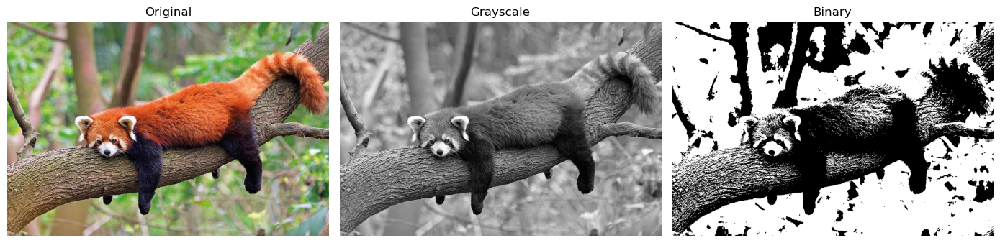

In [15]:
# ----------------------------------------------------------------------------
# 1.3 d) Original / Grayscale / Binary en 3 subplots con títulos, sin ejes
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

imagenes = [img_panda, img_gray, img_binary]
titulos  = ['Original', 'Grayscale', 'Binary']

# zip recorre a la vez los subplots, las imágenes y los títulos
for ax, im, t in zip(axes, imagenes, titulos):
    ax.imshow(im, cmap='gray')   # cmap se ignora en la RGB, se aplica en las 2D
    ax.set_title(t)
    ax.axis('off')

plt.tight_layout()   # ajusta espacios para que no se solapen los títulos
plt.show()

**e) Create a new RGB black image that is 15% larger than the original `panda` image in both height and width. Then, embed the original panda image in the center of the new image.**

Follow these steps:

1. Use the previously loaded image `img_panda`.
2. Retrieve the **shape** of `img_panda` to determine its height, width, and number of channels.
3. Create a new black RGB image whose:
   - height is 15% larger than the height of `img_panda`;
   - width is 15% larger than the width of `img_panda`;
   - number of channels is 3.
4. Use the `uint8` data type for the new image.
5. Place `img_panda` in the **center** of the new black image using array slicing.
6. Display the resulting framed image (expected result is shown below).

> **Note:** Be careful with the **number of channels** when creating the new image. An RGB image must have three channels.

> **Note:** Print the shapes of both `img_panda` and the new image. Verify that the height and width of the new image are approximately **15% larger** than those of the original image.

> **Optional:** As an alternative approach, investigate how the `rescale` function from `skimage.transform` could be used to create an image 15% larger.

![./images_notebook/gray_grid.png](./images_notebook/framed_panda.jpg)

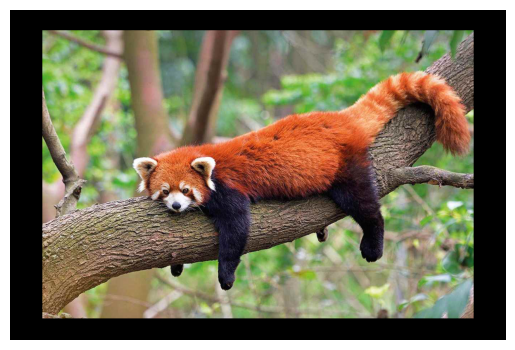

Original: (800, 1200, 3)
Nueva   : (919, 1380, 3)
Ratio   : 1.14875 1.15
Con rescale: (920, 1380, 3)


In [16]:
# ----------------------------------------------------------------------------
# 1.3 e) Lienzo negro 15% más grande y el panda CENTRADO
# ----------------------------------------------------------------------------
# 2. Desempaquetar el shape: (alto, ancho, canales)
height, width, channels = img_panda.shape

# 3. Nuevas dimensiones: 15% más grande = multiplicar por 1.15.
#    int() porque un shape tiene que ser ENTERO (800*1.15 = 919.99... -> 919)
new_height = int(height * 1.15)
new_width  = int(width * 1.15)

# 3-4. Imagen negra RGB uint8 con 3 canales (¡no olvidar el 3!)
img_panda_black = np.zeros((new_height, new_width, 3), dtype=np.uint8)

# 5. Coordenada de la esquina superior izquierda donde empieza el panda.
#    Para centrar: (espacio sobrante) / 2. Uso // (división entera) porque los índices son enteros.
start_row = (new_height - height) // 2
start_col = (new_width - width) // 2

# Pegar el panda: la región destino debe medir EXACTAMENTE height x width,
# por eso va de start hasta start + tamaño.
img_panda_black[start_row:start_row + height,
                start_col:start_col + width] = img_panda

plt.imshow(img_panda_black)
plt.axis('off')
plt.show()

print('Original:', img_panda.shape)         # (800, 1200, 3)
print('Nueva   :', img_panda_black.shape)   # (919, 1380, 3)
print('Ratio   :', new_height / height, new_width / width)   # ~1.15

# OPCIONAL - con rescale: escala la IMAGEN (no crea marco).
# channel_axis=-1 indica que la última dimensión son canales (para no escalarlos).
# Devuelve float en [0,1] -> img_as_ubyte para volver a uint8.
img_big = img_as_ubyte(rescale(img_panda, 1.15, channel_axis=-1))
print('Con rescale:', img_big.shape)

**f) Change the frame of the new image to green.** 
- Display the three images (the original image, the image with a black frame, and the image with a green frame) in a single figure, with their respective titles.
- Expected result is illustrated below.

![./images_notebook/gray_grid.png](./images_notebook/framed_panda_green.jpg)

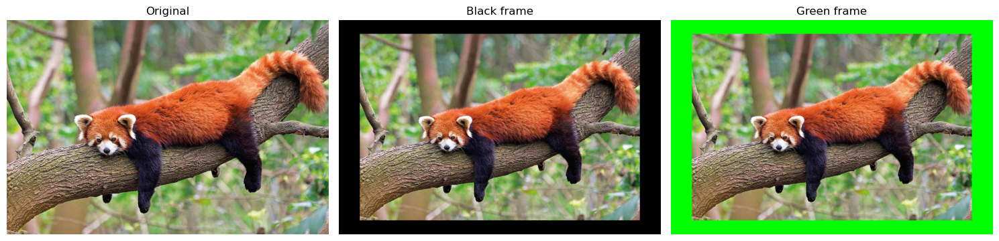

In [17]:
# ----------------------------------------------------------------------------
# 1.3 f) Cambiar el marco a VERDE y mostrar las 3 imágenes
# ----------------------------------------------------------------------------
img_panda_green = img_panda_black.copy()   # copia para no estropear la del marco negro

verde = [0, 255, 0]   # [R, G, B]. Al asignar una lista de 3 a una región (h, w, 3),
                      # NumPy la "repite" (broadcasting) en todos los píxeles.

# Las 4 bandas del marco:
img_panda_green[:start_row, :] = verde                 # banda superior: filas antes del panda
img_panda_green[start_row + height:, :] = verde        # banda inferior: filas después del panda
img_panda_green[:, :start_col] = verde                 # banda izquierda: columnas antes
img_panda_green[:, start_col + width:] = verde         # banda derecha: columnas después

# ALTERNATIVA MÁS CORTA: pintar todo de verde y volver a pegar el panda en el centro
# img_panda_green = np.zeros_like(img_panda_black); img_panda_green[:] = verde
# img_panda_green[start_row:start_row+height, start_col:start_col+width] = img_panda

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(img_panda);        axes[0].set_title('Original')
axes[1].imshow(img_panda_black);  axes[1].set_title('Black frame')
axes[2].imshow(img_panda_green);  axes[2].set_title('Green frame')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### **1.4 Brightness Adjustment**

In some application domains, such as medical imaging, images may exhibit low contrast, making it difficult to distinguish structures and details.

**a) Load the image `images_notebook/cell_lowcontrast2.png` and display it without applying any contrast enhancement.** 

Then:

1. Print the **shape** of the image.
2. Print its **data type**.
3. Print the **minimum** and **maximum** pixel values.

> **Note:** When displaying an image with `imshow()`, Matplotlib automatically adjusts the displayed intensity range to enhance the image contrast. As a result, the image may appear to have better contrast than it actually does. To visualize the image using its original intensity values, specify the `vmin` and `vmax` parameters in `imshow()`. Choose appropriate values according to the image data type. For example, for an 8-bit unsigned integer (`uint8`) image, the full intensity range is from `0` to `255`.

Shape: (898, 1181)
Dtype: uint8
Min  : 80
Max  : 181


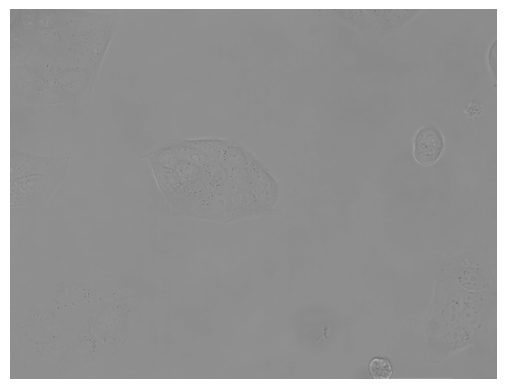

In [18]:
# ----------------------------------------------------------------------------
# 1.4 a) Cargar imagen de bajo contraste y mostrarla SIN autocontraste
# ----------------------------------------------------------------------------
img_cell = io.imread('images_notebook/cell_lowcontrast2.png')

print('Shape:', img_cell.shape)      # (898, 1181) -> gris
print('Dtype:', img_cell.dtype)      # uint8
print('Min  :', img_cell.min())      # 80
print('Max  :', img_cell.max())      # 181  -> solo usa 101 de los 256 niveles = BAJO CONTRASTE

# Si NO pongo vmin/vmax, imshow pinta 80 como negro y 181 como blanco (autocontraste)
# y la imagen PARECE tener buen contraste. Con vmin=0, vmax=255 se ve tal cual es: grisácea.
plt.imshow(img_cell, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

**b) Create a new image called `dark_image` by modifying the pixel values of the original image.**

Follow these steps:

1. Compute the **minimum pixel value** of the original image.
2. Create `dark_image` by subtracting this minimum value from every pixel in the original image.
3. Print the **minimum** and **maximum** pixel values of `dark_image`.
4. Pring the **shape** and *dtype** of the generated image.
5. Display `dark_image` **without applying any automatic contrast enhancement**.

> **Note:** Use the same `vmin` and `vmax` values as in the previous exercise so that the displayed image reflects the actual pixel intensities and is not automatically enhanced by `imshow()`.

Min: 0
Max: 101
Shape y dtype: (898, 1181) uint8


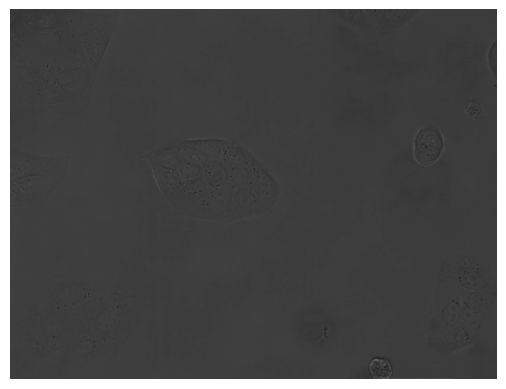

In [19]:
# ----------------------------------------------------------------------------
# 1.4 b) dark_image = original - mínimo  (desplazar hacia abajo)
# ----------------------------------------------------------------------------
min_value = img_cell.min()            # 80

# Resto el mínimo a TODOS los píxeles (NumPy lo hace elemento a elemento).
# ¿Overflow uint8? No: como resto el mínimo, ningún píxel baja de 0.
# (Si restara un valor MAYOR que el mínimo, los negativos darían la vuelta: 10-50 = 216)
dark_image = img_cell - min_value

print('Min:', dark_image.min())                          # 0
print('Max:', dark_image.max())                          # 101
print('Shape y dtype:', dark_image.shape, dark_image.dtype)   # (898, 1181) uint8

plt.imshow(dark_image, cmap='gray', vmin=0, vmax=255)    # mismos vmin/vmax -> se ve más oscura
plt.axis('off')
plt.show()
# OJO: el CONTRASTE es el mismo (la diferencia entre píxeles no cambia), solo es más oscura.

**c) Similarly to the previous question, create a new image called `bright_im` by modifying the pixel values of the original image so that the maximum pixel value becomes 255**.

Follow these steps:

1. Compute the **maximum pixel value** of the original image.
2. Determine the value that must be added to each pixel so that the maximum intensity in the new image is `255`.
3. Create `bright_im` by adding this value to all pixels in the original image.
4. Print the **minimum** and **maximum** pixel values of `bright_im`.
5. Pring the **shape** and *dtype** of the generated image.
6. Display `bright_im` **without applying any automatic contrast enhancement**.

> **Note:** Use the same `vmin` and `vmax` values as in the previous exercises so that the image is displayed using its actual intensity values.

Min: 154
Max: 255
Shape y dtype: (898, 1181) uint8


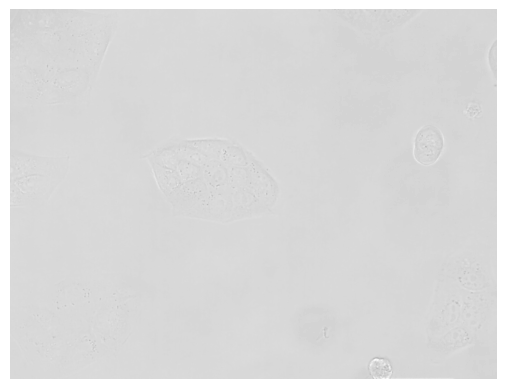

In [20]:
# ----------------------------------------------------------------------------
# 1.4 c) bright_im: sumar lo necesario para que el máximo sea 255
# ----------------------------------------------------------------------------
max_value = img_cell.max()           # 181
offset = 255 - max_value             # 74 -> lo que falta para llegar a 255

# ¿Overflow? No: el píxel más alto llega justo a 255.
# (OJO: 255 - max_value con max_value uint8 da uint8; aquí 74, sin problema)
bright_im = img_cell + offset

print('Min:', bright_im.min())                          # 154
print('Max:', bright_im.max())                          # 255
print('Shape y dtype:', bright_im.shape, bright_im.dtype)

plt.imshow(bright_im, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

**d) Display the original image, `dark_image`, and `bright_im` side by side in a single figure with three subplots.**
- Use the same `vmin` and `vmax` values for all three images to avoid automatic contrast enhancement.


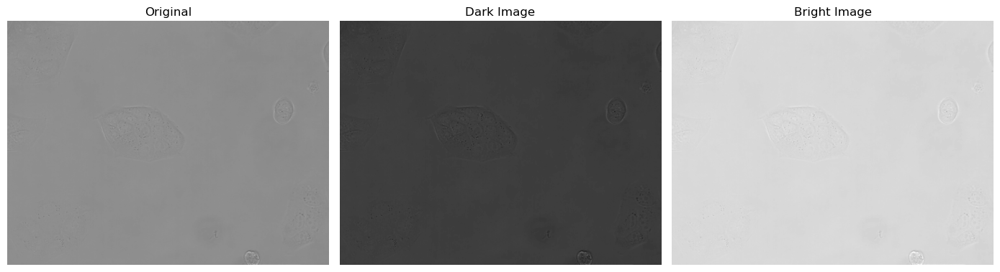

In [21]:
# ----------------------------------------------------------------------------
# 1.4 d) Original, dark, bright en 3 subplots con los MISMOS vmin/vmax
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, im, t in zip(axes,
                     [img_cell, dark_image, bright_im],
                     ['Original', 'Dark Image', 'Bright Image']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)   # mismo rango -> se comparan de verdad
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

**e) Contrast Stretching: create a new image by rescaling the pixel intensity values of the original image to the range [0, 1] using the following two approaches:**

- **Option 1 — Mathematical formula:** Perform the intensity rescaling manually using the contrast-stretching formula.
- **Option 2 — `rescale_intensity`:** Use the [`rescale_intensity`](https://scikit-image.org/docs/stable/api/skimage.exposure.html#skimage.exposure.rescale_intensity) function from `skimage.exposure` to perform the same operation.


**Option 1 — Using the mathematical formula**

1. Compute the **minimum** and **maximum** pixel values of the original image.

2. Rescale the pixel values to the range **[0, 1]** using the following formula:

   $
   \Large
   \qquad I_{\text{normalized}} =
   \frac{I - I_{\min}}{I_{\max} - I_{\min}}
   $

3. Print the **minimum** and **maximum** values of the resulting image to verify that they are `0` and `1`.

**Option 2 — Using `rescale_intensity`**

4. Use the [`rescale_intensity`](https://scikit-image.org/docs/stable/api/skimage.exposure.html#skimage.exposure.rescale_intensity) function from `skimage.exposure` to perform the same intensity rescaling.

5. Print the **minimum** and **maximum** values of the resulting image.

**Comparison**

6. Display the following images side by side in a **1×3 grid**:

   - the **original image**;
   - the image obtained using the **mathematical formula**;
   - the image obtained using **`rescale_intensity`**.

7. Use the appropriate intensity range (`vmin` and `vmax`) when displaying each image.

> **Tip:** Check the intensity range of each image before choosing `vmin` and `vmax`. Images with pixel values in the range **[0, 1]** should be displayed using `vmin=0` and `vmax=1`, while images with `uint8` pixel values in the range **[0, 255]** should be displayed using `vmin=0` and `vmax=255`.

8. Add the titles **Original**, **Formula**, and **Rescale intensity** to the corresponding subplots and hide the axes.

Fórmula          : float64 0.0 1.0
rescale_intensity: uint8 0 255
rescale_int (0,1): float64 0.0 1.0


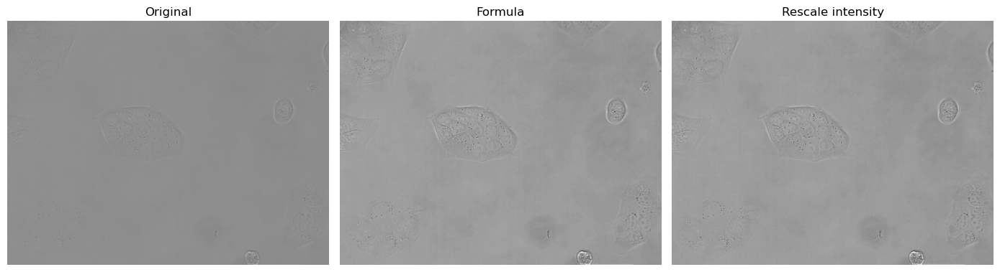

In [22]:
# ----------------------------------------------------------------------------
# 1.4 e) CONTRAST STRETCHING a [0, 1]: fórmula y rescale_intensity
# ----------------------------------------------------------------------------
from skimage.exposure import rescale_intensity

# --- Opción 1: fórmula  I_norm = (I - Imin) / (Imax - Imin) ---
minimum = img_cell.min()
maximum = img_cell.max()
# El operador / SIEMPRE devuelve float64 -> no hay problema de overflow ni truncado.
# El mínimo pasa a 0 y el máximo a 1: usamos TODO el rango -> más contraste.
img_formula = (img_cell - minimum) / (maximum - minimum)
print('Fórmula          :', img_formula.dtype, img_formula.min(), img_formula.max())   # float64 0.0 1.0

# --- Opción 2: rescale_intensity ---
# Por defecto estira al rango DEL TIPO de la imagen: uint8 -> [0, 255] (sigue siendo uint8)
img_rescale = rescale_intensity(img_cell)
print('rescale_intensity:', img_rescale.dtype, img_rescale.min(), img_rescale.max())   # uint8 0 255

# Para obtener EXACTAMENTE [0, 1] como pide el enunciado: out_range=(0, 1) -> float64
img_rescale01 = rescale_intensity(img_cell, out_range=(0, 1))
print('rescale_int (0,1):', img_rescale01.dtype, img_rescale01.min(), img_rescale01.max())  # float64 0.0 1.0

# Comparación: vmin/vmax según el RANGO de cada imagen
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(img_cell,    cmap='gray', vmin=0, vmax=255); axes[0].set_title('Original')
axes[1].imshow(img_formula, cmap='gray', vmin=0, vmax=1);   axes[1].set_title('Formula')
axes[2].imshow(img_rescale, cmap='gray', vmin=0, vmax=255); axes[2].set_title('Rescale intensity')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**f) Display the five images in a single figure, using one subplot for each image.** 
- Add the corresponding titles: *Original*, *Dark Image*, *Bright Image*, *Formula*, and *Rescale intensity*.


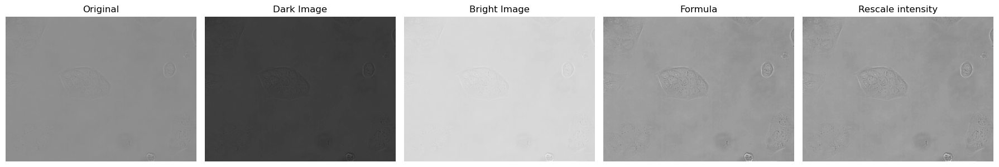

In [23]:
# ----------------------------------------------------------------------------
# 1.4 f) Las cinco imágenes en una figura
# ----------------------------------------------------------------------------
imagenes = [img_cell, dark_image, bright_im, img_formula, img_rescale]
titulos  = ['Original', 'Dark Image', 'Bright Image', 'Formula', 'Rescale intensity']
vmaxs    = [255, 255, 255, 1, 255]     # 1 para la float [0,1], 255 para las uint8

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, im, t, vm in zip(axes, imagenes, titulos, vmaxs):
    ax.imshow(im, cmap='gray', vmin=0, vmax=vm)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

### **1.5 Color manipulation**

**a) Load the image `images_notebook/barcelona.jpg` (shown below). Extract the three color channels (red, green, and blue) and display them in a single figure, using one subplot for each channel and adding the corresponding titles: *Red channel*, *Green channel*, and *Blue channel* (bottom figure).**

<img src="images_notebook/barcelona.jpg">

<img src="images_notebook/barcelona_channels.png">

(682, 1024, 3) uint8


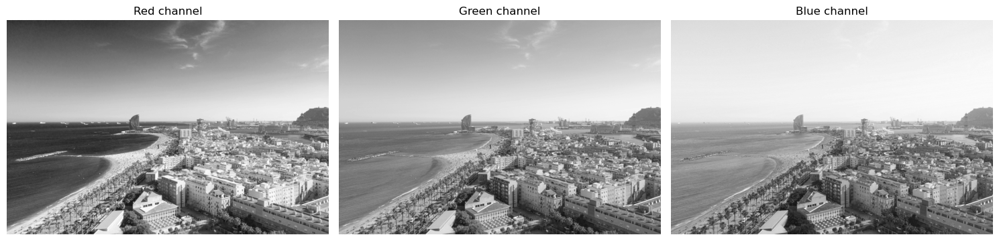

In [24]:
# ----------------------------------------------------------------------------
# 1.5 a) Separar los canales R, G, B de barcelona.jpg
# ----------------------------------------------------------------------------
img_barcelona = io.imread('images_notebook/barcelona.jpg')
print(img_barcelona.shape, img_barcelona.dtype)   # (682, 1024, 3) uint8

# Cada canal es una matriz 2D: [:, :, k] = todas las filas, todas las columnas, canal k
red_channel   = img_barcelona[:, :, 0]
green_channel = img_barcelona[:, :, 1]
blue_channel  = img_barcelona[:, :, 2]

# Se muestran en GRIS: claro = mucha cantidad de ese color en ese píxel.
# (el cielo azul sale claro en el canal azul y más oscuro en el rojo)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ch, t in zip(axes,
                     [red_channel, green_channel, blue_channel],
                     ['Red channel', 'Green channel', 'Blue channel']):
    ax.imshow(ch, cmap='gray', vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

**b) Channel Interchange:** Load the image `images_notebook/chairs.jpg`, interchange its red and blue channels, and display the original and resulting images side by side in a figure with two subplots, titled **Original** and **Red and Blue Channels Interchanged**, respectively.



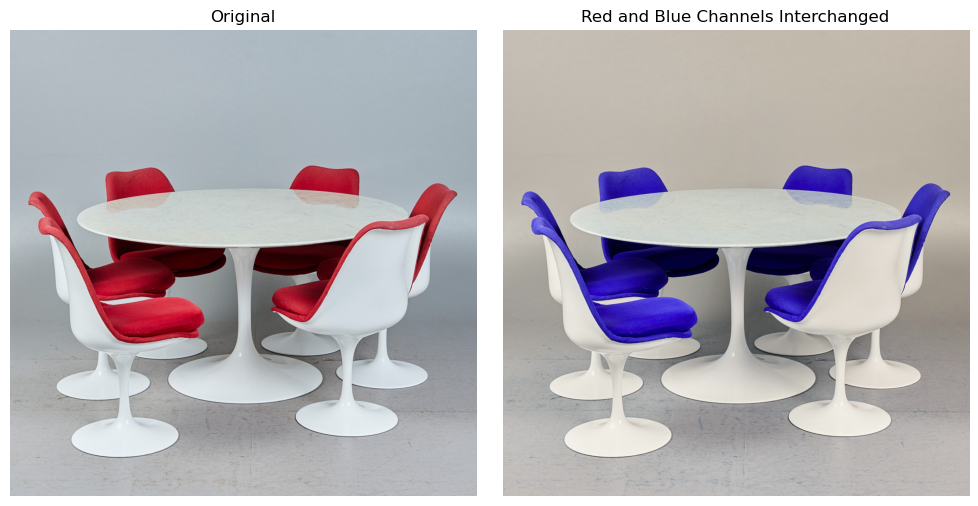

In [25]:
# ----------------------------------------------------------------------------
# 1.5 b) Intercambiar los canales rojo y azul de chairs.jpg
# ----------------------------------------------------------------------------
img_chairs = io.imread('images_notebook/chairs.jpg')

# Escribo en una COPIA y leo de la ORIGINAL.
# TRAMPA: img[:,:,0], img[:,:,2] = img[:,:,2], img[:,:,0] sobre la MISMA imagen NO funciona
# (los slices son vistas: al escribir el canal 0 se pierde el rojo original).
img_chairs_swapped = img_chairs.copy()
img_chairs_swapped[:, :, 0] = img_chairs[:, :, 2]   # R nuevo = B original
img_chairs_swapped[:, :, 2] = img_chairs[:, :, 0]   # B nuevo = R original

# Alternativa en una línea (indexación con lista: reordena los canales):
# img_chairs_swapped = img_chairs[:, :, [2, 1, 0]]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img_chairs);          axes[0].set_title('Original')
axes[1].imshow(img_chairs_swapped);  axes[1].set_title('Red and Blue Channels Interchanged')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### **1.6 Masks and logical image manipulation**

**a) Load the image `images_notebook/circles.bmp` and create three new images, each containing only one of the circles from the original image (as illustrated below).**
- The three circles are located in the following column ranges: **0–299** (left circle), **300–599** (center circle), and **600–the last column of the image** (right circle). 
- Copy and paste each circle from the original image into the corresponding new image, preserving its original position without shifting it. 
- Display the original image and the three resulting images in a single figure, with one subplot for each image and the corresponding title.

<img src="images_notebook/circles2.png">

> **Note:** Be careful when using `imshow()`, as it may automatically adjust the displayed intensity range, making the image appear to have higher contrast than it actually does. Also, take care when converting the image data type. Always check the **data type** and **range of pixel values** before and after the conversion.
he contrast of the image. Also be careful when applying type conversion. Check the ranges of the image values.

(777, 934, 3) uint8 0 255


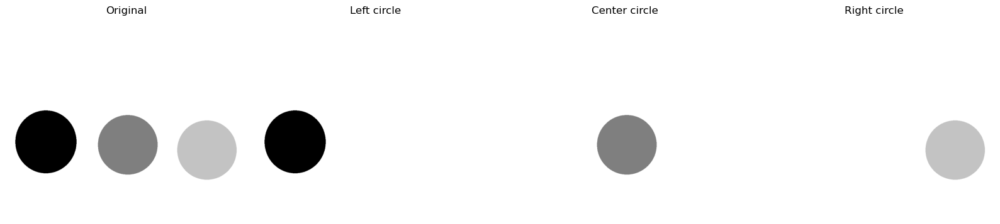

In [26]:
# ----------------------------------------------------------------------------
# 1.6 a) Tres imágenes, cada una con UN solo círculo en su posición original
# ----------------------------------------------------------------------------
img = io.imread('images_notebook/circles.bmp')
# ¡Comprobar siempre! circles.bmp es (777, 934, 3) uint8 aunque se vea gris; fondo BLANCO (255)
print(img.shape, img.dtype, img.min(), img.max())

# Idea: lienzo BLANCO del mismo tamaño y copiar solo la franja de columnas del círculo.
# np.ones_like(img) -> mismo shape y MISMO dtype (uint8) que img, todo a 1. *255 -> blanco.
img_1 = 255 * np.ones_like(img)
img_1[:, :300] = img[:, :300]          # columnas 0..299 -> círculo izquierdo

img_2 = 255 * np.ones_like(img)
img_2[:, 300:600] = img[:, 300:600]    # columnas 300..599 -> círculo central

img_3 = 255 * np.ones_like(img)
img_3[:, 600:] = img[:, 600:]          # columnas 600..final -> círculo derecho

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, im, t in zip(axes,
                     [img, img_1, img_2, img_3],
                     ['Original', 'Left circle', 'Center circle', 'Right circle']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

**b) Create three new images, each containing two of the three circles from the original image while preserving their original positions.**

* The first image must contain the **center and right circles**.
* The second image must contain the **left and right circles**.
* The third image must contain the **left and center circles**.
* Display the three resulting images in a single figure, with one subplot for each image and the corresponding title, as illustrated below.

<img src="images_notebook/circles3.png">



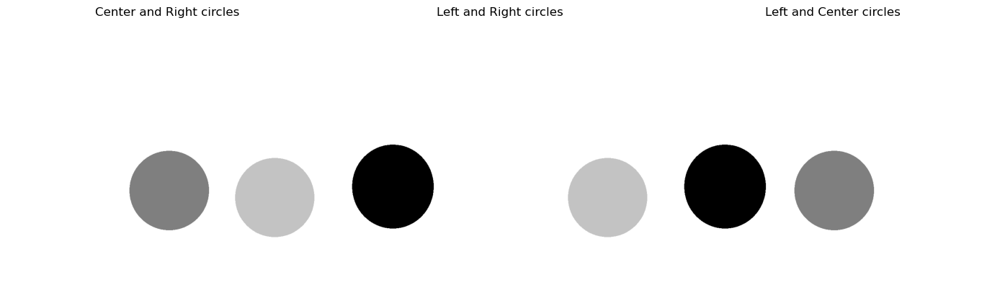

In [27]:
# ----------------------------------------------------------------------------
# 1.6 b) Tres imágenes con DOS círculos cada una
# ----------------------------------------------------------------------------
# Idea inversa: copio la original y BORRO (pongo a blanco) la franja que sobra.
img_1 = img.copy()
img_1[:, :300] = 255        # borro el izquierdo -> quedan centro y derecha

img_2 = img.copy()
img_2[:, 300:600] = 255     # borro el central   -> quedan izquierda y derecha

img_3 = img.copy()
img_3[:, 600:] = 255        # borro el derecho   -> quedan izquierda y centro

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, im, t in zip(axes,
                     [img_1, img_2, img_3],
                     ['Center and Right circles', 'Left and Right circles', 'Left and Center circles']):
    ax.imshow(im, cmap='gray', vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

**c) Load the RGBA image `images_notebook/coat.png` and change the color of the coat by interchanging its red and blue channels, as illustrated below.**

Follow these steps:

1. Load the image and identify the pixels that are **not black**, considering only the RGB channels.
2. Create a copy of the original image.
3. For the selected pixels, interchange the **red and blue channels** while keeping the green and alpha channels unchanged.
4. Display the original and modified images side by side in a figure with two subplots, titled Original and Red and Blue Channels Interchanged, respectively.

> **Note:** Remember that the image has **four channels**: red, green, blue, and alpha (RGBA). When manipulating the color channels, make sure that the **alpha channel remains unchanged**.

> **Important:** Do **not** use a `for` loop to process the pixels individually. Use **NumPy array operations and Boolean masking** to perform the manipulation efficiently.

<img src="images_notebook/coat_changed.png"  width="500">

(1188, 915, 4) uint8
(1188, 915) bool píxeles del abrigo: 108369


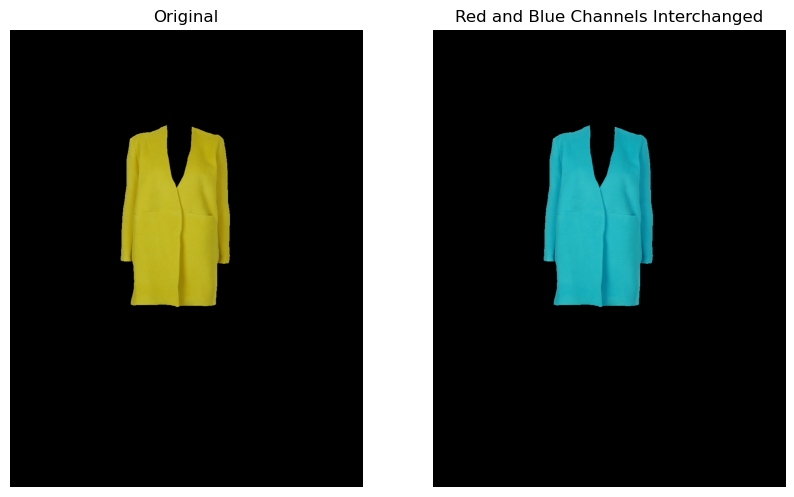

In [28]:
# ----------------------------------------------------------------------------
# 1.6 c) Cambiar el color del abrigo (RGBA) intercambiando R y B, SIN bucles
# ----------------------------------------------------------------------------
img_coat = io.imread('images_notebook/coat.png')
print(img_coat.shape, img_coat.dtype)   # (1188, 915, 4) uint8 -> RGBA (4º canal = alfa)

# 1. Máscara de píxeles NO negros mirando SOLO RGB ([:, :, :3]):
#    img_coat[:, :, :3] != 0      -> bool (h, w, 3): un True/False por canal
#    np.any(..., axis=2)          -> bool (h, w): True si ALGÚN canal es distinto de 0
mask = np.any(img_coat[:, :, :3] != 0, axis=2)
print(mask.shape, mask.dtype, 'píxeles del abrigo:', mask.sum())

# 2. Copia
img_coat_changed = img_coat.copy()

# 3. Indexar con máscara 2D en imagen 3D:
#    img_coat[mask, 2] -> vector 1D con el canal azul de los N píxeles seleccionados
#    Escribo en la copia, leo de la original (si no, se pierde el rojo).
img_coat_changed[mask, 0] = img_coat[mask, 2]    # R <- B
img_coat_changed[mask, 2] = img_coat[mask, 0]    # B <- R
# El canal 1 (G) y el 3 (alfa) no se tocan.

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(img_coat);          axes[0].set_title('Original')
axes[1].imshow(img_coat_changed);  axes[1].set_title('Red and Blue Channels Interchanged')
for ax in axes:
    ax.axis('off')
plt.show()

**d) Overlay the Coat on the Model**

Use the images `images_notebook/model.png`, `images_notebook/coat.png`, and the color-changed coat generated above to overlay the coat onto the model, as illustrated below.

Follow these steps:

1. Load the **model** and **coat** images.

2. Create a mask to identify the **non-black pixels** of the coat, considering only the RGB channels.

3. Create a copy of the model image and overlay the **original coat** onto it using the mask.

4. Create another copy of the model image and overlay the **color-changed coat** (`img_coat_changed`) onto it using the same mask.

5. Display the following four images side by side in a **1×4 grid**:

   * **Coat**
   * **Model**
   * **Model with coat**
   * **Model with changed coat**

6. Hide the axes and add the corresponding titles to each subplot.

> **Note:** Both images have **four channels (RGBA)**. When overlaying the coat, modify only the **RGB channels** (`:3`) and leave the **alpha channel** unchanged.

> **Important:** Do **not** use a `for` loop to process the pixels individually. Use **NumPy array operations and Boolean masking** instead.

<img src="images_notebook/model_changed.png"  width="900">

(1188, 915, 4) (1188, 915, 4)


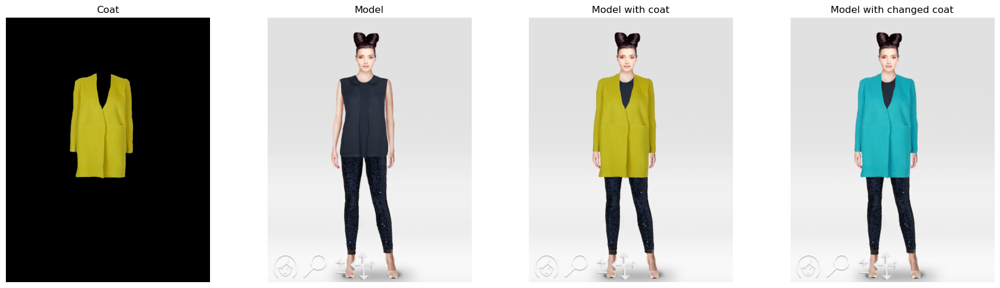

In [29]:
# ----------------------------------------------------------------------------
# 1.6 d) Superponer el abrigo (original y cambiado) sobre la modelo
# ----------------------------------------------------------------------------
img_model = io.imread('images_notebook/model.png')
img_coat  = io.imread('images_notebook/coat.png')
print(img_model.shape, img_coat.shape)   # ambas (1188, 915, 4) -> MISMO tamaño: la máscara sirve para las dos

# 2. Máscara del abrigo (píxeles no negros, solo RGB)
mask = np.any(img_coat[:, :, :3] > 0, axis=2)

# 3. Modelo + abrigo original:
#    img[mask, :3] -> (N, 3): los N píxeles seleccionados, canales R,G,B (sin alfa)
#    "donde hay abrigo, pon los colores del abrigo"; el alfa de la modelo no se toca
img_model_coat = img_model.copy()
img_model_coat[mask, :3] = img_coat[mask, :3]

# 4. Modelo + abrigo cambiado de color (de 1.6c), misma máscara
img_model_coat_changed = img_model.copy()
img_model_coat_changed[mask, :3] = img_coat_changed[mask, :3]

# Alternativa con np.where (elige entre dos imágenes según la máscara):
# m3 = mask[:, :, None]                                    # (h,w) -> (h,w,1) para que "case" con (h,w,3)
# rgb = np.where(m3, img_coat[:, :, :3], img_model[:, :, :3])

# 5-6. 1x4 subplots
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, im, t in zip(axes,
                     [img_coat, img_model, img_model_coat, img_model_coat_changed],
                     ['Coat', 'Model', 'Model with coat', 'Model with changed coat']):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

---
# 🧪 BANCO DE EJERCICIOS TIPO EXAMEN (P1)

Todos están **resueltos y comentados**. Cada celda es **autónoma**: carga sus propias imágenes, así que puedes copiarla al examen y adaptarla.

| Bloque | Tema |
|---|---|
| **A** | Crear imágenes sintéticas (franjas, cuadrados, cruces, tableros, degradados, banderas, círculos) |
| **B** | Tipos de datos: `uint8`/`float`, overflow, conversiones |
| **C** | Slicing y geometría: recortar, voltear, rotar, mosaicos, marcos, centrar |
| **D** | Leer y guardar imágenes |
| **E** | Color: canales, permutaciones, gris, RGBA |
| **F** | Máscaras booleanas y umbralización |
| **G** | Brillo y contraste |
| **H** | Cambiar tamaño: `rescale` / `resize` |
| **I** | Visualización (subplots, vmin/vmax, histogramas) |
| **J** | Preguntas teóricas cortas |

### ⚡ Chuleta rápida
```python
img.shape, img.dtype, img.min(), img.max()        # IMPRIMIR SIEMPRE
np.zeros((h, w), dtype=np.uint8)                   # gris negra
np.zeros((h, w, 3), dtype=np.uint8)                # RGB negra
img[f, c]  ->  (fila=y, columna=x)                 # fila 0 = arriba
img[:, :, 0]  R   img[:, :, 1]  G   img[:, :, 2]  B   img[:, :, 3] alfa
img[::-1, :] vertical   img[:, ::-1] horizontal   np.rot90(img)
rgb2gray(img)        -> float64 [0,1], quita canales
img_as_ubyte(f)      -> float [0,1] a uint8 [0,255]   (NO usar astype(np.uint8))
img_as_float(u)      -> uint8 a float [0,1]
x.astype(float)      -> cambia tipo SIN reescalar
uint8: 10-50 = 216 y 250+10 = 4 (wrap-around) -> usar float/int16 + np.clip
mask = np.any(img[:, :, :3] != 0, axis=2)         # píxel no negro (2D)
img[mask] = [255, 0, 0]                            # pintar píxeles de la máscara
dst[mask, :3] = src[mask, :3]                      # copiar píxeles de una imagen a otra
plt.imshow(g, cmap='gray', vmin=0, vmax=255)       # uint8 (vmax=1 si float [0,1])
fig, axes = plt.subplots(1, 3, figsize=(12, 4)); axes[i].set_title('..'); ax.axis('off')
```

In [30]:
# ============================================================================
# SETUP DEL BANCO (ejecutar primero). Imports + 2 funciones de ayuda.
# ============================================================================
import os
import numpy as np
from matplotlib import pyplot as plt
from skimage import io, data
from skimage.color import rgb2gray, rgba2rgb, gray2rgb
from skimage.util import img_as_ubyte, img_as_float
from skimage.exposure import rescale_intensity
from skimage.transform import rescale, resize

IMG = 'images_notebook/'         # carpeta de imágenes (al lado de este notebook)
os.makedirs('output', exist_ok=True)

def info(nombre, im):
    """Imprime lo que SIEMPRE hay que comprobar: shape, dtype, min, max."""
    print(f'{nombre:20s} shape={im.shape} dtype={im.dtype} min={im.min()} max={im.max()}')

def mostrar(imagenes, titulos=None, vmax=None, figsize=None):
    """Muestra una lista de imágenes en una fila de subplots sin ejes.
    vmax=None -> autoescala; vmax=255 o 1 -> rango real (gris)."""
    n = len(imagenes)
    fig, axes = plt.subplots(1, n, figsize=figsize or (4 * n, 4))
    axes = np.atleast_1d(axes)                 # si n == 1, axes no es array -> lo convierto
    for i, (ax, im) in enumerate(zip(axes, imagenes)):
        if vmax is None:
            ax.imshow(im, cmap='gray')
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=vmax)
        if titulos:
            ax.set_title(titulos[i])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

---
## A. Crear imágenes sintéticas

### A1. Imagen blanca de tres formas
Crea una imagen gris 100×100 `uint8` **blanca** de tres formas distintas. Comprueba que las tres son iguales.

True True
a                    shape=(100, 100) dtype=uint8 min=255 max=255


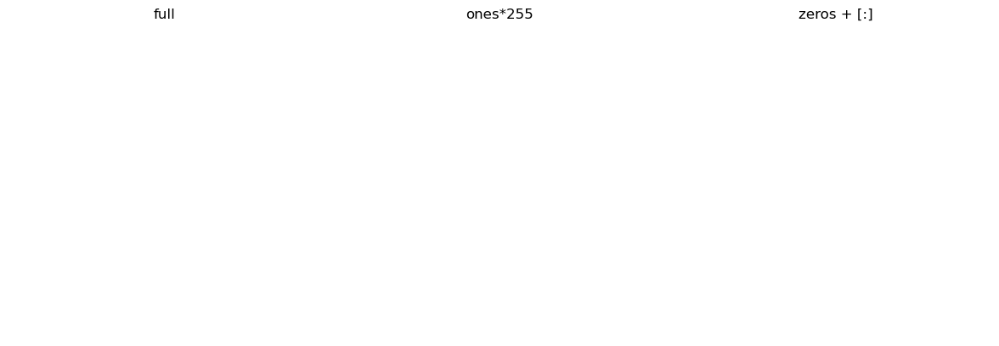

In [31]:
a = np.full((100, 100), 255, dtype=np.uint8)        # 1) full: todo a un valor concreto
b = 255 * np.ones((100, 100), dtype=np.uint8)       # 2) ones * 255 (sigue siendo uint8)
c = np.zeros((100, 100), dtype=np.uint8); c[:] = 255  # 3) zeros y asignar a TODO ([:] = todos)

print(np.array_equal(a, b), np.array_equal(a, c))   # True True
info('a', a)
mostrar([a, b, c], ['full', 'ones*255', 'zeros + [:]'], vmax=255)

### A2. Franjas verticales de grises
Imagen 200×200 `uint8` con **4 franjas verticales** de 50 columnas con intensidades 0, 85, 170 y 255.

[  0  85 170 255]


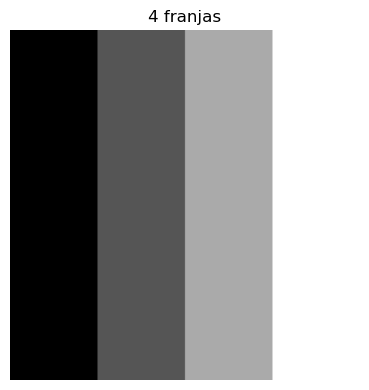

In [32]:
img = np.zeros((200, 200), dtype=np.uint8)
valores = [0, 85, 170, 255]
for i, v in enumerate(valores):            # bucle sobre FRANJAS (4 iteraciones), no sobre píxeles
    img[:, i*50:(i+1)*50] = v              # todas las filas, columnas de la franja i
# Sin bucle: img[:] = np.repeat(valores, 50)  -> fila de 200 valores repetida en todas las filas
print(img[0, ::50])                        # [  0  85 170 255]
mostrar([img], ['4 franjas'], vmax=255)

### A3. Rayas horizontales alternas
Imagen 100×100 negra con **rayas horizontales blancas de 10 píxeles** alternadas (blanca, negra, blanca...).

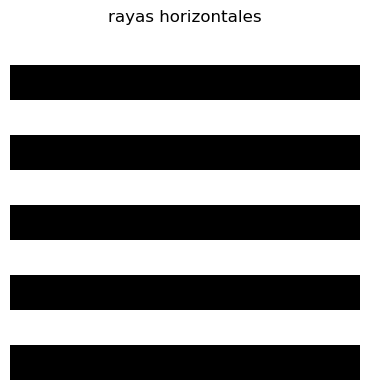

In [33]:
img = np.zeros((100, 100), dtype=np.uint8)
for f in range(0, 100, 20):        # empieza una raya blanca cada 20 filas (10 blancas + 10 negras)
    img[f:f+10, :] = 255
# Rayas de 1 píxel (filas pares) sin bucle: img[::2, :] = 255   (paso 2 en filas)
# Rayas VERTICALES: lo mismo pero en columnas -> img[:, f:f+10] = 255
mostrar([img], ['rayas horizontales'], vmax=255)

### A4. Marco (borde) blanco
Imagen 100×100 negra con un **borde blanco de 10 píxeles** alrededor.

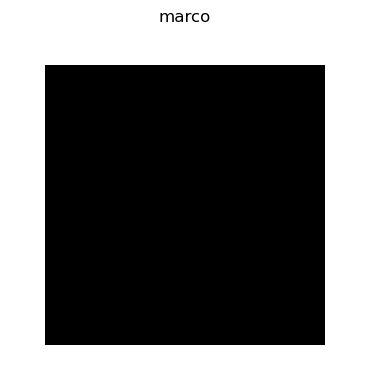

In [34]:
img = np.zeros((100, 100), dtype=np.uint8)
g = 10
img[:g, :]  = 255     # borde superior: primeras 10 filas
img[-g:, :] = 255     # borde inferior: últimas 10 filas (índice negativo = desde el final)
img[:, :g]  = 255     # borde izquierdo
img[:, -g:] = 255     # borde derecho
# Alternativa: todo blanco y "vaciar" el interior -> img[:] = 255; img[g:-g, g:-g] = 0
mostrar([img], ['marco'], vmax=255)

### A5. Cuadrado centrado y cruz centrada
Imagen 100×100 negra con (a) un **cuadrado blanco de 40×40 centrado**; (b) otra con una **cruz** de grosor 10 centrada.

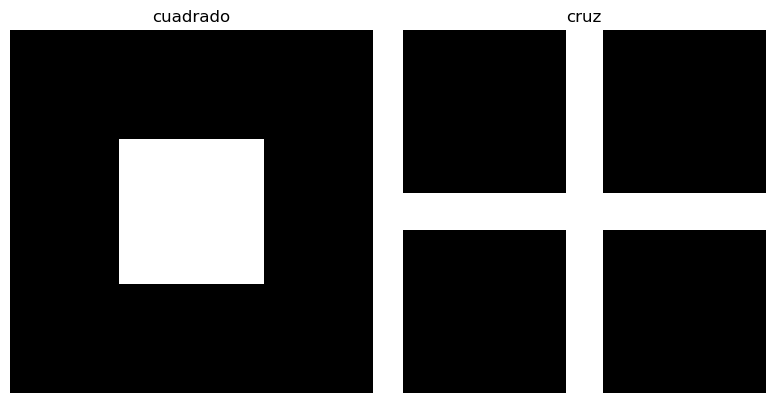

In [35]:
H, W = 100, 100
# (a) cuadrado: la esquina sup-izq está en (H-40)//2
lado = 40
r0, c0 = (H - lado) // 2, (W - lado) // 2        # 30, 30
cuadrado = np.zeros((H, W), dtype=np.uint8)
cuadrado[r0:r0+lado, c0:c0+lado] = 255           # filas 30..69, columnas 30..69

# (b) cruz: franja horizontal + franja vertical centradas
g = 10
cruz = np.zeros((H, W), dtype=np.uint8)
cruz[H//2 - g//2 : H//2 + g//2, :] = 255         # filas 45..54
cruz[:, W//2 - g//2 : W//2 + g//2] = 255         # columnas 45..54
mostrar([cuadrado, cruz], ['cuadrado', 'cruz'], vmax=255)

### A6. Tablero de ajedrez
Tablero de ajedrez 200×200 con casillas de 25×25 (8×8 casillas). Hazlo (a) con bucles sobre casillas y (b) sin bucles.

True True


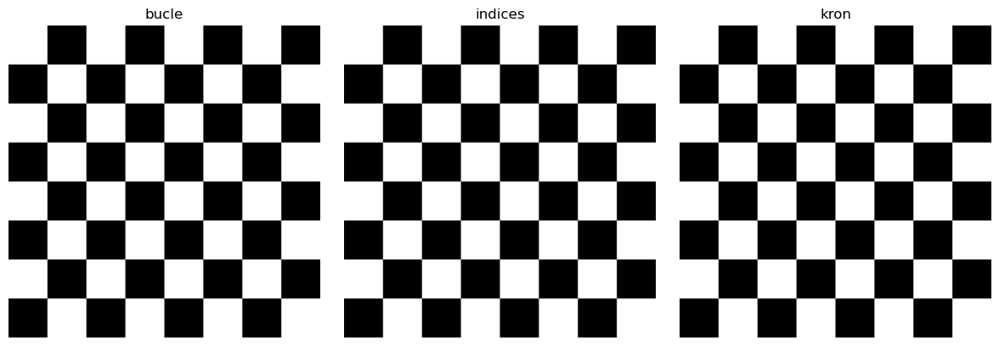

In [36]:
N, t = 8, 25
# (a) bucle sobre CASILLAS (64 iteraciones): blanca si (fila + col) es par
tab = np.zeros((N*t, N*t), dtype=np.uint8)
for i in range(N):
    for j in range(N):
        if (i + j) % 2 == 0:
            tab[i*t:(i+1)*t, j*t:(j+1)*t] = 255

# (b) sin bucles: np.indices da la fila y la columna de cada píxel
filas, cols = np.indices((N*t, N*t))              # dos matrices 200x200
tab2 = (((filas // t) + (cols // t)) % 2 == 0).astype(np.uint8) * 255

# (c) con np.kron: tablero 8x8 de 0/1 "ampliado" con bloques de 25x25 de unos
peq = (np.indices((N, N)).sum(axis=0) % 2 == 0).astype(np.uint8)
tab3 = np.kron(peq, np.ones((t, t), dtype=np.uint8)) * 255

print(np.array_equal(tab, tab2), np.array_equal(tab, tab3))
mostrar([tab, tab2, tab3], ['bucle', 'indices', 'kron'], vmax=255)

### A7. Diagonales
Imagen 100×100 negra con la **diagonal principal** blanca y otra con **las dos diagonales** (una X).

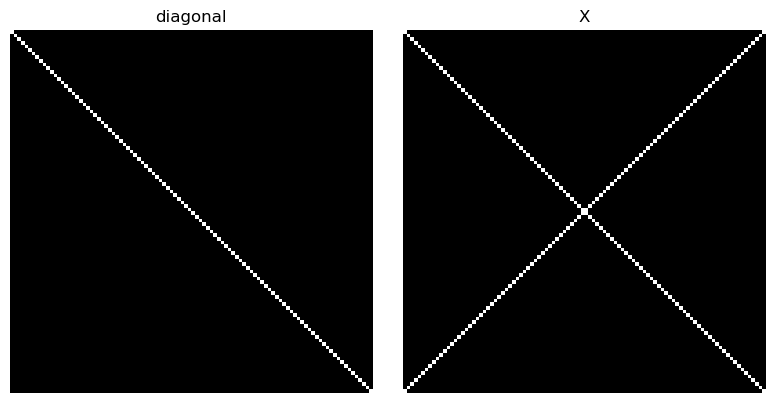

In [37]:
diag = (np.eye(100) * 255).astype(np.uint8)       # np.eye = matriz identidad (1 en la diagonal)
x = diag.copy()
x[np.fliplr(np.eye(100)) == 1] = 255              # antidiagonal = identidad volteada horizontalmente
# Alternativa: idx = np.arange(100); img[idx, idx] = 255; img[idx, 99-idx] = 255
mostrar([diag, x], ['diagonal', 'X'], vmax=255)

### A8. Degradados
Crea (a) un degradado **horizontal** 100×256 (columna j vale j) y (b) uno **vertical** 256×100, ambos `uint8`.

h                    shape=(100, 256) dtype=uint8 min=0 max=255
v                    shape=(256, 100) dtype=uint8 min=0 max=255


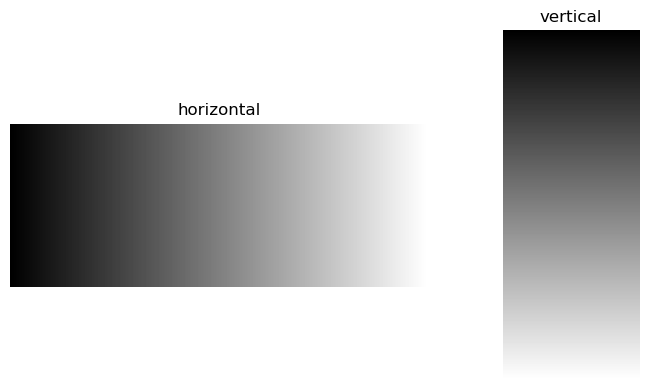

In [38]:
fila = np.arange(256, dtype=np.uint8)          # [0, 1, ..., 255]
# (a) horizontal: la misma fila repetida 100 veces
h = np.tile(fila, (100, 1))                    # tile repite: 100 veces en filas, 1 en columnas
# alternativa: h = np.zeros((100, 256), np.uint8); h[:] = fila   (broadcasting)
# (b) vertical: la traspuesta (filas <-> columnas)
v = h.T.copy()
# Con linspace (n valores entre a y b): np.linspace(0, 255, 300).astype(np.uint8)
info('h', h); info('v', v)
mostrar([h, v], ['horizontal', 'vertical'], vmax=255)

### A9. Imágenes RGB de colores sólidos y cuadrantes
(a) Imagen 100×100 RGB **naranja** `[255, 128, 0]`. (b) Imagen 200×200 con 4 cuadrantes: rojo, verde, azul y blanco.

[255   0   0] [255 255 255]


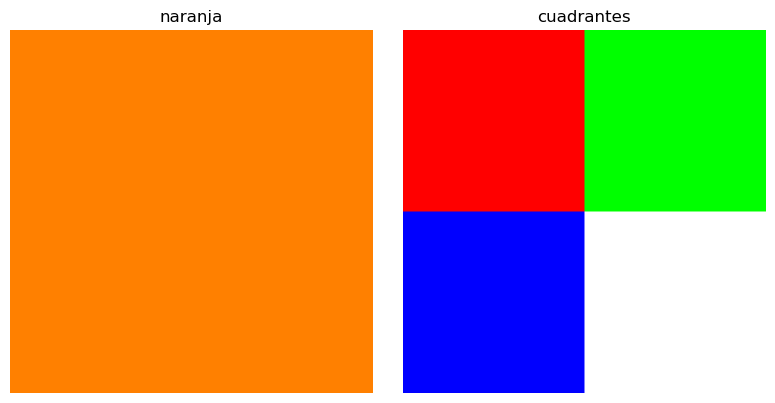

In [39]:
nar = np.zeros((100, 100, 3), dtype=np.uint8)
nar[:, :] = [255, 128, 0]          # broadcasting: la lista de 3 se copia en cada píxel

cua = np.zeros((200, 200, 3), dtype=np.uint8)
cua[:100, :100] = [255, 0, 0]      # sup-izq rojo
cua[:100, 100:] = [0, 255, 0]      # sup-der verde
cua[100:, :100] = [0, 0, 255]      # inf-izq azul
cua[100:, 100:] = [255, 255, 255]  # inf-der blanco
print(cua[0, 0], cua[150, 150])
mostrar([nar, cua], ['naranja', 'cuadrantes'])

### A10. Banderas
Crea (a) la bandera de **Italia** (3 franjas verticales verde/blanco/rojo, 150×300) y (b) la **senyera** (9 franjas horizontales alternas amarillo/rojo empezando por amarillo, 180×270).

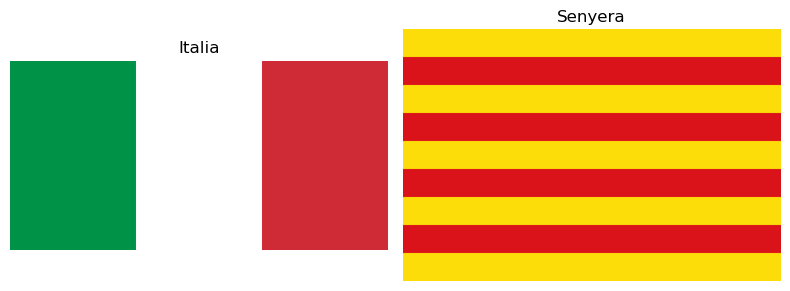

In [40]:
# (a) Italia
it = np.zeros((150, 300, 3), dtype=np.uint8)
it[:, :100]    = [0, 146, 70]       # verde
it[:, 100:200] = [255, 255, 255]    # blanco
it[:, 200:]    = [206, 43, 55]      # rojo

# (b) Senyera: 9 franjas de 20 filas; pares amarillas, impares rojas
sen = np.zeros((180, 270, 3), dtype=np.uint8)
for k in range(9):
    color = [252, 221, 9] if k % 2 == 0 else [218, 18, 26]
    sen[k*20:(k+1)*20, :] = color
mostrar([it, sen], ['Italia', 'Senyera'])

### A11. Círculo con máscara
Imagen 200×200 negra con un **círculo blanco** de radio 50 centrado. Después pon un círculo **rojo** sobre fondo blanco en RGB.

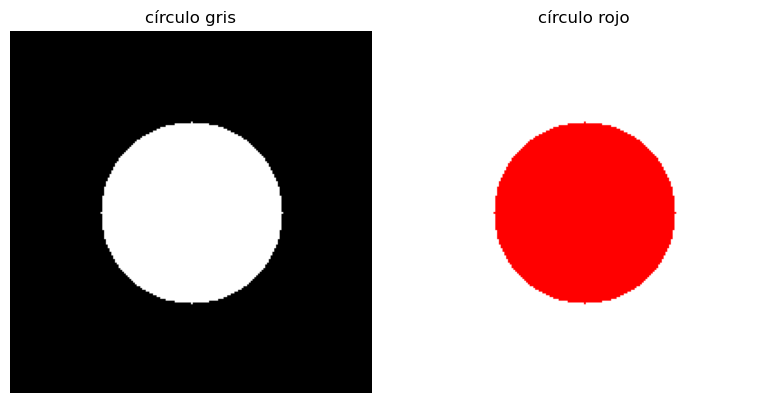

In [41]:
H, W = 200, 200
filas, cols = np.indices((H, W))                    # coordenada (y, x) de cada píxel
cy, cx, r = H // 2, W // 2, 50
dentro = (filas - cy)**2 + (cols - cx)**2 <= r**2   # ecuación del círculo -> máscara bool

circ = np.zeros((H, W), dtype=np.uint8)
circ[dentro] = 255

rgb = np.full((H, W, 3), 255, dtype=np.uint8)       # fondo blanco
rgb[dentro] = [255, 0, 0]                           # píxeles dentro -> rojo
mostrar([circ, rgb], ['círculo gris', 'círculo rojo'], vmax=255)

### A12. Imagen de la P1 1.1d con otras posiciones
Desde una imagen 100×100 negra crea: (1) mitad **izquierda** blanca, (2) mitad **superior** blanca, (3) cuadrante **inferior derecho** blanco. Combínalas como canales **B, R, G** respectivamente y explica los colores.

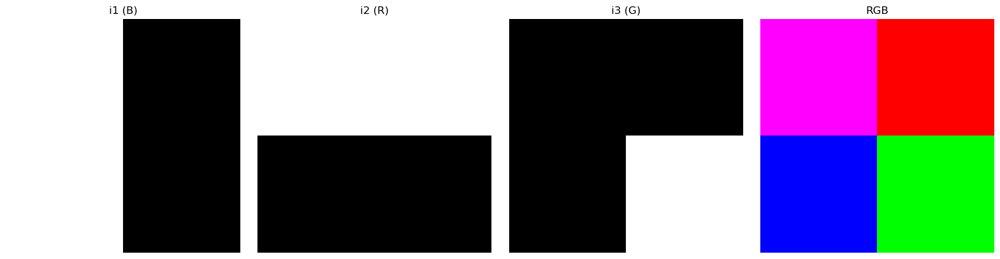

In [42]:
base = np.zeros((100, 100), dtype=np.uint8)
i1 = base.copy(); i1[:, :50] = 255     # izquierda
i2 = base.copy(); i2[:50, :] = 255     # superior
i3 = base.copy(); i3[50:, 50:] = 255   # inferior derecho

rgb = np.zeros((100, 100, 3), dtype=np.uint8)
rgb[:, :, 2] = i1    # B
rgb[:, :, 0] = i2    # R
rgb[:, :, 1] = i3    # G
# sup-izq: R+B = magenta | sup-der: R = rojo | inf-izq: B = azul | inf-der: G = verde
mostrar([i1, i2, i3, rgb], ['i1 (B)', 'i2 (R)', 'i3 (G)', 'RGB'], vmax=255)

### A13. Rejilla de líneas
Imagen 200×200 negra con **líneas blancas horizontales y verticales cada 20 píxeles** (1 píxel de grosor).

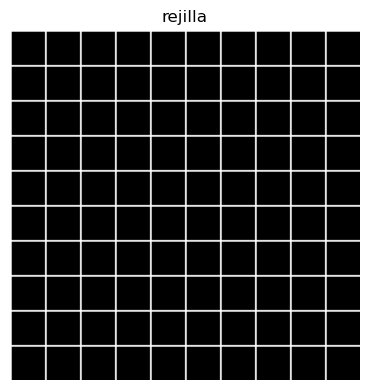

In [43]:
img = np.zeros((200, 200), dtype=np.uint8)
img[::20, :] = 255          # filas 0, 20, 40, ... (paso 20) -> líneas horizontales
img[:, ::20] = 255          # columnas 0, 20, 40, ... -> líneas verticales
# Si quieres que también aparezca la última línea (fila 199): img[-1, :] = 255; img[:, -1] = 255
mostrar([img], ['rejilla'], vmax=255)

### A14. Cuadrados concéntricos
Imagen 200×200 con **cuadrados concéntricos** alternando blanco y negro, cada anillo de 20 píxeles de grosor.

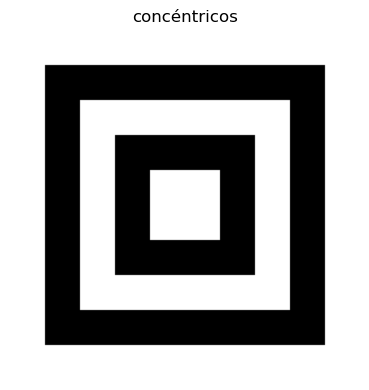

In [44]:
img = np.zeros((200, 200), dtype=np.uint8)
for k in range(0, 100, 20):                       # k = margen desde el borde: 0, 20, 40, 60, 80
    valor = 255 if (k // 20) % 2 == 0 else 0      # alterno blanco / negro
    img[k:200-k, k:200-k] = valor                 # cada cuadrado más pequeño tapa el centro del anterior
mostrar([img], ['concéntricos'], vmax=255)

### A15. Triángulos
Imagen 100×100 con el **triángulo inferior izquierdo** blanco (por debajo de la diagonal) y otra con el **superior derecho**.

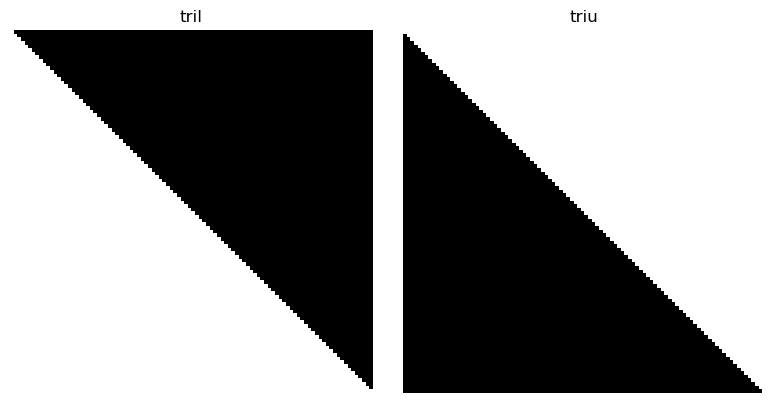

In [45]:
inf = (np.tril(np.ones((100, 100))) * 255).astype(np.uint8)   # tril = "triangular lower": unos bajo la diagonal
sup = (np.triu(np.ones((100, 100))) * 255).astype(np.uint8)   # triu = "triangular upper"
# Sin funciones: f, c = np.indices((100, 100)); inf = (f >= c)  -> True donde fila >= columna
mostrar([inf, sup], ['tril', 'triu'], vmax=255)

### A16. Anillo (círculo hueco)
Imagen 200×200 negra con un **anillo** blanco de radio exterior 80 e interior 50, centrado.

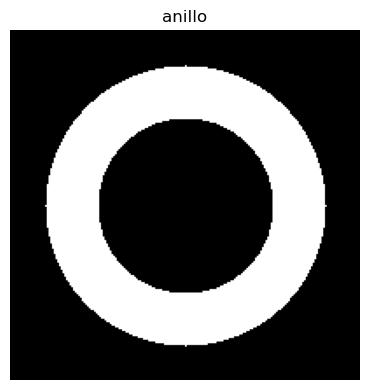

In [46]:
f, c = np.indices((200, 200))
d2 = (f - 100)**2 + (c - 100)**2               # distancia al centro AL CUADRADO (evito la raíz)
anillo = (d2 <= 80**2) & (d2 >= 50**2)         # dentro del grande Y fuera del pequeño
img = anillo.astype(np.uint8) * 255
mostrar([img], ['anillo'], vmax=255)

### A17. Cuadrantes con 4 grises
Imagen 200×200 `uint8` con los 4 cuadrantes de intensidades 0 (sup-izq), 85 (sup-der), 170 (inf-izq) y 255 (inf-der). Imprime el valor central de cada cuadrante.

0 85 170 255


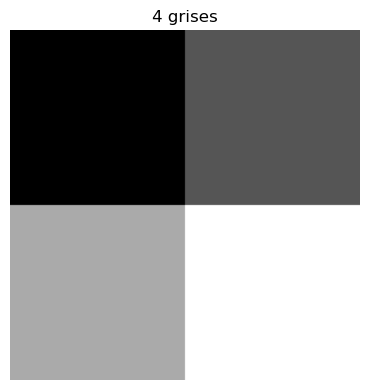

In [47]:
img = np.zeros((200, 200), dtype=np.uint8)
img[:100, 100:] = 85
img[100:, :100] = 170
img[100:, 100:] = 255
print(img[50, 50], img[50, 150], img[150, 50], img[150, 150])   # 0 85 170 255
mostrar([img], ['4 grises'], vmax=255)

### A18. Degradado de color 2D
Imagen RGB 256×256 donde el **rojo** crece de izquierda a derecha (0→255) y el **azul** de arriba a abajo; verde a 0.

[0 0 0] [255   0   0] [  0   0 255] [255   0 255]


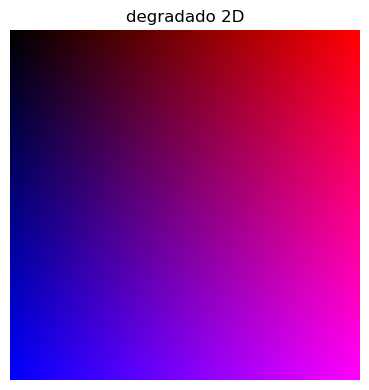

In [48]:
img = np.zeros((256, 256, 3), dtype=np.uint8)
v = np.arange(256, dtype=np.uint8)
img[:, :, 0] = v[np.newaxis, :]      # (1, 256): la misma fila en todas las filas -> varía por columna
img[:, :, 2] = v[:, np.newaxis]      # (256, 1): la misma columna en todas las columnas -> varía por fila
print(img[0, 0], img[0, 255], img[255, 0], img[255, 255])   # negro, rojo, azul, magenta
mostrar([img], ['degradado 2D'])

### A19. Rectángulo en una posición dada y su contorno
Imagen 150×200 negra. Dibuja un rectángulo blanco **relleno** con esquina superior izquierda en (fila 20, col 30), de 40 de alto y 60 de ancho. En otra, solo su **contorno** de 2 píxeles.

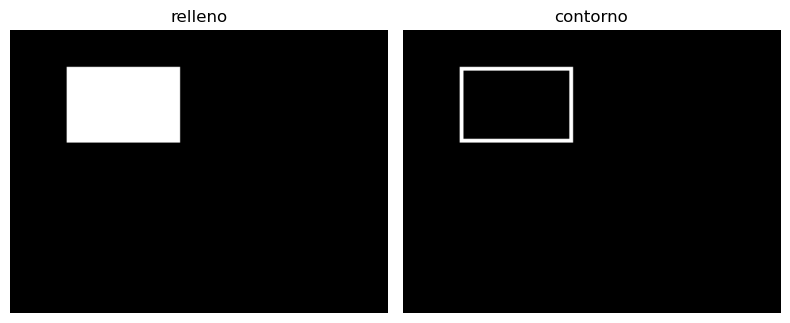

In [49]:
r, c, h, w = 20, 30, 40, 60
relleno = np.zeros((150, 200), dtype=np.uint8)
relleno[r:r+h, c:c+w] = 255

contorno = relleno.copy()
g = 2
contorno[r+g:r+h-g, c+g:c+w-g] = 0           # vacío el interior dejando g píxeles de borde
mostrar([relleno, contorno], ['relleno', 'contorno'], vmax=255)

---
## B. Tipos de datos y overflow

### B1. Niveles y rangos de cada tipo
¿Cuántos niveles distintos y qué rango tienen `uint8`, `uint16`, `int8` y `bool`? Calcúlalo con código.

In [50]:
for t in (np.uint8, np.uint16, np.int8, np.int16):
    i = np.iinfo(t)                                   # información de un tipo ENTERO
    print(f'{t.__name__:7s} rango [{i.min}, {i.max}]  niveles = {i.max - i.min + 1} = 2**{i.bits}')
print('bool    niveles = 2 (False/True)')
print('float64 ->', np.finfo(np.float64).eps, '(paso mínimo cerca de 1; "infinitos" niveles)')

uint8   rango [0, 255]  niveles = 256 = 2**8
uint16  rango [0, 65535]  niveles = 65536 = 2**16
int8    rango [-128, 127]  niveles = 256 = 2**8
int16   rango [-32768, 32767]  niveles = 65536 = 2**16
bool    niveles = 2 (False/True)
float64 -> 2.220446049250313e-16 (paso mínimo cerca de 1; "infinitos" niveles)


### B2. Predecir overflow
Sin ejecutar, predice el resultado de cada operación sobre `a = np.array([10, 100, 250], dtype=np.uint8)`. Después compruébalo.

In [51]:
a = np.array([10, 100, 250], dtype=np.uint8)
print(a + 10)      # [ 20 110   4]   250+10 = 260 -> 260-256 = 4
print(a - 20)      # [246  80 230]   10-20 = -10 -> -10+256 = 246
print(a * 2)       # [ 20 200 244]   250*2 = 500 -> 500-256 = 244
print(a // 3)      # [ 3 33 83]      división entera, sigue uint8
print(a / 2)       # [  5.  50. 125.] '/' SIEMPRE da float64
print(255 - a)     # [245 155   5]   negativo: nunca hace overflow
print((a + 10).dtype, (a / 2).dtype)
# Regla: uint8 hace aritmética MÓDULO 256 (da la vuelta).

[ 20 110   4]
[246  80 230]
[ 20 200 244]
[ 3 33 83]
[  5.  50. 125.]
[245 155   5]
uint8 float64


### B3. Sumar sin overflow (saturar)
Suma 100 a `cell_lowcontrast2.png` (a) directamente y (b) saturando a 255. Muestra ambas y explica.

directo              shape=(898, 1181) dtype=uint8 min=0 max=255
saturado             shape=(898, 1181) dtype=uint8 min=180 max=255


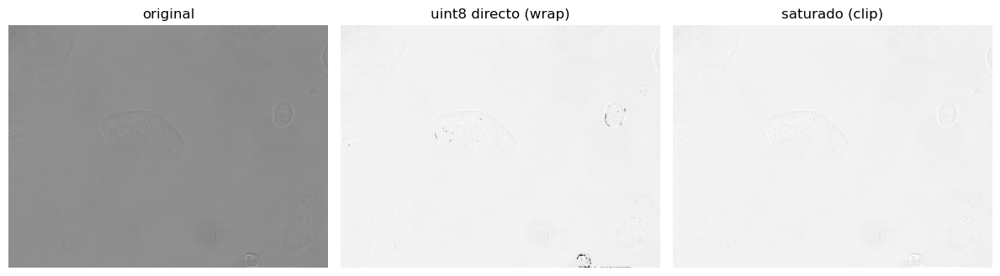

In [52]:
cell = io.imread(IMG + 'cell_lowcontrast2.png')
a = cell + 100                                                   # 181+100 = 281 -> 25 (¡oscuro!)
b = np.clip(cell.astype(np.int16) + 100, 0, 255).astype(np.uint8)  # int16 admite >255; clip recorta
# Otra forma: b = np.clip(cell.astype(float) + 100, 0, 255).astype(np.uint8)
info('directo', a); info('saturado', b)
mostrar([cell, a, b], ['original', 'uint8 directo (wrap)', 'saturado (clip)'], vmax=255)

### B4. Media de dos imágenes (trampa)
Calcula la imagen media de `panda.jpg` y su versión volteada horizontalmente. ¿Por qué `(a + b) / 2` da un resultado raro en uint8?

mal                  shape=(800, 1200, 3) dtype=float64 min=0.0 max=127.5
bien                 shape=(800, 1200, 3) dtype=uint8 min=0 max=255


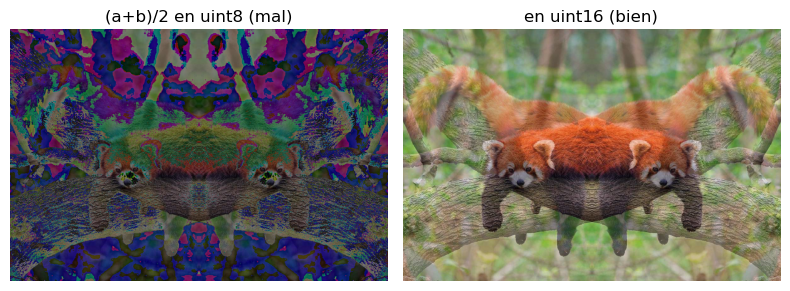

In [53]:
a = io.imread(IMG + 'panda.jpg')
b = a[:, ::-1]                               # volteo horizontal
mal  = (a + b) / 2                           # a+b se calcula en uint8 -> overflow ANTES de dividir
bien = ((a.astype(np.uint16) + b) / 2).astype(np.uint8)    # sumo en un tipo más grande
# o: bien = ((a.astype(float) + b) / 2).astype(np.uint8)
info('mal', mal); info('bien', bien)
mostrar([mal.astype(np.uint8), bien], ['(a+b)/2 en uint8 (mal)', 'en uint16 (bien)'])

### B5. astype vs img_as_*
Convierte `[0, 128, 255]` uint8 a float de dos formas y vuelve a uint8 de dos formas. Explica las diferencias.

In [54]:
u = np.array([0, 128, 255], dtype=np.uint8)
f1 = u.astype(float)        # [  0. 128. 255.]   cambia tipo, NO reescala
f2 = img_as_float(u)        # [0.    0.502 1.   ] cambia tipo y divide entre 255
print(f1, f2)

print(f2.astype(np.uint8))  # [0 0 1]     ¡trunca decimales! -> imagen casi negra
print(img_as_ubyte(f2))     # [  0 128 255] multiplica por 255 y redondea -> CORRECTO
print(f1.astype(np.uint8))  # [  0 128 255] aquí sí vale porque f1 ya estaba en 0..255

try:
    img_as_ubyte(f1)        # f1 tiene valores >1 -> ERROR: img_as_ubyte exige float en [-1, 1]
except ValueError as e:
    print('ERROR:', e)

[  0. 128. 255.] [0.         0.50196078 1.        ]
[0 0 1]
[  0 128 255]
[  0 128 255]
ERROR: Images of type float must be between -1 and 1.


### B6. ¿Qué dtype devuelve cada función?
Imprime el dtype y rango de lo que devuelve cada función habitual partiendo de una imagen `uint8`.

In [55]:
p = io.imread(IMG + 'panda.jpg')
g = rgb2gray(p)
pruebas = {
    'io.imread'                 : p,
    'rgb2gray'                  : g,
    'img_as_ubyte(gray)'        : img_as_ubyte(g),
    'img_as_float(uint8)'       : img_as_float(p),
    'p / 2'                     : p / 2,
    'p // 2'                    : p // 2,
    'p > 100'                   : p > 100,
    'rescale(g, .5)'            : rescale(g, 0.5),
    'resize(p, (50,50))'        : resize(p, (50, 50)),
    'resize(.., preserve_range)': resize(p, (50, 50), preserve_range=True),
    'rescale_intensity(uint8)'  : rescale_intensity(p),
    'p.mean()'                  : np.array(p.mean()),
}
for k, v in pruebas.items():
    print(f'{k:28s} {str(v.dtype):8s} [{v.min():.3f}, {v.max():.3f}]')

io.imread                    uint8    [0.000, 255.000]
rgb2gray                     float64  [0.000, 1.000]
img_as_ubyte(gray)           uint8    [0.000, 255.000]
img_as_float(uint8)          float64  [0.000, 1.000]
p / 2                        float64  [0.000, 127.500]
p // 2                       uint8    [0.000, 127.000]
p > 100                      bool     [0.000, 1.000]
rescale(g, .5)               float64  [0.003, 0.999]
resize(p, (50,50))           float64  [0.038, 0.961]
resize(.., preserve_range)   float64  [9.606, 245.059]
rescale_intensity(uint8)     uint8    [0.000, 255.000]
p.mean()                     float64  [120.657, 120.657]


### B7. Imagen binaria a uint8 para guardarla
Binariza el panda (gris > 0.5) y conviértelo a `uint8` con valores **0 y 255** de dos formas.

In [56]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))
b = g > 0.5                                   # bool
u1 = b.astype(np.uint8) * 255                 # True->1->255
u2 = img_as_ubyte(b)                          # img_as_ubyte también acepta bool -> 0/255
print(b.dtype, np.unique(u1), np.unique(u2), np.array_equal(u1, u2))
io.imsave('output/panda_bin.png', u1)

bool [  0 255] [  0 255] True


### B8. Convertir uint16 a uint8
Crea una imagen `uint16` con valores de 0 a 65535 (degradado 100×256) y pásala correctamente a `uint8` de dos formas.

u16                  shape=(100, 256) dtype=uint16 min=0 max=65535
//256                shape=(100, 256) dtype=uint8 min=0 max=255
img_as_ubyte         shape=(100, 256) dtype=uint8 min=0 max=255
astype (mal)         shape=(100, 256) dtype=uint8 min=0 max=255


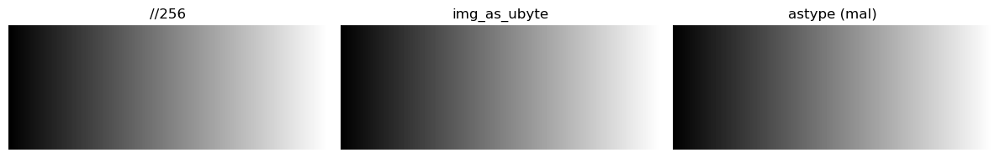

In [57]:
u16 = np.tile(np.linspace(0, 65535, 256).astype(np.uint16), (100, 1))
a = (u16 // 256).astype(np.uint8)          # 65535 // 256 = 255 -> divido por 2^8 (me quedo con los 8 bits altos)
b = img_as_ubyte(u16)                      # skimage reescala del rango uint16 al de uint8
c = u16.astype(np.uint8)                   # MAL: se queda con u16 % 256 -> valores "en sierra"
info('u16', u16); info('//256', a); info('img_as_ubyte', b); info('astype (mal)', c)
mostrar([a, b, c], ['//256', 'img_as_ubyte', 'astype (mal)'], vmax=255)

### B9. Diferencia entre dos imágenes (trampa)
Calcula la diferencia absoluta entre el panda y el panda aclarado (+30 saturado). ¿Por qué `a - b` en uint8 da mal?

mal                  shape=(800, 1200, 3) dtype=uint8 min=0 max=255
bien                 shape=(800, 1200, 3) dtype=uint8 min=0 max=30


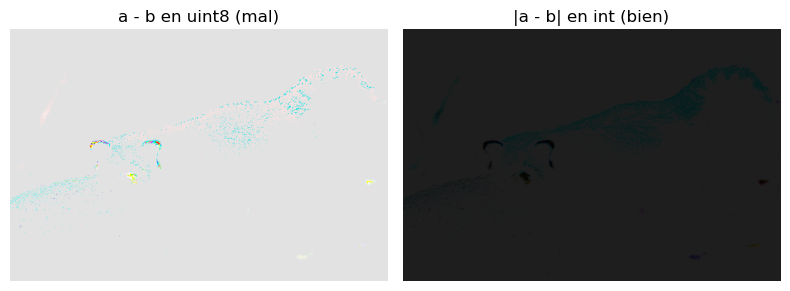

In [58]:
a = io.imread(IMG + 'panda.jpg')
b = np.clip(a.astype(int) + 30, 0, 255).astype(np.uint8)
mal  = a - b                                            # uint8: 10 - 40 = 226 en vez de -30
bien = np.abs(a.astype(int) - b.astype(int)).astype(np.uint8)
info('mal', mal); info('bien', bien)
mostrar([mal, bien], ['a - b en uint8 (mal)', '|a - b| en int (bien)'])

### B10. Decimales y tipos al crear arrays
Predice qué se guarda en cada caso y compruébalo.

In [59]:
print(np.array([25.5, 2.55, 255.9], dtype=np.uint8))   # [ 25   2 255] -> trunca decimales
print(np.array([1, 2, 3]).dtype)                        # int64 (por defecto en Mac/Linux)
print(np.array([1, 2, 3.0]).dtype)                      # float64 (basta un decimal)
print(np.zeros((2, 2)).dtype)                           # float64 (por defecto de zeros/ones)
print(np.array([True, False]).dtype)                    # bool
print((np.array([1, 2], dtype=np.uint8) * 1.0).dtype)   # float64 (multiplicar por float)
print((np.array([1, 2], dtype=np.uint8) * 2).dtype)     # uint8 (entero pequeño mantiene el tipo)

[ 25   2 255]
int64
float64
float64
bool
float64
uint8


---
## C. Slicing y geometría

### C1. Recortar (crop)
Recorta del panda (a) la región central de 300×400 y (b) el cuarto superior izquierdo. Imprime los shapes.

centro               shape=(300, 400, 3) dtype=uint8 min=0 max=255
cuarto               shape=(400, 600, 3) dtype=uint8 min=0 max=255


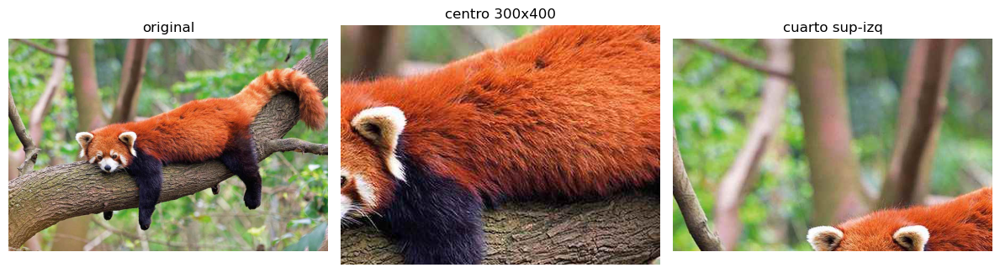

In [60]:
p = io.imread(IMG + 'panda.jpg')
H, W = p.shape[:2]                           # [:2] -> solo alto y ancho (sirve también para gris)
h, w = 300, 400
r0, c0 = (H - h) // 2, (W - w) // 2
centro = p[r0:r0+h, c0:c0+w]                 # sin tocar canales -> se mantienen los 3
cuarto = p[:H//2, :W//2]
info('centro', centro); info('cuarto', cuarto)
mostrar([p, centro, cuarto], ['original', 'centro 300x400', 'cuarto sup-izq'])

### C2. Partir en 4 cuadrantes y mostrarlos en 2×2
Divide `barcelona.jpg` en 4 cuadrantes y muéstralos en una rejilla 2×2 en su posición.

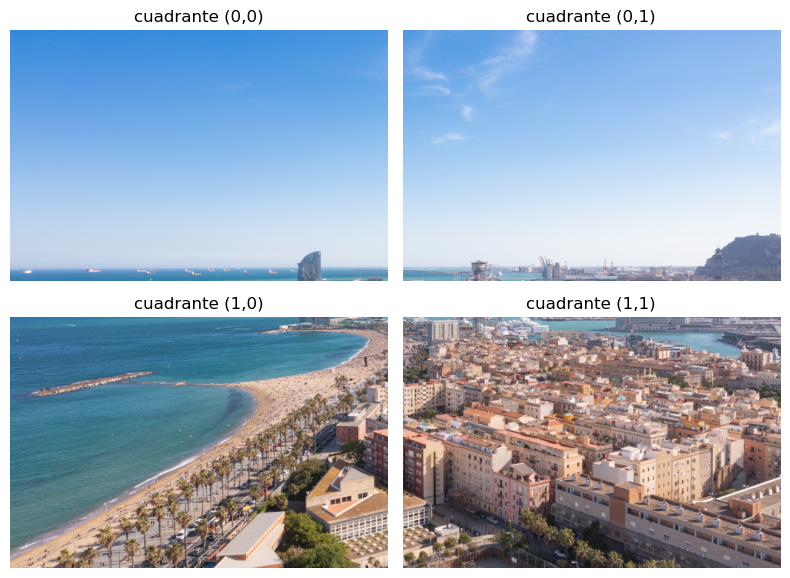

In [61]:
b = io.imread(IMG + 'barcelona.jpg')
H, W = b.shape[:2]
h2, w2 = H // 2, W // 2
trozos = [[b[:h2, :w2], b[:h2, w2:]],
          [b[h2:, :w2], b[h2:, w2:]]]
fig, axes = plt.subplots(2, 2, figsize=(8, 6))    # con 2x2 axes es una matriz -> axes[i, j]
for i in range(2):
    for j in range(2):
        axes[i, j].imshow(trozos[i][j])
        axes[i, j].set_title(f'cuadrante ({i},{j})')
        axes[i, j].axis('off')
plt.tight_layout(); plt.show()

### C3. Todos los volteos y rotaciones
Del panda muestra: original, volteo vertical, volteo horizontal, ambos (=rotación 180°), rotación 90° y traspuesta.

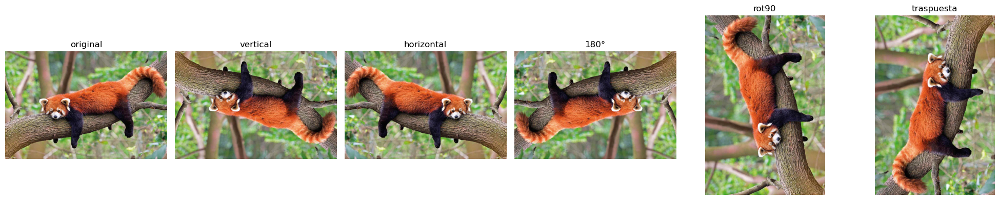

In [62]:
p = io.imread(IMG + 'panda.jpg')
v   = p[::-1, :]               # = np.flipud(p)  arriba<->abajo
h   = p[:, ::-1]               # = np.fliplr(p)  izquierda<->derecha
vh  = p[::-1, ::-1]            # = np.rot90(p, 2)
r90 = np.rot90(p)              # 90° antihorario (k=-1 o 3 para horario); cambia (H,W)->(W,H)
tr  = p.transpose(1, 0, 2)     # traspuesta: intercambia filas y columnas (canales en su sitio)
mostrar([p, v, h, vh, r90, tr], ['original', 'vertical', 'horizontal', '180°', 'rot90', 'traspuesta'],
        figsize=(20, 4))

### C4. Simetría (espejo de media imagen)
Crea una imagen simétrica del panda: la mitad izquierda original y la mitad derecha su reflejo.

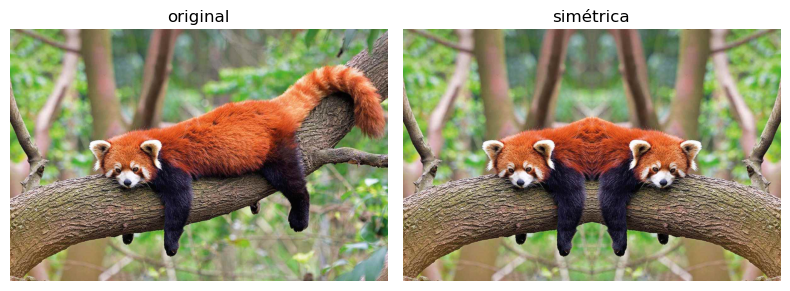

In [63]:
p = io.imread(IMG + 'panda.jpg')
W = p.shape[1]
sim = p.copy()
izq = p[:, :W//2]                     # mitad izquierda
sim[:, W - W//2:] = izq[:, ::-1]      # la derecha = la izquierda volteada horizontalmente
# (W - W//2 en vez de W//2 por si el ancho fuera impar)
mostrar([p, sim], ['original', 'simétrica'])

### C5. Mosaico 2×2 en una sola imagen
Crea UNA imagen con el panda 4 veces: original, volteado horizontal, vertical y 180°.

mosaico              shape=(1600, 2400, 3) dtype=uint8 min=0 max=255


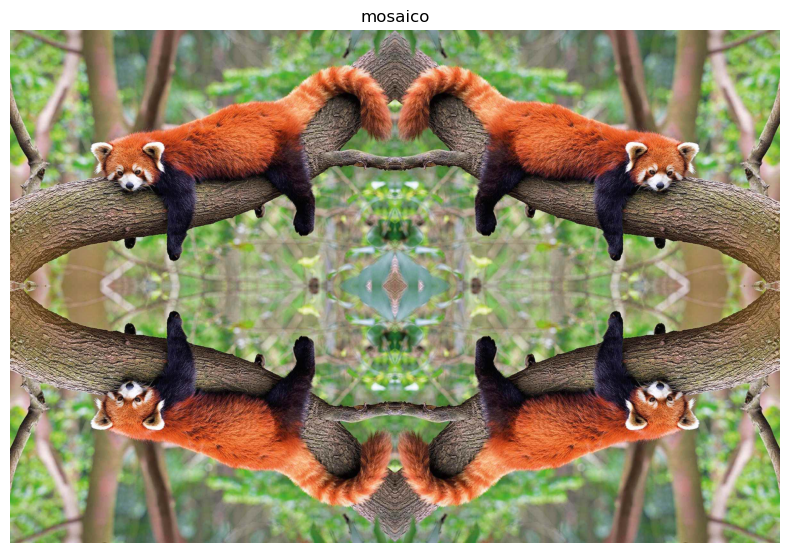

In [64]:
p = io.imread(IMG + 'panda.jpg')
h, w, c = p.shape
mos = np.zeros((2*h, 2*w, c), dtype=np.uint8)
mos[:h, :w] = p
mos[:h, w:] = p[:, ::-1]
mos[h:, :w] = p[::-1, :]
mos[h:, w:] = p[::-1, ::-1]
# Alternativa: np.vstack([np.hstack([p, p[:, ::-1]]), np.hstack([p[::-1], p[::-1, ::-1]])])
info('mosaico', mos)
mostrar([mos], ['mosaico'], figsize=(8, 6))

### C6. Marco de grosor fijo y color
Añade al panda un marco **rojo de 50 píxeles** (la imagen final mide 100 más en cada dimensión). Hazlo (a) con slicing y (b) con `np.pad`.

(800, 1200, 3) -> (900, 1300, 3) True


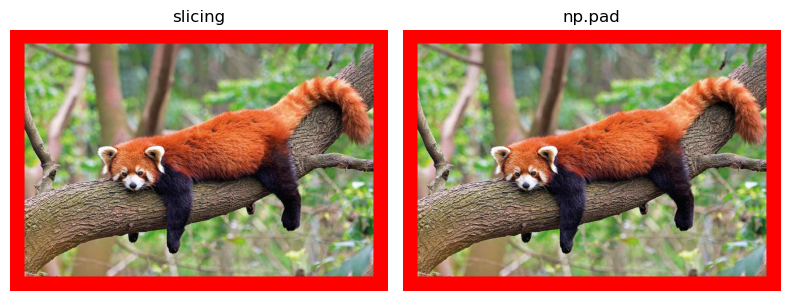

In [65]:
p = io.imread(IMG + 'panda.jpg')
h, w, c = p.shape
g = 50
# (a) lienzo relleno de rojo y pego el panda desplazado g píxeles
a = np.zeros((h + 2*g, w + 2*g, 3), dtype=np.uint8)
a[:] = [255, 0, 0]
a[g:g+h, g:g+w] = p

# (b) np.pad: añade g a cada lado en filas y columnas, 0 en canales; luego pinto el borde
b = np.pad(p, ((g, g), (g, g), (0, 0)), mode='constant', constant_values=0)
borde = np.ones(b.shape[:2], dtype=bool); borde[g:-g, g:-g] = False
b[borde] = [255, 0, 0]

print(p.shape, '->', a.shape, np.array_equal(a, b))
mostrar([a, b], ['slicing', 'np.pad'])

### C7. Marco de un % con color cualquiera
Generaliza la P1 1.3e/f: función `enmarcar(img, pct, color)` que devuelva la imagen centrada en un lienzo `pct`% mayor de color `color`. Pruébala con 20% azul y con 10% blanco.

20% azul             shape=(960, 1440, 3) dtype=uint8 min=0 max=255
10% blanco           shape=(880, 1320, 3) dtype=uint8 min=0 max=255


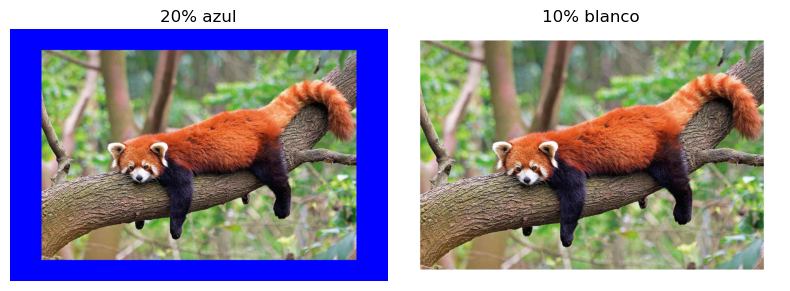

In [66]:
def enmarcar(img, pct, color):
    h, w = img.shape[:2]
    H, W = int(h * (1 + pct/100)), int(w * (1 + pct/100))
    lienzo = np.zeros((H, W, 3), dtype=np.uint8)
    lienzo[:] = color                                # todo del color del marco
    r0, c0 = (H - h) // 2, (W - w) // 2
    lienzo[r0:r0+h, c0:c0+w] = img                   # pego en el centro
    return lienzo

p = io.imread(IMG + 'panda.jpg')
a = enmarcar(p, 20, [0, 0, 255]); b = enmarcar(p, 10, [255, 255, 255])
info('20% azul', a); info('10% blanco', b)
mostrar([a, b], ['20% azul', '10% blanco'])

### C8. Imagen dentro de imagen (picture-in-picture)
Reduce `chairs.jpg` a 1/4 de su tamaño y colócala en la **esquina inferior derecha** de `barcelona.jpg`, con un margen de 10 píxeles.

peq                  shape=(270, 270, 3) dtype=uint8 min=0 max=247


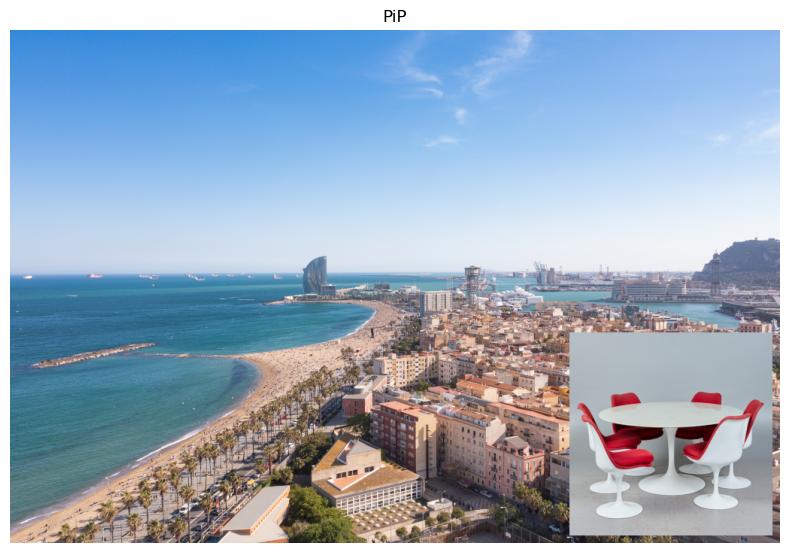

In [67]:
b = io.imread(IMG + 'barcelona.jpg')
ch = io.imread(IMG + 'chairs.jpg')
peq = img_as_ubyte(rescale(ch, 0.25, channel_axis=-1))   # rescale devuelve float -> a uint8
ph, pw = peq.shape[:2]
H, W = b.shape[:2]
res = b.copy()
m = 10
res[H-m-ph : H-m, W-m-pw : W-m] = peq                     # región exacta del tamaño de peq
info('peq', peq)
mostrar([res], ['PiP'], figsize=(8, 6))

### C9. Submuestrear con slicing vs rescale
Reduce el panda a la mitad (a) quedándote con 1 de cada 2 píxeles y (b) con `rescale`. Compara shapes y dtypes.

slicing              shape=(400, 600, 3) dtype=uint8 min=0 max=255
rescale              shape=(400, 600, 3) dtype=float64 min=8.302320975894978e-08 max=1.0


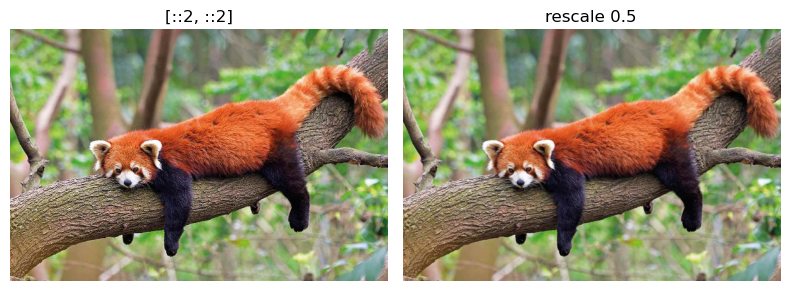

In [68]:
p = io.imread(IMG + 'panda.jpg')
a = p[::2, ::2]                                  # paso 2 en filas y columnas -> mitad; sigue uint8
b = rescale(p, 0.5, channel_axis=-1)             # interpola (más suave) -> float [0,1]
info('slicing', a); info('rescale', b)
mostrar([a, b], ['[::2, ::2]', 'rescale 0.5'])

### C10. Concatenar color y gris
Muestra en UNA imagen el panda en color a la izquierda y en gris a la derecha.

juntas               shape=(800, 2400, 3) dtype=uint8 min=0 max=255


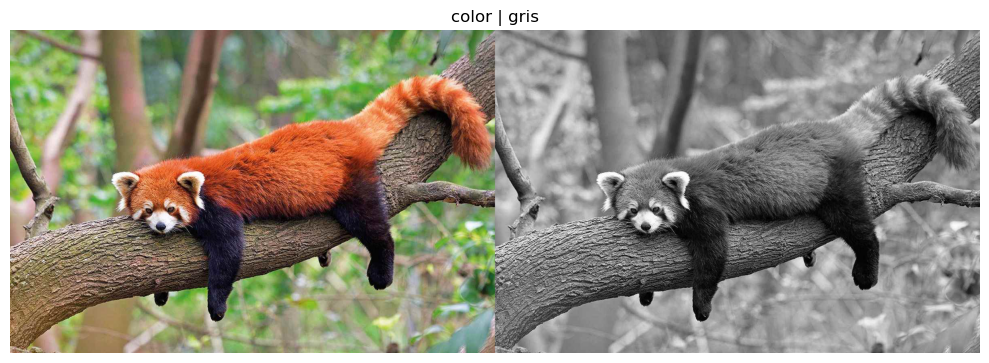

In [69]:
p = io.imread(IMG + 'panda.jpg')
g = img_as_ubyte(rgb2gray(p))         # (h, w) uint8
g3 = gray2rgb(g)                      # (h, w, 3): repite el gris en 3 canales para poder concatenar
juntas = np.hstack([p, g3])           # hstack = concatenar horizontalmente (mismo nº de filas y canales)
# np.vstack -> vertical ; np.concatenate([a, b], axis=1) == hstack
info('juntas', juntas)
mostrar([juntas], ['color | gris'], figsize=(10, 4))

### C11. Quitar bordes (recortar un %)
Elimina un **10% de cada lado** del panda (arriba, abajo, izquierda, derecha). Imprime shapes.

original             shape=(800, 1200, 3) dtype=uint8 min=0 max=255
recortada            shape=(640, 960, 3) dtype=uint8 min=0 max=255


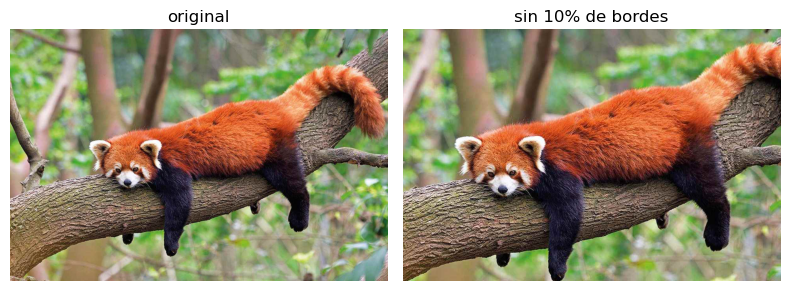

In [70]:
p = io.imread(IMG + 'panda.jpg')
H, W = p.shape[:2]
dh, dw = int(H * 0.10), int(W * 0.10)       # 80 y 120 píxeles
rec = p[dh:H-dh, dw:W-dw]                   # también vale p[dh:-dh, dw:-dw] (si dh, dw > 0)
info('original', p); info('recortada', rec)
mostrar([p, rec], ['original', 'sin 10% de bordes'])

### C12. Desplazar (traslación)
Desplaza el panda **100 píxeles a la derecha** y **50 hacia abajo**, rellenando de negro lo que queda vacío. Compáralo con `np.roll` (que hace que la imagen 'dé la vuelta').

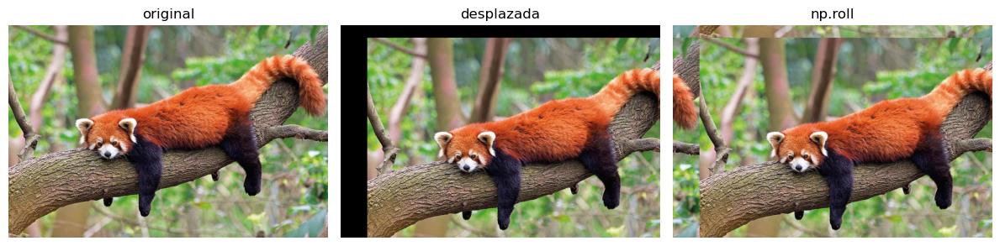

In [71]:
p = io.imread(IMG + 'panda.jpg')
dy, dx = 50, 100
mov = np.zeros_like(p)
mov[dy:, dx:] = p[:-dy, :-dx]          # destino desplazado <- origen sin las últimas dy filas / dx columnas
rol = np.roll(p, shift=(dy, dx), axis=(0, 1))   # lo que sale por un lado entra por el otro
mostrar([p, mov, rol], ['original', 'desplazada', 'np.roll'])

### C13. Intercambiar mitades
Intercambia la mitad izquierda y la derecha del panda (y en otra imagen, la de arriba y la de abajo).

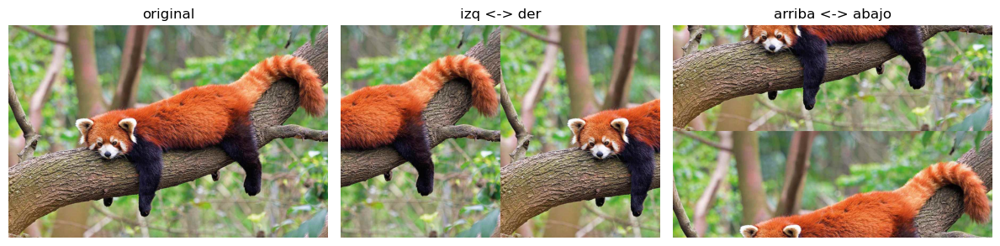

In [72]:
p = io.imread(IMG + 'panda.jpg')
H, W = p.shape[:2]
lr = np.hstack([p[:, W//2:], p[:, :W//2]])   # derecha primero, izquierda después
ud = np.vstack([p[H//2:], p[:H//2]])         # abajo primero, arriba después
# Equivalente: np.roll(p, W//2, axis=1)
mostrar([p, lr, ud], ['original', 'izq <-> der', 'arriba <-> abajo'])

### C14. Rotar solo un trozo
Recorta el cuadrado central de 400×400 del panda, **rótalo 90°** y pégalo en el mismo sitio.

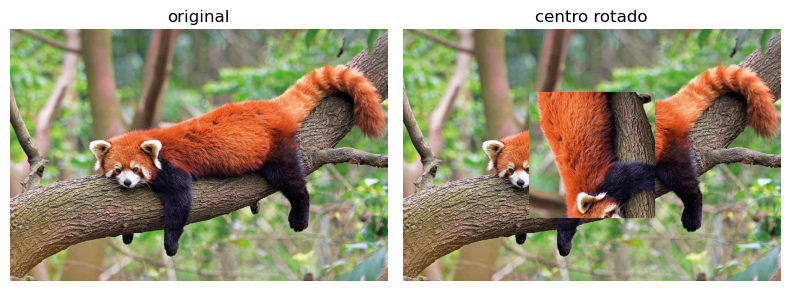

In [73]:
p = io.imread(IMG + 'panda.jpg')
H, W = p.shape[:2]
L = 400
r0, c0 = (H - L) // 2, (W - L) // 2
res = p.copy()
res[r0:r0+L, c0:c0+L] = np.rot90(p[r0:r0+L, c0:c0+L])   # al ser cuadrado, el shape no cambia
mostrar([p, res], ['original', 'centro rotado'])

### C15. Dos imágenes en una (lado a lado del mismo alto)
Pon `barcelona.jpg` y `chairs.jpg` una al lado de la otra en una sola imagen. Como tienen distinto alto, redimensiona chairs al alto de barcelona manteniendo la proporción.

juntas               shape=(682, 1706, 3) dtype=uint8 min=0 max=255


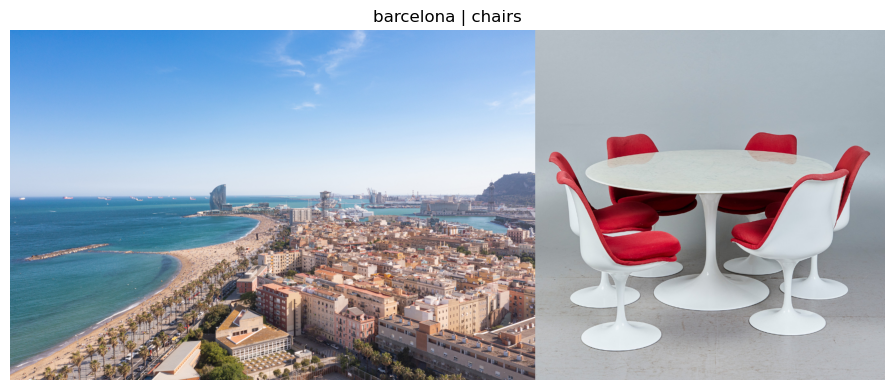

In [74]:
b = io.imread(IMG + 'barcelona.jpg')
ch = io.imread(IMG + 'chairs.jpg')
h = b.shape[0]
w = int(round(ch.shape[1] * h / ch.shape[0]))       # ancho proporcional al nuevo alto
ch2 = img_as_ubyte(resize(ch, (h, w)))              # resize -> float, img_as_ubyte -> uint8
juntas = np.hstack([b, ch2])                        # mismo nº de filas y de canales -> OK
info('juntas', juntas)
mostrar([juntas], ['barcelona | chairs'], figsize=(12, 4))

### C16. Tiras intercaladas
Crea una imagen que alterne **tiras verticales de 100 píxeles** del panda en color y del panda en gris.

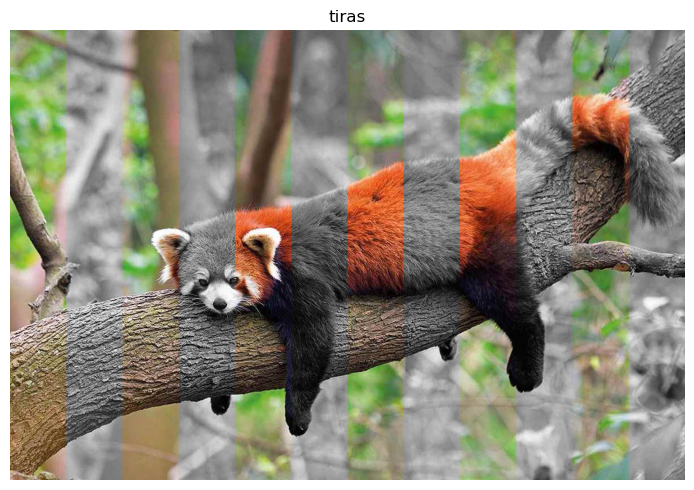

In [75]:
p = io.imread(IMG + 'panda.jpg')
g3 = gray2rgb(img_as_ubyte(rgb2gray(p)))     # gris con 3 canales (uint8) para poder mezclar
res = p.copy()
W = p.shape[1]
for c in range(100, W, 200):                 # tiras grises en 100-199, 300-399, ...
    res[:, c:c+100] = g3[:, c:c+100]
# Sin bucle: res[:, (np.arange(W) // 100) % 2 == 1] = g3[:, (np.arange(W) // 100) % 2 == 1]
mostrar([res], ['tiras'], figsize=(8, 5))

---
## D. Leer y guardar

### D1. Guardar, releer y verificar (PNG vs JPG)
Guarda la imagen de cuadrantes de colores en PNG y JPG, reléelas y comprueba si son idénticas a la original.

In [76]:
cua = np.zeros((200, 200, 3), dtype=np.uint8)
cua[:100, :100] = [255, 0, 0]; cua[:100, 100:] = [0, 255, 0]
cua[100:, :100] = [0, 0, 255]; cua[100:, 100:] = [255, 255, 255]

os.makedirs('output', exist_ok=True)
io.imsave(os.path.join('output', 'cua.png'), cua)
io.imsave(os.path.join('output', 'cua.jpg'), cua)
png = io.imread(os.path.join('output', 'cua.png'))
jpg = io.imread(os.path.join('output', 'cua.jpg'))
print('PNG idéntica:', np.array_equal(png, cua))     # True  (sin pérdida)
print('JPG idéntica:', np.array_equal(jpg, cua))     # False (compresión con pérdida)
print('píxel (99,99) original/PNG/JPG:', cua[99, 99], png[99, 99], jpg[99, 99])

PNG idéntica: True
JPG idéntica: False
píxel (99,99) original/PNG/JPG: [255   0   0] [255   0   0] [132  33  61]


### D2. Guardar varias imágenes en bucle
Guarda los tres canales de `barcelona.jpg` como `canal_R.png`, `canal_G.png`, `canal_B.png` dentro de `output/canales/`.

In [77]:
b = io.imread(IMG + 'barcelona.jpg')
carpeta = os.path.join('output', 'canales')
os.makedirs(carpeta, exist_ok=True)               # crea también las carpetas intermedias
for k, nombre in enumerate(['R', 'G', 'B']):
    ruta = os.path.join(carpeta, f'canal_{nombre}.png')
    io.imsave(ruta, b[:, :, k])                   # cada canal es 2D uint8 -> se guarda como gris
    print('guardado', ruta)
print(os.listdir(carpeta))

guardado output/canales/canal_R.png
guardado output/canales/canal_G.png
guardado output/canales/canal_B.png
['canal_B.png', 'canal_G.png', 'canal_R.png']


### D3. Guardar una imagen float
Guarda la versión gris del panda y la versión con contraste estirado (float). ¿Qué hay que hacer antes de guardar?

In [78]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))      # float64 [0,1]
io.imsave('output/g.png', img_as_ubyte(g))      # float [0,1] -> uint8 [0,255]

# Si el float NO está en [0,1] (p.ej. valores 0..255 en float) -> astype tras clip
f = io.imread(IMG + 'panda.jpg').astype(float) * 1.3          # puede pasar de 255
io.imsave('output/f.png', np.clip(f, 0, 255).astype(np.uint8))
print(io.imread('output/g.png').dtype, io.imread('output/f.png').max())

uint8 255


### D4. Leer, procesar y guardar con otro nombre
Lee todas las imágenes `.jpg` de `images_notebook`, conviértelas a gris y guárdalas en `output/gris/` con el sufijo `_gray.png`.

In [79]:
carpeta = os.path.join('output', 'gris')
os.makedirs(carpeta, exist_ok=True)
for nombre in sorted(os.listdir(IMG)):
    if nombre.lower().endswith('.jpg'):
        im = io.imread(os.path.join(IMG, nombre))
        if im.ndim == 3:                                   # solo convierto si es de color
            im = img_as_ubyte(rgb2gray(im[:, :, :3]))
        base, ext = os.path.splitext(nombre)               # 'panda.jpg' -> ('panda', '.jpg')
        io.imsave(os.path.join(carpeta, base + '_gray.png'), im)
print(os.listdir(carpeta))

['framed_panda_green_gray.png', 'barcelona_gray.png', 'chairs_gray.png', 'framed_panda_gray.png', 'panda_gray.png']


---
## E. Color

### E1. Canales en gris y en color
Muestra los 3 canales de `chairs.jpg` (a) en gris y (b) **en color** (cada uno en su color, los otros a 0).

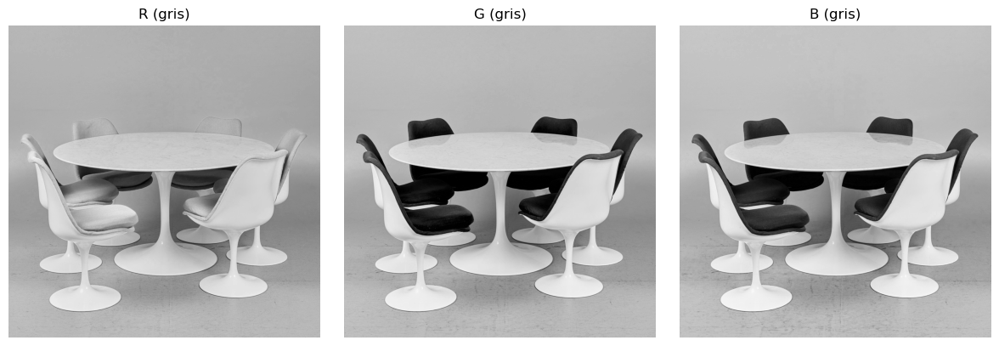

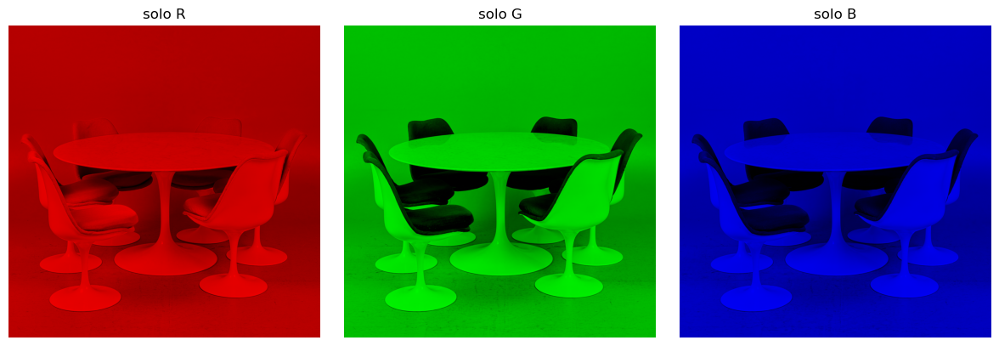

In [80]:
ch = io.imread(IMG + 'chairs.jpg')
nombres = ['R', 'G', 'B']
mostrar([ch[:, :, k] for k in range(3)], [f'{n} (gris)' for n in nombres], vmax=255)

coloreados = []
for k in range(3):
    solo = np.zeros_like(ch)          # mismo shape y dtype, todo a 0
    solo[:, :, k] = ch[:, :, k]       # solo el canal k
    coloreados.append(solo)
mostrar(coloreados, [f'solo {n}' for n in nombres])

### E2. Todas las permutaciones de canales
Muestra `chairs.jpg` con los canales en orden RGB, RBG, GRB, GBR, BRG, BGR.

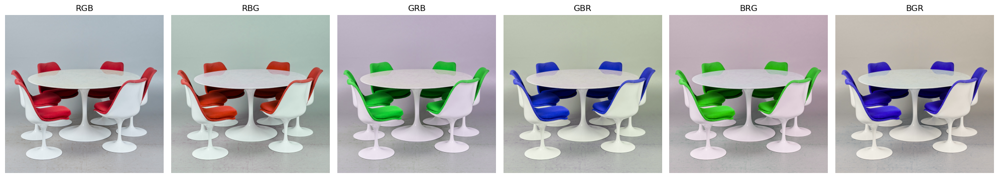

In [81]:
from itertools import permutations
ch = io.imread(IMG + 'chairs.jpg')
imgs, tits = [], []
for perm in permutations([0, 1, 2]):                 # las 6 permutaciones
    imgs.append(ch[:, :, list(perm)])                # indexar canales con una lista los reordena
    tits.append(''.join('RGB'[i] for i in perm))
mostrar(imgs, tits, figsize=(20, 4))

### E3. Eliminar o potenciar un canal
En `barcelona.jpg`: (a) quita el azul (B=0); (b) aumenta el rojo un 50% **sin overflow**.

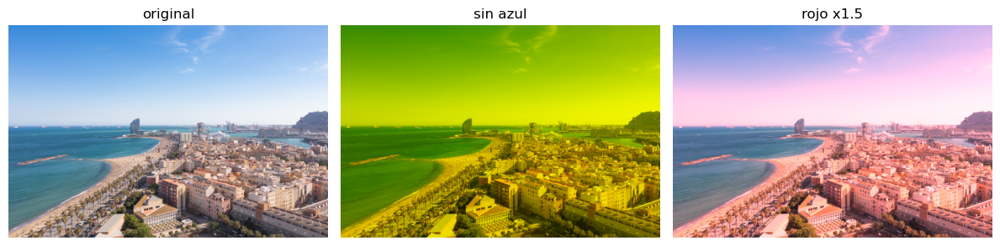

In [82]:
b = io.imread(IMG + 'barcelona.jpg')
sin_azul = b.copy()
sin_azul[:, :, 2] = 0                          # canal azul a 0 -> tonos amarillentos

mas_rojo = b.copy()
r = mas_rojo[:, :, 0].astype(float) * 1.5      # a float para no hacer overflow
mas_rojo[:, :, 0] = np.clip(r, 0, 255).astype(np.uint8)
mostrar([b, sin_azul, mas_rojo], ['original', 'sin azul', 'rojo x1.5'])

### E4. rgb2gray a mano
Calcula la gris de `chairs.jpg` a mano con los pesos de `rgb2gray` y compárala con `rgb2gray`. Compárala también con la media simple de los canales.

Coincide con rgb2gray: True
Diferencia máx con la media simple: 0.14119163398692805


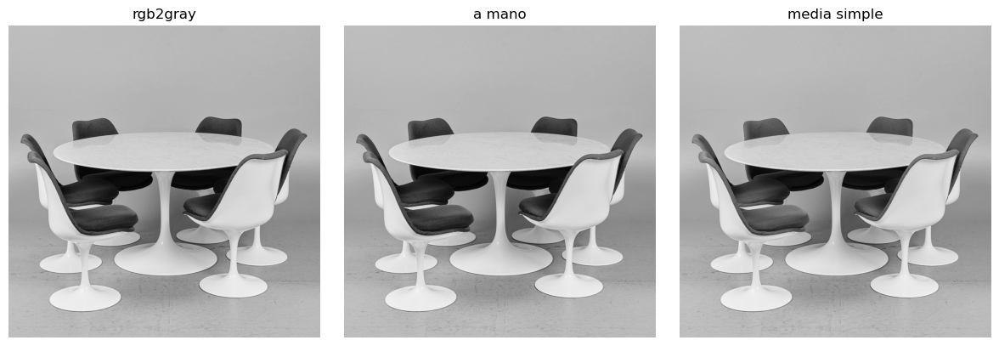

In [83]:
ch = io.imread(IMG + 'chairs.jpg')
f = img_as_float(ch)                                   # a [0,1] como hace rgb2gray
mano = 0.2125*f[:, :, 0] + 0.7154*f[:, :, 1] + 0.0721*f[:, :, 2]
media = f.mean(axis=2)                                  # media simple de los 3 canales
print('Coincide con rgb2gray:', np.allclose(mano, rgb2gray(ch)))
print('Diferencia máx con la media simple:', np.abs(mano - media).max())
mostrar([rgb2gray(ch), mano, media], ['rgb2gray', 'a mano', 'media simple'], vmax=1)

### E5. De gris a RGB y teñir
Convierte la gris del panda a RGB con `gray2rgb` (¿qué se ve?). Después crea una versión **sepia/teñida de rojo** poniendo el gris solo en el canal R.

(800, 1200, 3) True


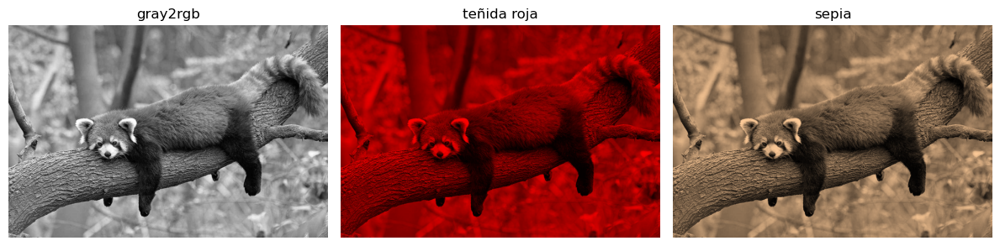

In [84]:
g = img_as_ubyte(rgb2gray(io.imread(IMG + 'panda.jpg')))
g3 = gray2rgb(g)                        # (h,w,3) con R=G=B -> se sigue viendo GRIS
print(g3.shape, np.array_equal(g3[:, :, 0], g3[:, :, 2]))

rojo = np.zeros_like(g3)
rojo[:, :, 0] = g                       # solo canal rojo
sepia = np.stack([g, (g * 0.8).astype(np.uint8), (g * 0.6).astype(np.uint8)], axis=2)
mostrar([g3, rojo, sepia], ['gray2rgb', 'teñida roja', 'sepia'])

### E6. Píxeles donde domina un color
En `barcelona.jpg` encuentra los píxeles donde el **azul es el canal mayor** (cielo/mar) y píntalos de blanco.

píxeles azules: 477033 (68.3%)


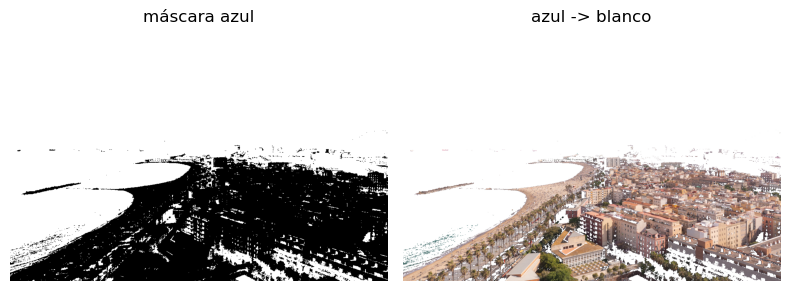

In [85]:
b = io.imread(IMG + 'barcelona.jpg').astype(int)      # a int para comparar sin líos
R, G, B = b[:, :, 0], b[:, :, 1], b[:, :, 2]
azul = (B > R) & (B > G)                               # & = Y lógico (¡paréntesis!)
# alternativa: azul = np.argmax(b, axis=2) == 2
res = io.imread(IMG + 'barcelona.jpg')
res[azul] = [255, 255, 255]
print('píxeles azules:', azul.sum(), f'({100*azul.mean():.1f}%)')
mostrar([azul, res], ['máscara azul', 'azul -> blanco'])

### E7. Trabajar con RGBA
Con `coat.png`: muestra el canal alfa, conviértela a RGB con `rgba2rgb` y quitando el alfa a mano; y haz **transparente** el fondo negro.

coat                 shape=(1188, 915, 4) dtype=uint8 min=0 max=255
valores de alfa: [255]
rgba2rgb             shape=(1188, 915, 3) dtype=float64 min=0.0 max=0.803921568627451
[..., :3]            shape=(1188, 915, 3) dtype=uint8 min=0 max=205


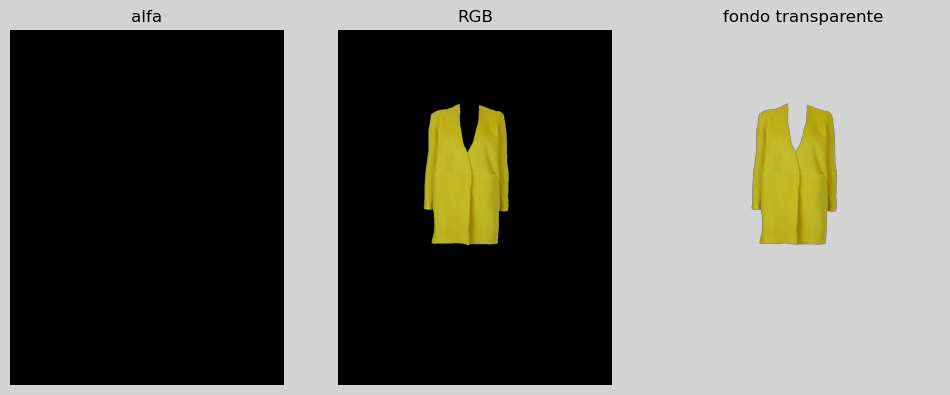

In [86]:
c = io.imread(IMG + 'coat.png')
info('coat', c)
alfa = c[:, :, 3]
print('valores de alfa:', np.unique(alfa))              # todo 255 = opaco

rgb1 = rgba2rgb(c)                                      # float [0,1], (h,w,3) mezcla con fondo blanco
rgb2 = c[:, :, :3]                                      # simplemente quitar el 4º canal (uint8)
info('rgba2rgb', rgb1); info('[..., :3]', rgb2)

trans = c.copy()
negro = np.all(c[:, :, :3] == 0, axis=2)                # TODOS los canales RGB a 0
trans[negro, 3] = 0                                     # alfa = 0 -> transparente
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
fig.patch.set_facecolor('lightgray')                    # fondo gris para ver la transparencia
for ax, im, t in zip(axes, [alfa, rgb2, trans], ['alfa', 'RGB', 'fondo transparente']):
    ax.imshow(im, cmap='gray'); ax.set_title(t); ax.axis('off')
plt.show()

### E8. Color splash
En `chairs.jpg` deja en color solo los píxeles **rojizos** (R > 150, G < 100, B < 100) y el resto en gris.

píxeles rojos: 59157


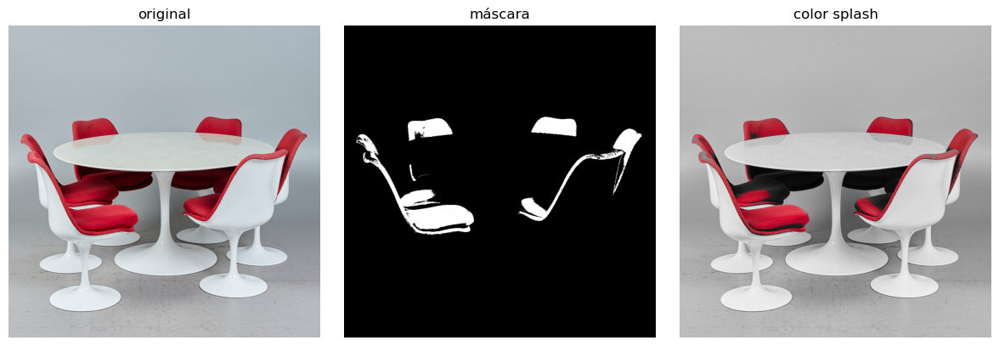

In [87]:
ch = io.imread(IMG + 'chairs.jpg')
R, G, B = ch[:, :, 0], ch[:, :, 1], ch[:, :, 2]
rojo = (R > 150) & (G < 100) & (B < 100)
g3 = gray2rgb(img_as_ubyte(rgb2gray(ch)))   # versión gris con 3 canales (uint8)
res = g3.copy()
res[rojo] = ch[rojo]                          # donde es rojo, recupero el color original
print('píxeles rojos:', rojo.sum())
mostrar([ch, rojo, res], ['original', 'máscara', 'color splash'])

### E9. Mezcla (blend) de dos imágenes
Mezcla `barcelona.jpg` y `chairs.jpg` (redimensionada al tamaño de barcelona) con `alpha = 0.3, 0.5, 0.7`: `alpha*A + (1-alpha)*B`.

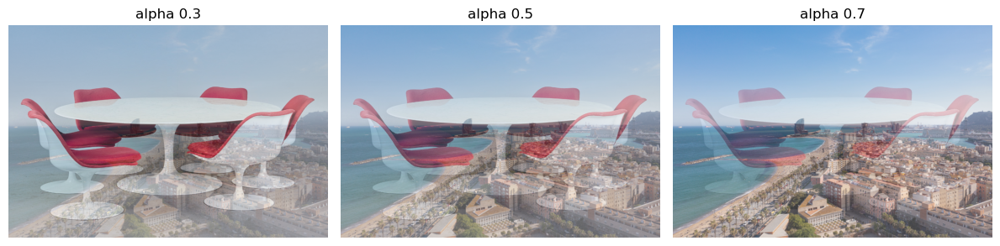

In [88]:
A = img_as_float(io.imread(IMG + 'barcelona.jpg'))         # trabajo en float [0,1]
B = resize(io.imread(IMG + 'chairs.jpg'), A.shape)         # resize ya devuelve float [0,1]
mezclas = [alpha * A + (1 - alpha) * B for alpha in (0.3, 0.5, 0.7)]
# Si quieres guardarla: img_as_ubyte(mezcla)
mostrar(mezclas, ['alpha 0.3', 'alpha 0.5', 'alpha 0.7'])

### E10. Mitad en color, mitad en gris
Muestra el panda con la **mitad izquierda en gris** y la derecha en color.

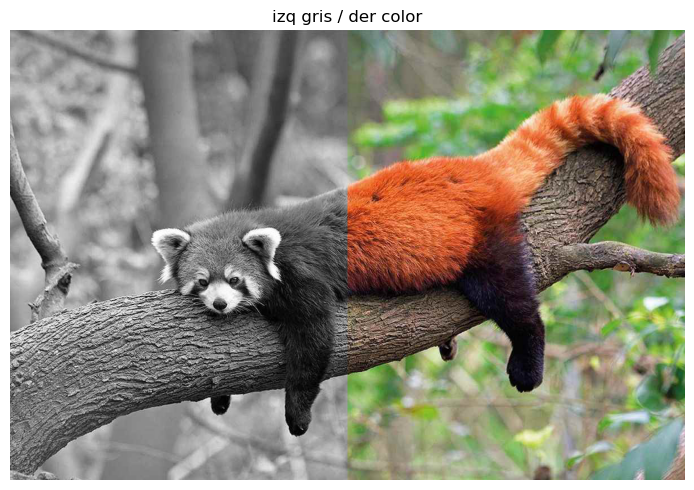

In [89]:
p = io.imread(IMG + 'panda.jpg')
W = p.shape[1]
g3 = gray2rgb(img_as_ubyte(rgb2gray(p)))
res = p.copy()
res[:, :W//2] = g3[:, :W//2]
mostrar([res], ['izq gris / der color'], figsize=(8, 5))

### E11. Cambiar un color concreto por otro
En la imagen de cuadrantes de colores de la P1 (rojo/azul/cian/amarillo), cambia **todos los píxeles amarillos por blancos** y los **azules por negros**.

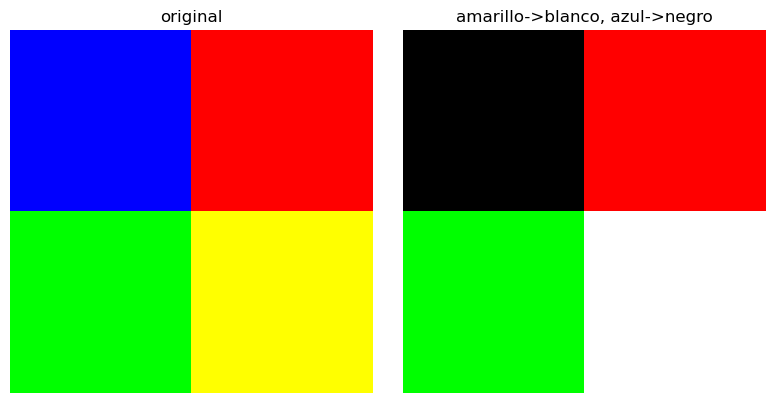

In [90]:
b = np.zeros((100, 100), np.uint8)
i1 = b.copy(); i1[:, 50:] = 255
i2 = b.copy(); i2[50:, :] = 255
i3 = b.copy(); i3[:50, :50] = 255
img = np.stack([i1, i2, i3], axis=2)

amarillo = np.all(img == [255, 255, 0], axis=2)     # compara cada píxel con el color (broadcasting)
azul     = np.all(img == [0, 0, 255], axis=2)
res = img.copy()
res[amarillo] = [255, 255, 255]
res[azul] = [0, 0, 0]
mostrar([img, res], ['original', 'amarillo->blanco, azul->negro'])

### E12. Cambiar el color 'aproximado'
En `barcelona.jpg` sustituye los píxeles **casi blancos** (los 3 canales > 200) por **rosa** `[255, 105, 180]`.

12.04% de píxeles cambiados


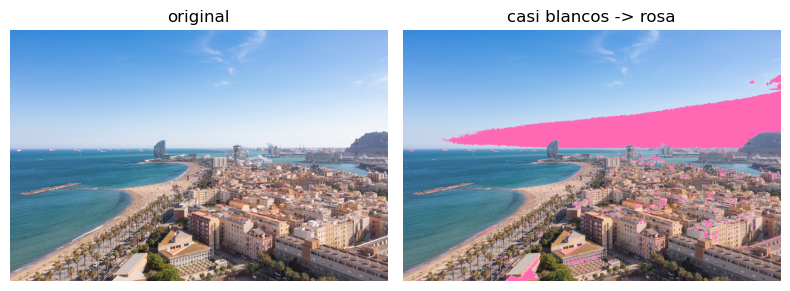

In [91]:
b = io.imread(IMG + 'barcelona.jpg')
casi_blanco = np.all(b > 200, axis=2)               # TODOS los canales por encima de 200
res = b.copy()
res[casi_blanco] = [255, 105, 180]
print(f'{100 * casi_blanco.mean():.2f}% de píxeles cambiados')
mostrar([b, res], ['original', 'casi blancos -> rosa'])

### E13. Canal máximo y canal mínimo
Para `chairs.jpg` crea dos imágenes grises: el **máximo** de los 3 canales en cada píxel y el **mínimo**. Compáralas con `rgb2gray`.

max                  shape=(1080, 1080) dtype=uint8 min=0 max=255
min                  shape=(1080, 1080) dtype=uint8 min=0 max=250
gray                 shape=(1080, 1080) dtype=uint8 min=0 max=254


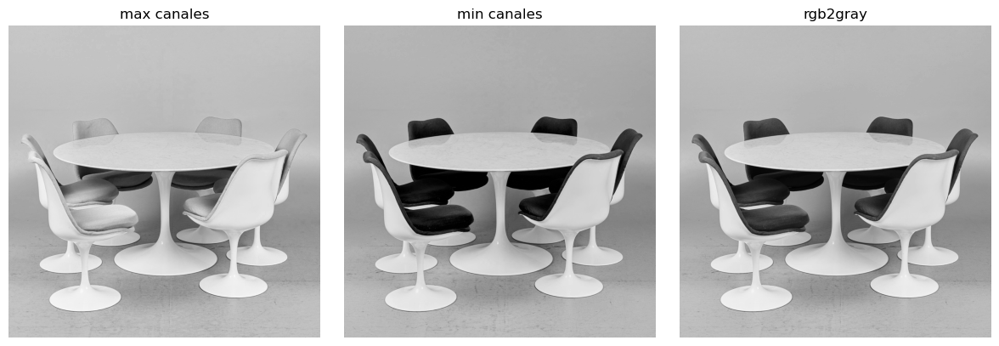

In [92]:
ch = io.imread(IMG + 'chairs.jpg')
mx = ch.max(axis=2)          # axis=2 -> el máximo entre R, G, B de cada píxel -> (h, w)
mn = ch.min(axis=2)
g = img_as_ubyte(rgb2gray(ch))
info('max', mx); info('min', mn); info('gray', g)
mostrar([mx, mn, g], ['max canales', 'min canales', 'rgb2gray'], vmax=255)

### E14. Construir una RGB a partir de una gris
A partir de la gris de `barcelona.jpg` crea una imagen RGB donde R = gris, G = gris volteada horizontalmente, B = negativo de la gris.

rgb                  shape=(682, 1024, 3) dtype=uint8 min=0 max=255


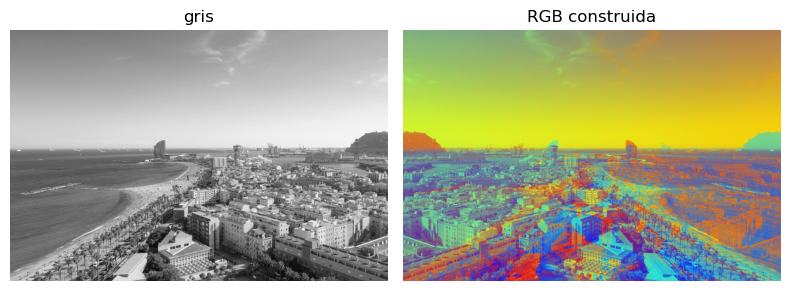

In [93]:
g = img_as_ubyte(rgb2gray(io.imread(IMG + 'barcelona.jpg')))
rgb = np.stack([g, g[:, ::-1], 255 - g], axis=2)    # (h, w, 3) uint8
info('rgb', rgb)
mostrar([g, rgb], ['gris', 'RGB construida'])

---
## F. Máscaras y umbralización

### F1. Binarizar de varias formas
Binariza la gris del panda con (a) la media, (b) la mediana, (c) un umbral fijo 0.3 y (d) el **inverso** de (a).

a bool 58.2% blancos
b bool 50.0% blancos
c bool 83.1% blancos
d bool 41.8% blancos


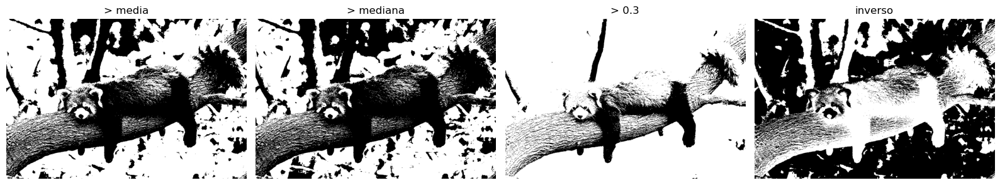

In [94]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))
a = g > g.mean()
b = g > np.median(g)
c = g > 0.3
d = ~a                       # ~ = NOT lógico (también np.logical_not(a) o g <= g.mean())
for n, m in zip('abcd', [a, b, c, d]):
    print(n, m.dtype, f'{100*m.mean():.1f}% blancos')     # media de un bool = proporción de True
mostrar([a, b, c, d], ['> media', '> mediana', '> 0.3', 'inverso'])

### F2. Umbral doble (rango)
Selecciona los píxeles grises del panda con intensidad entre 0.4 y 0.7. Muestra la máscara y la imagen con el resto a negro.

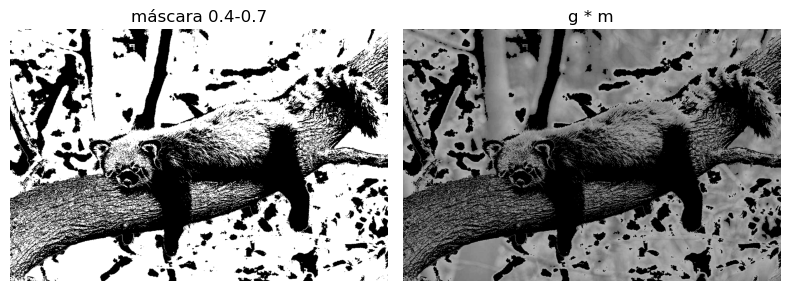

In [95]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))
m = (g >= 0.4) & (g <= 0.7)             # SIEMPRE con paréntesis: & tiene más prioridad que >=
solo = g * m                            # False=0 -> lo que no está en el rango se vuelve negro
# alternativa: solo = np.where(m, g, 0)
mostrar([m, solo], ['máscara 0.4-0.7', 'g * m'], vmax=1)

### F3. Contar píxeles
En `circles.bmp` cuenta los píxeles negros, blancos y grises (ni 0 ni 255), y el % de cada uno.

In [96]:
c = io.imread(IMG + 'circles.bmp')
g = c[:, :, 0] if c.ndim == 3 else c             # si es RGB "gris", basta un canal
negros = g == 0
blancos = g == 255
grises = ~negros & ~blancos
for n, m in [('negros', negros), ('blancos', blancos), ('grises', grises)]:
    print(f'{n:8s} {m.sum():7d} píxeles  {100*m.mean():5.2f}%')    # sum de bool = nº de True
print('total', g.size)

negros     45741 píxeles   6.30%
blancos   595914 píxeles  82.11%
grises     84063 píxeles  11.58%
total 725718


### F4. Fondo a blanco
En la gris del panda, conserva los píxeles más oscuros que la media y pon el resto a **blanco**.

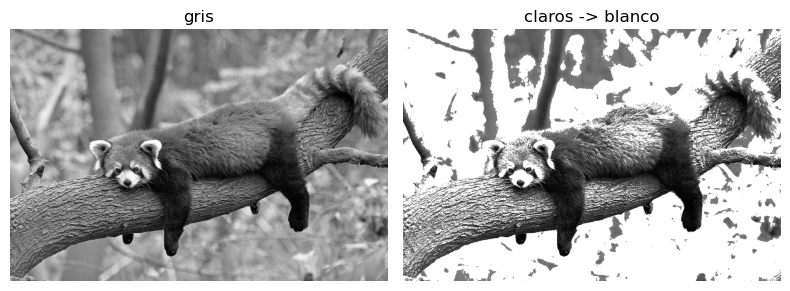

In [97]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))
res = g.copy()
res[g > g.mean()] = 1.0              # en float, blanco = 1.0 (en uint8 sería 255)
mostrar([g, res], ['gris', 'claros -> blanco'], vmax=1)

### F5. Pintar de color los píxeles seleccionados
Sobre el panda RGB pinta de **rojo** los píxeles muy oscuros (gris < 0.2) y de **amarillo** los muy claros (gris > 0.8).

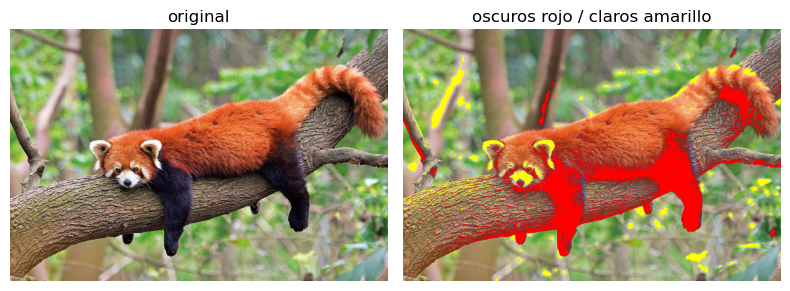

In [98]:
p = io.imread(IMG + 'panda.jpg')
g = rgb2gray(p)                       # la máscara se calcula en 2D...
res = p.copy()
res[g < 0.2] = [255, 0, 0]            # ...y se aplica a la RGB: res[mask] es (N,3) -> asigno un color
res[g > 0.8] = [255, 255, 0]
mostrar([p, res], ['original', 'oscuros rojo / claros amarillo'])

### F6. np.any vs np.all
Con `coat.png`: máscara de píxeles **no negros** (np.any) y de píxeles **exactamente negros** (np.all). Comprueba que son complementarias.

(1188, 915) complementarias: True


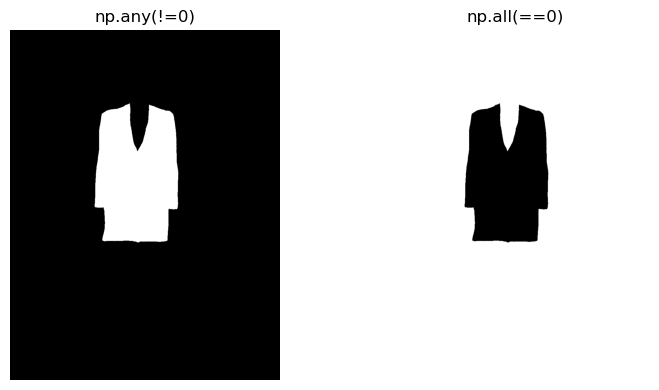

In [99]:
c = io.imread(IMG + 'coat.png')
rgb = c[:, :, :3]
no_negro = np.any(rgb != 0, axis=2)     # algún canal != 0
negro    = np.all(rgb == 0, axis=2)     # todos los canales == 0
print(no_negro.shape, 'complementarias:', np.array_equal(no_negro, ~negro))
# axis=2 -> "colapsa" la dimensión de canales: (h, w, 3) -> (h, w)
mostrar([no_negro, negro], ['np.any(!=0)', 'np.all(==0)'])

### F7. Cada círculo de un color
En `circles.bmp` pinta el círculo izquierdo de **rojo**, el central de **verde** y el derecho de **azul** (columnas 0–299, 300–599, 600–fin), dejando el fondo blanco.

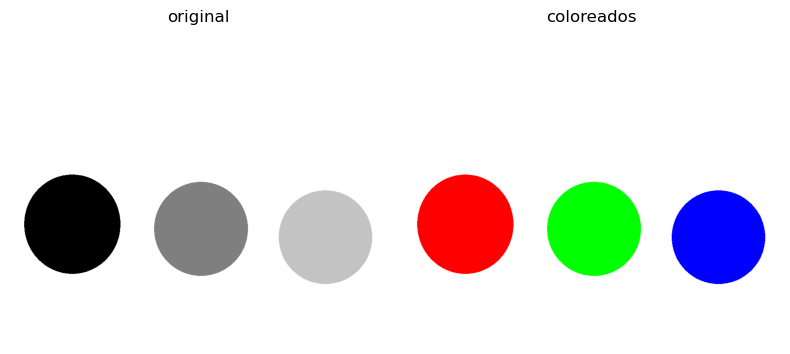

In [100]:
c = io.imread(IMG + 'circles.bmp')
if c.ndim == 2:
    c = gray2rgb(c)                         # aseguro 3 canales
no_blanco = ~np.all(c == 255, axis=2)       # píxeles que pertenecen a algún círculo
cols = np.indices(no_blanco.shape)[1]       # matriz con el nº de columna de cada píxel
res = c.copy()
res[no_blanco & (cols < 300)] = [255, 0, 0]
res[no_blanco & (cols >= 300) & (cols < 600)] = [0, 255, 0]
res[no_blanco & (cols >= 600)] = [0, 0, 255]
# Alternativa con slicing: res[:, :300][no_blanco[:, :300]] = [255, 0, 0]  etc.
mostrar([c, res], ['original', 'coloreados'])

### F8. Un solo círculo sin usar columnas
Ahora sin columnas fijas: quédate solo con el círculo **central** de `circles.bmp` sabiendo únicamente que está centrado (usa la mitad del ancho ± un tercio).

columnas 311 622


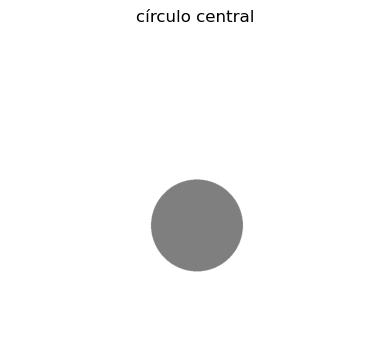

In [101]:
c = io.imread(IMG + 'circles.bmp')
W = c.shape[1]
a, b = W // 3, 2 * W // 3                   # tercio central calculado, no "hardcodeado"
res = np.full_like(c, 255)                   # full_like: mismo shape/dtype, todo a 255
res[:, a:b] = c[:, a:b]
print('columnas', a, b)
mostrar([res], ['círculo central'], vmax=255)

### F9. Superponer con np.where
Superpón el abrigo **cambiado de color** sobre la modelo usando `np.where` en lugar de indexar con máscara.

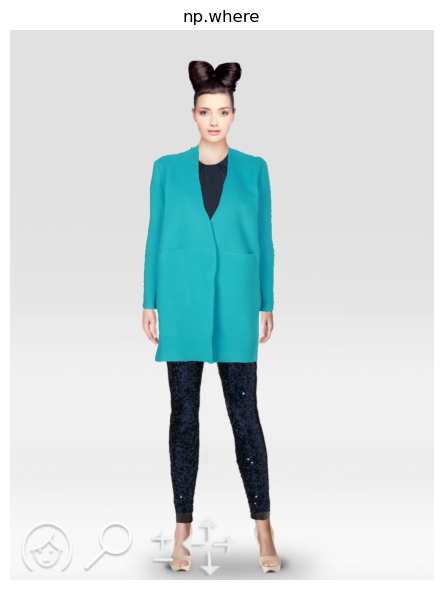

In [102]:
coat = io.imread(IMG + 'coat.png')
model = io.imread(IMG + 'model.png')
cambiado = coat[:, :, [2, 1, 0, 3]]                 # R<->B, G y alfa iguales
mask = np.any(coat[:, :, :3] != 0, axis=2)          # (h, w)
m3 = mask[:, :, np.newaxis]                         # (h, w, 1) -> broadcasting con (h, w, 4)
res = np.where(m3, cambiado, model)                 # donde True cambiado, si no model
mostrar([res], ['np.where'], figsize=(5, 6))

### F10. Abrigo de color sólido / sólo en parte
(a) Pon a la modelo un abrigo de color **verde sólido** `[0, 200, 0]`. (b) Pon el abrigo original solo en la **mitad izquierda** de la imagen.

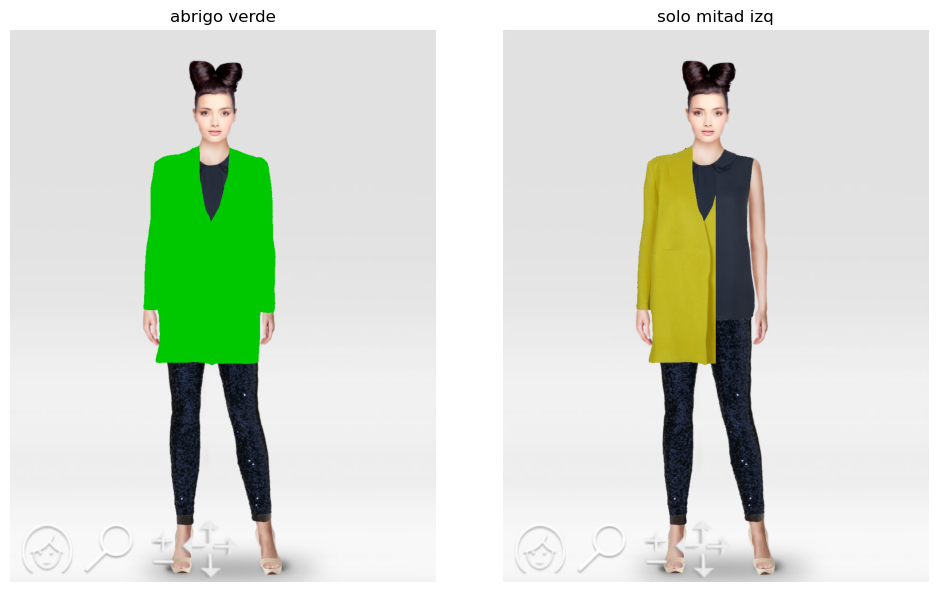

In [103]:
coat = io.imread(IMG + 'coat.png')
model = io.imread(IMG + 'model.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)

a = model.copy()
a[mask, :3] = [0, 200, 0]                           # mismo color en todos los píxeles del abrigo

W = model.shape[1]
izq = np.zeros_like(mask); izq[:, :W//2] = True    # máscara rectangular de la mitad izquierda
b = model.copy()
b[mask & izq, :3] = coat[mask & izq, :3]            # combinar máscaras con &
mostrar([a, b], ['abrigo verde', 'solo mitad izq'], figsize=(10, 6))

### F11. Intercambiar canales solo en una región
Intercambia R y B del abrigo pero **solo en la mitad superior** de la imagen.

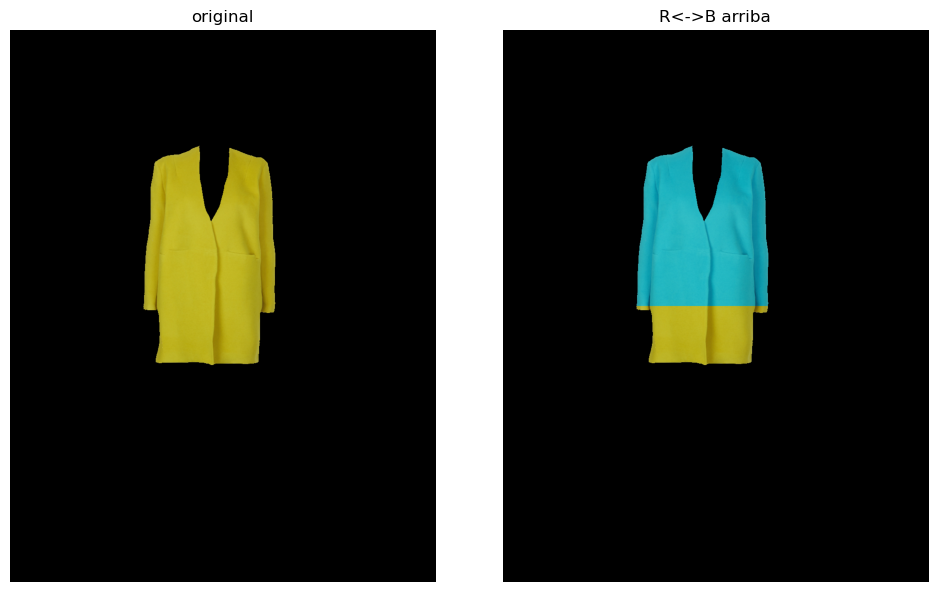

In [104]:
coat = io.imread(IMG + 'coat.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)
H = coat.shape[0]
mask[H//2:, :] = False                              # anulo la mitad inferior de la máscara
res = coat.copy()
res[mask, 0] = coat[mask, 2]
res[mask, 2] = coat[mask, 0]
mostrar([coat, res], ['original', 'R<->B arriba'], figsize=(10, 6))

### F12. Quitar el abrigo a la modelo
Usando la máscara del abrigo, pinta de **negro** (RGB) la zona del abrigo en `model.png` y, en otra imagen, deja **solo** la parte de la modelo que tapa el abrigo (el resto negro).

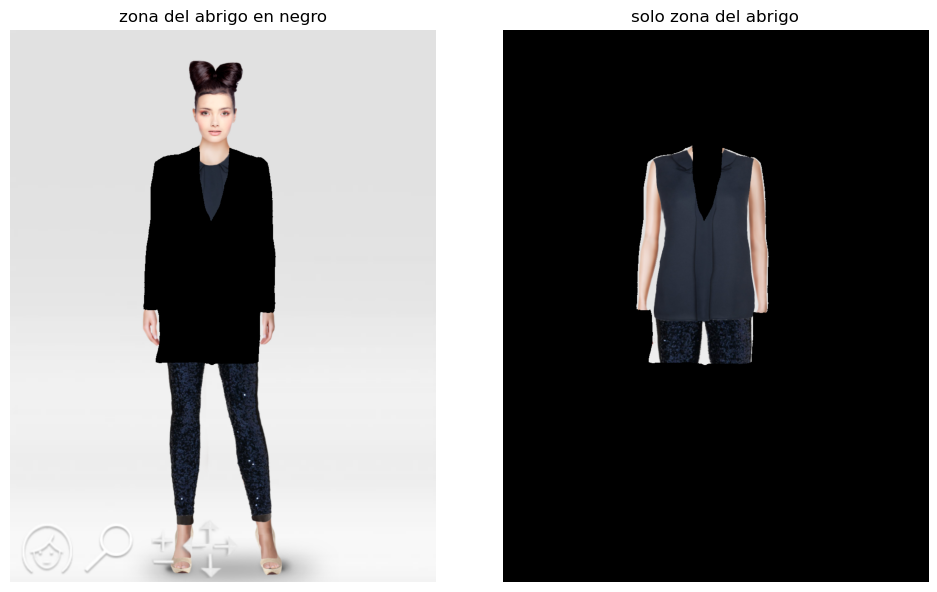

In [105]:
coat = io.imread(IMG + 'coat.png'); model = io.imread(IMG + 'model.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)
sin = model.copy()
sin[mask, :3] = 0                       # zona del abrigo -> negro

solo = model.copy()
solo[~mask, :3] = 0                     # ~mask = todo lo que NO es abrigo -> negro
mostrar([sin, solo], ['zona del abrigo en negro', 'solo zona del abrigo'], figsize=(10, 6))

### F13. Bounding box del abrigo
Encuentra el **rectángulo mínimo** que contiene el abrigo (primeras/últimas filas y columnas con algún píxel True) y recorta la modelo con él.

filas 248 720 columnas 286 570


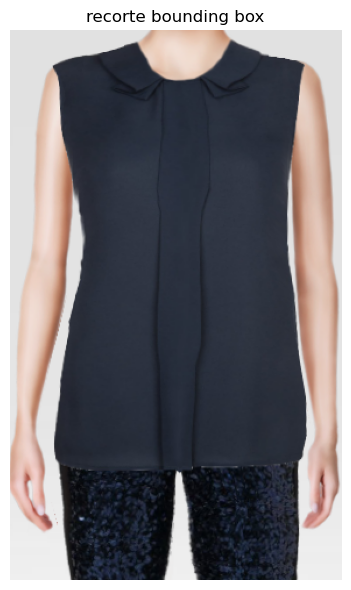

In [106]:
coat = io.imread(IMG + 'coat.png'); model = io.imread(IMG + 'model.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)
filas = np.where(mask.any(axis=1))[0]      # índices de filas con algún True
cols  = np.where(mask.any(axis=0))[0]      # índices de columnas con algún True
r0, r1, c0, c1 = filas[0], filas[-1], cols[0], cols[-1]
print('filas', r0, r1, 'columnas', c0, c1)
rec = model[r0:r1+1, c0:c1+1]              # +1 porque el final del slice no se incluye
mostrar([rec], ['recorte bounding box'], figsize=(5, 6))

### F14. Píxeles de cada círculo
Cuenta cuántos píxeles **no blancos** tiene cada uno de los 3 círculos de `circles.bmp` (columnas 0–299, 300–599, 600–fin). ¿Cuál es el más grande?

In [107]:
c = io.imread(IMG + 'circles.bmp')
no_blanco = ~np.all(c == 255, axis=2) if c.ndim == 3 else (c != 255)
cuentas = [no_blanco[:, a:b].sum() for a, b in [(0, 300), (300, 600), (600, c.shape[1])]]
for n, k in zip(['izquierdo', 'central', 'derecho'], cuentas):
    print(f'{n:10s} {k} píxeles')
print('más grande:', ['izquierdo', 'central', 'derecho'][int(np.argmax(cuentas))])

izquierdo  45741 píxeles
central    42206 píxeles
derecho    41857 píxeles
más grande: izquierdo


### F15. Viñeta circular
Deja visible solo un **círculo central** del panda de radio 300 y pon el resto en **negro**. Después, en otra, pon el exterior en **gris** en lugar de negro.

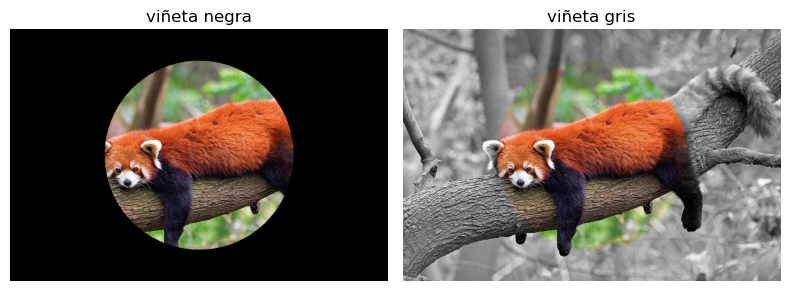

In [108]:
p = io.imread(IMG + 'panda.jpg')
H, W = p.shape[:2]
f, c = np.indices((H, W))
dentro = (f - H//2)**2 + (c - W//2)**2 <= 300**2

a = p.copy()
a[~dentro] = 0                                      # fuera -> negro

g3 = gray2rgb(img_as_ubyte(rgb2gray(p)))
b = np.where(dentro[:, :, None], p, g3)             # dentro color, fuera gris
mostrar([a, b], ['viñeta negra', 'viñeta gris'])

### F16. Umbral por canal
En `barcelona.jpg` binariza **cada canal** por separado con su propia media y combina las 3 binarias como una RGB (cada canal 0 o 255).

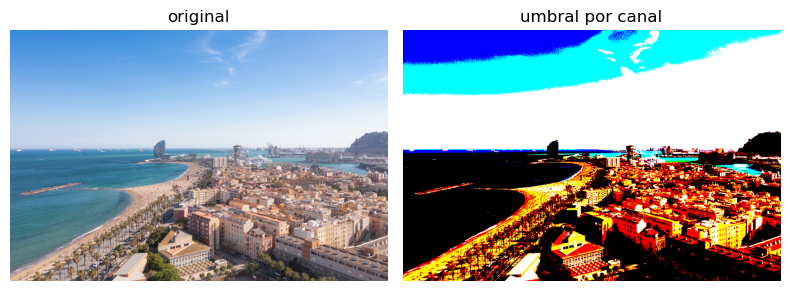

In [109]:
b = io.imread(IMG + 'barcelona.jpg')
res = np.zeros_like(b)
for k in range(3):
    canal = b[:, :, k]
    res[:, :, k] = (canal > canal.mean()).astype(np.uint8) * 255
# Sin bucle: res = ((b > b.mean(axis=(0, 1))) * 255).astype(np.uint8)   (media por canal)
mostrar([b, res], ['original', 'umbral por canal'])

### F17. Máscara a partir de otra imagen
Usa la binaria del panda (gris > media) como **máscara** para combinar dos imágenes: donde es True pon `chairs.jpg` (redimensionada) y donde es False pon `barcelona.jpg` (redimensionada).

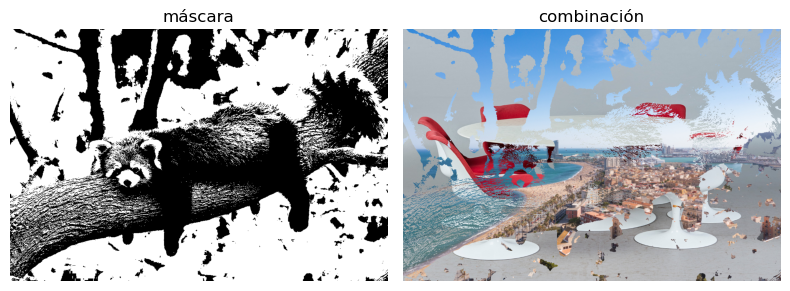

In [110]:
p = io.imread(IMG + 'panda.jpg')
m = rgb2gray(p) > rgb2gray(p).mean()                          # (800, 1200)
A = img_as_ubyte(resize(io.imread(IMG + 'chairs.jpg'), p.shape))
B = img_as_ubyte(resize(io.imread(IMG + 'barcelona.jpg'), p.shape))
res = B.copy()
res[m] = A[m]                                                 # A[m] es (N, 3)
mostrar([m, res], ['máscara', 'combinación'])

### F18. Poner el abrigo de otro color solo donde es oscuro
Al superponer el abrigo sobre la modelo, usa el abrigo original en las zonas **claras** del abrigo (gris > 0.5) y el abrigo con R↔B en las **oscuras**.

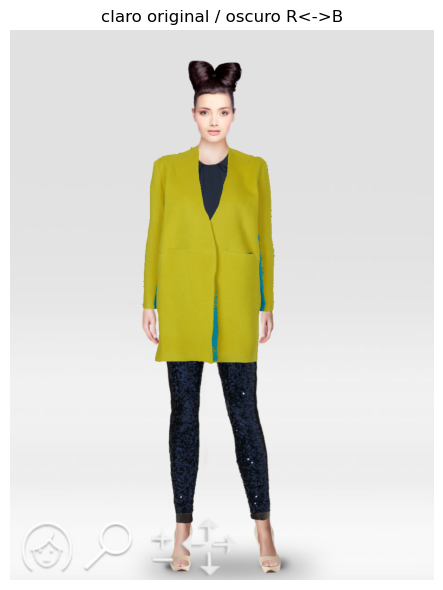

In [111]:
coat = io.imread(IMG + 'coat.png'); model = io.imread(IMG + 'model.png')
mask = np.any(coat[:, :, :3] != 0, axis=2)
gcoat = rgb2gray(coat[:, :, :3])
claro  = mask & (gcoat > 0.5)
oscuro = mask & (gcoat <= 0.5)
swap = coat[:, :, [2, 1, 0]]                  # solo RGB con R y B intercambiados
res = model.copy()
res[claro, :3]  = coat[claro, :3]
res[oscuro, :3] = swap[oscuro]
mostrar([res], ['claro original / oscuro R<->B'], figsize=(5, 6))

---
## G. Brillo y contraste

### G1. Desplazar (oscurecer / aclarar) — repaso P1
Con `cell_lowcontrast2.png`: oscurece para que el mínimo sea 0 y aclara para que el máximo sea 255. ¿Cambia el contraste?

orig                 shape=(898, 1181) dtype=uint8 min=80 max=181
dark                 shape=(898, 1181) dtype=uint8 min=0 max=101
bright               shape=(898, 1181) dtype=uint8 min=154 max=255
rango (max-min): 101 101 101


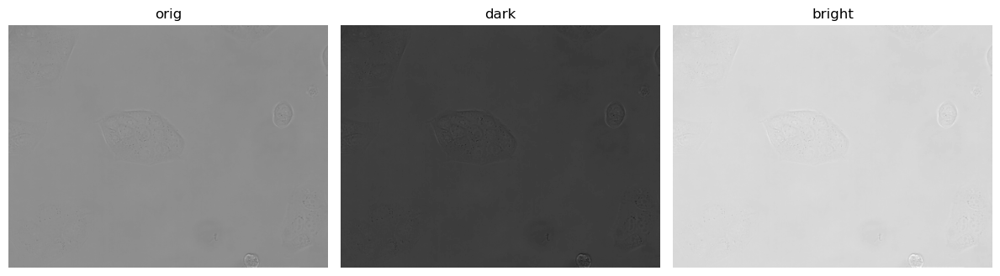

In [112]:
c = io.imread(IMG + 'cell_lowcontrast2.png')
dark = c - c.min()                     # sin overflow: nadie baja de 0
bright = c + (255 - c.max())           # sin overflow: el máximo llega justo a 255
info('orig', c); info('dark', dark); info('bright', bright)
print('rango (max-min):', np.ptp(c), np.ptp(dark), np.ptp(bright))   # ptp = max - min -> IGUAL: mismo contraste
mostrar([c, dark, bright], ['orig', 'dark', 'bright'], vmax=255)

### G2. Contrast stretching a cualquier rango
Estira el contraste de `cell_lowcontrast2.png` a (a) [0,1] float, (b) [0,255] uint8 y (c) [50,200] uint8, con fórmula y con `rescale_intensity`.

[0,1] iguales: True
[0,255] diferencia máx: 1
[50,200] diferencia máx: 0.4950495049505008
[0,1]                shape=(898, 1181) dtype=float64 min=0.0 max=1.0
[0,255]              shape=(898, 1181) dtype=uint8 min=0 max=255
[50,200]             shape=(898, 1181) dtype=uint8 min=50 max=200


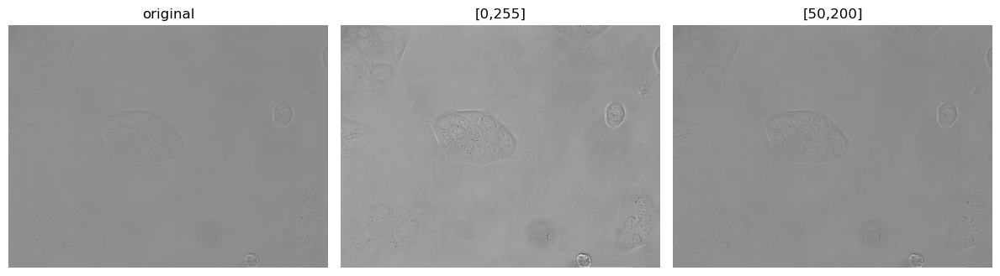

In [113]:
c = io.imread(IMG + 'cell_lowcontrast2.png')
n = (c - c.min()) / (c.max() - c.min())            # [0,1] float  (fórmula base)

a = n
b = (n * 255).round().astype(np.uint8)              # [0,255]: multiplicar y redondear
cc = (50 + n * (200 - 50)).round().astype(np.uint8) # [a,b]: a + n*(b-a)

a2 = rescale_intensity(c, out_range=(0, 1))
b2 = rescale_intensity(c)                           # uint8 -> por defecto [0,255]
c2 = rescale_intensity(c, out_range=(50, 200))

print('[0,1] iguales:', np.allclose(a, a2))
# rescale_intensity en uint8 TRUNCA en vez de redondear -> puede diferir en 1 nivel de la fórmula con round()
print('[0,255] diferencia máx:', np.abs(b.astype(int) - b2.astype(int)).max())
print('[50,200] diferencia máx:', np.abs(cc - c2).max())
info('[0,1]', a); info('[0,255]', b); info('[50,200]', cc)
mostrar([c, b, cc], ['original', '[0,255]', '[50,200]'], vmax=255)

### G3. Estirar saturando (in_range / percentiles)
Estira el contraste usando como rango de entrada los **percentiles 2 y 98** (lo que quede fuera satura).

percentiles 137.0 144.0
sat                  shape=(898, 1181) dtype=uint8 min=0 max=255


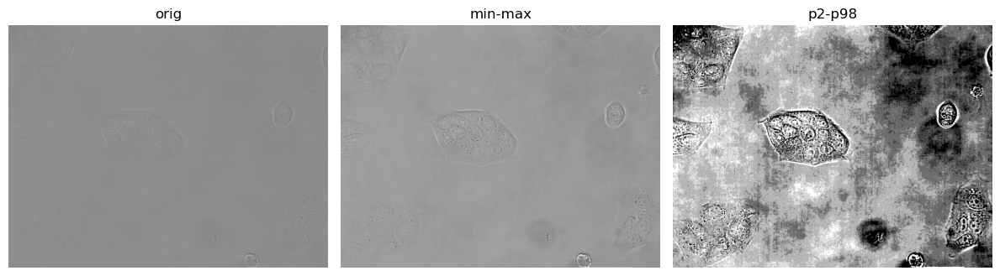

In [114]:
c = io.imread(IMG + 'cell_lowcontrast2.png')
p2, p98 = np.percentile(c, (2, 98))
s = rescale_intensity(c, in_range=(p2, p98))        # <p2 -> 0, >p98 -> 255, en medio estira
# A mano: np.clip((c - p2) / (p98 - p2), 0, 1)
print('percentiles', p2, p98); info('sat', s)
mostrar([c, rescale_intensity(c), s], ['orig', 'min-max', 'p2-p98'], vmax=255)

### G4. Negativo
Calcula el negativo del panda en uint8 y de su gris en float.

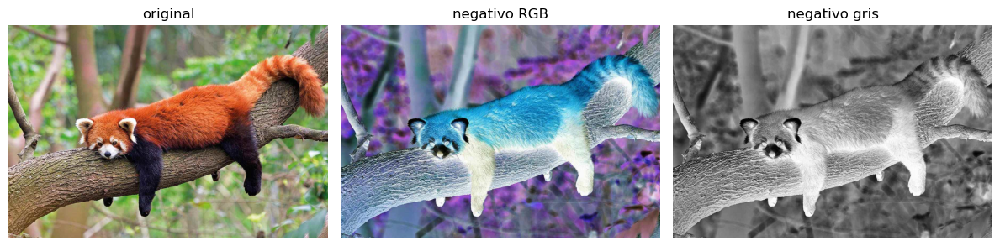

In [115]:
p = io.imread(IMG + 'panda.jpg')
neg = 255 - p                         # uint8: sin overflow porque p está en [0,255]
# también: np.invert(p) o ~p (solo para uint8)
g = rgb2gray(p)
gneg = 1 - g                          # float [0,1] -> el negativo es 1 - g
mostrar([p, neg, gneg], ['original', 'negativo RGB', 'negativo gris'], vmax=1)

### G5. Brillo y contraste multiplicativos
Sobre la gris uint8 del panda: (a) brillo ×1.5 saturando; (b) más contraste con `(I-128)*1.5+128`; (c) menos contraste con factor 0.5.

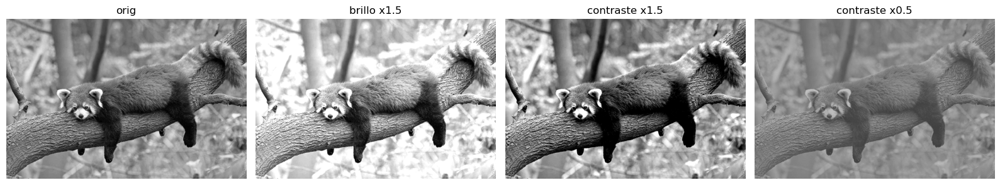

In [116]:
g = img_as_ubyte(rgb2gray(io.imread(IMG + 'panda.jpg'))).astype(float)   # a float para operar
a = np.clip(g * 1.5, 0, 255).astype(np.uint8)
b = np.clip((g - 128) * 1.5 + 128, 0, 255).astype(np.uint8)   # aleja los valores de 128
c = np.clip((g - 128) * 0.5 + 128, 0, 255).astype(np.uint8)   # los acerca a 128
mostrar([g, a, b, c], ['orig', 'brillo x1.5', 'contraste x1.5', 'contraste x0.5'], vmax=255)

### G6. Corrección gamma
Aplica gamma 0.5 (aclara) y 2 (oscurece) a la gris del panda: `I_out = I_in ** gamma` con I en [0,1].

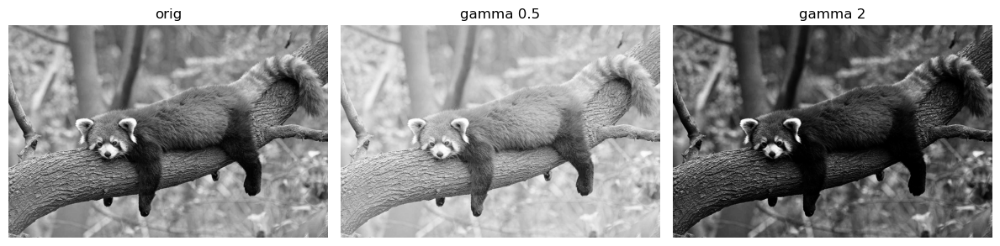

In [117]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))       # IMPORTANTE: en [0,1], si no la potencia explota
g05 = g ** 0.5
g2 = g ** 2
# skimage: from skimage.exposure import adjust_gamma; adjust_gamma(g, 0.5)
mostrar([g, g05, g2], ['orig', 'gamma 0.5', 'gamma 2'], vmax=1)

### G7. Histograma antes y después
Muestra el histograma de `cell_lowcontrast2.png` antes y después del contrast stretching.

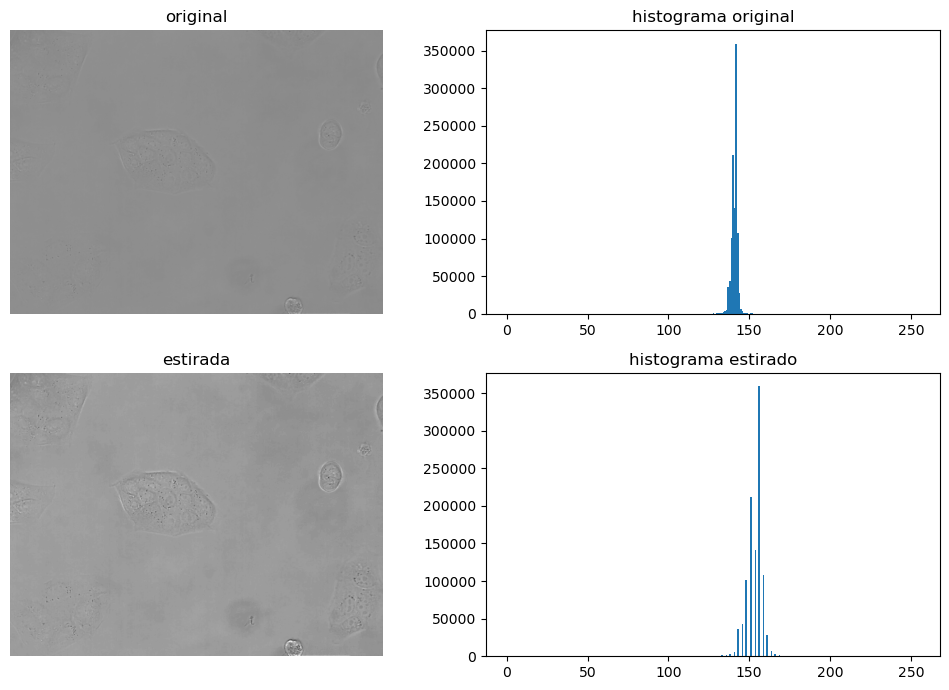

In [118]:
c = io.imread(IMG + 'cell_lowcontrast2.png')
s = rescale_intensity(c)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].imshow(c, cmap='gray', vmin=0, vmax=255); axes[0, 0].set_title('original'); axes[0, 0].axis('off')
axes[0, 1].hist(c.ravel(), bins=256, range=(0, 255))   # ravel() aplana la imagen a 1D
axes[0, 1].set_title('histograma original')
axes[1, 0].imshow(s, cmap='gray', vmin=0, vmax=255); axes[1, 0].set_title('estirada'); axes[1, 0].axis('off')
axes[1, 1].hist(s.ravel(), bins=256, range=(0, 255))
axes[1, 1].set_title('histograma estirado')
plt.tight_layout(); plt.show()

### G8. Estirar cada canal RGB por separado
Aplica contrast stretching a **cada canal** de `barcelona.jpg` por separado (cada uno con su min y max) y compáralo con estirar la imagen entera.

canal 0 min/max original: 7 255
canal 1 min/max original: 11 255
canal 2 min/max original: 13 255


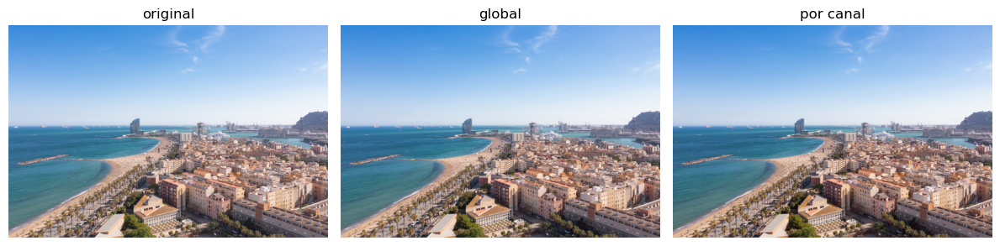

In [119]:
b = io.imread(IMG + 'barcelona.jpg')
por_canal = np.zeros_like(b)
for k in range(3):
    por_canal[:, :, k] = rescale_intensity(b[:, :, k])      # cada canal a [0,255] con su propio min/max
global_ = rescale_intensity(b)                               # min y max de TODA la imagen
for k in range(3):
    print('canal', k, 'min/max original:', b[:, :, k].min(), b[:, :, k].max())
mostrar([b, global_, por_canal], ['original', 'global', 'por canal'])

### G9. Cuantización (reducir niveles de gris)
Reduce la gris uint8 del panda a **4 niveles** (0, 85, 170, 255) y a **2 niveles**. ¿Cuántos valores distintos quedan?

valores distintos: 256 [  0  85 170 255] [  0 255]


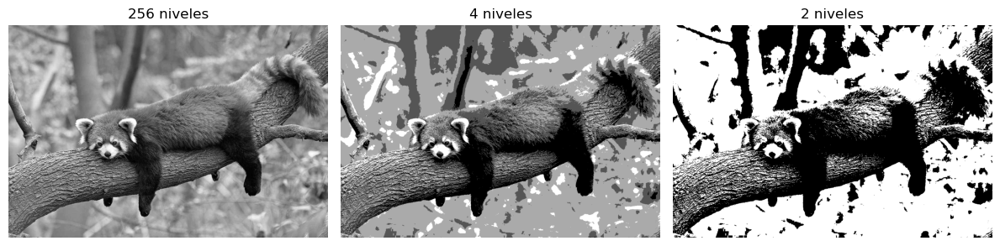

In [120]:
g = img_as_ubyte(rgb2gray(io.imread(IMG + 'panda.jpg')))
n = 4
q4 = (g // (256 // n)) * (255 // (n - 1))       # g//64 -> 0..3 ; *85 -> 0, 85, 170, 255
q2 = (g // 128) * 255                           # 0 o 255
print('valores distintos:', np.unique(g).size, np.unique(q4), np.unique(q2))
mostrar([g, q4.astype(np.uint8), q2.astype(np.uint8)], ['256 niveles', '4 niveles', '2 niveles'], vmax=255)

### G10. Brillo solo en una región
Aclara (+80, saturado) solo el **cuadrado central** de 300×300 del panda.

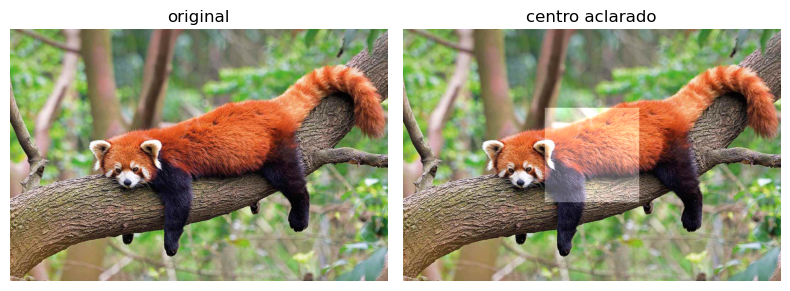

In [121]:
p = io.imread(IMG + 'panda.jpg')
H, W = p.shape[:2]
r0, c0 = (H - 300) // 2, (W - 300) // 2
res = p.copy()
zona = res[r0:r0+300, c0:c0+300].astype(int) + 80
res[r0:r0+300, c0:c0+300] = np.clip(zona, 0, 255).astype(np.uint8)
mostrar([p, res], ['original', 'centro aclarado'])

### G11. Ecualización del histograma
Ecualiza `cell_lowcontrast2.png` con `skimage.exposure.equalize_hist` y compárala con el contrast stretching.

ecualizada           shape=(898, 1181) dtype=float64 min=9.429176512298475e-07 max=1.0


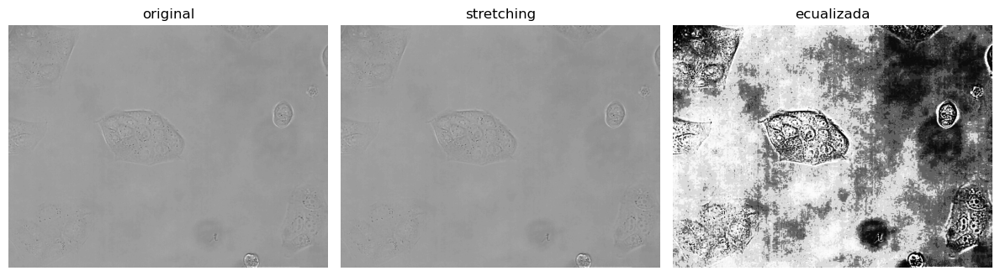

In [122]:
from skimage.exposure import equalize_hist
c = io.imread(IMG + 'cell_lowcontrast2.png')
eq = equalize_hist(c)                  # devuelve float [0,1]; reparte los niveles uniformemente
st = rescale_intensity(c)              # uint8 [0,255]
info('ecualizada', eq)
mostrar([c, st, eq], ['original', 'stretching', 'ecualizada'], vmax=None)

### G12. Normalizar a media 0.5
Desplaza la gris del panda para que su **media sea 0.5** y recorta a [0,1].

media antes: 0.502 después: 0.5


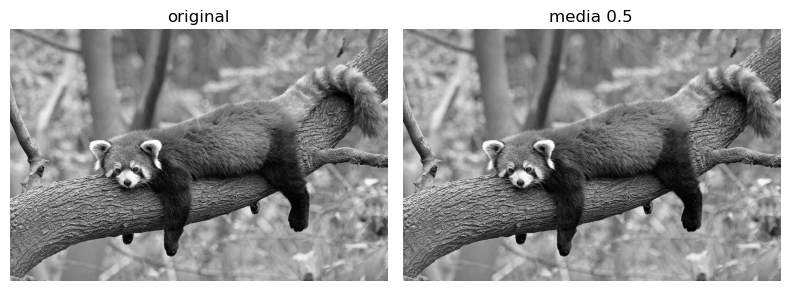

In [123]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))
n = np.clip(g - g.mean() + 0.5, 0, 1)
print('media antes:', round(g.mean(), 3), 'después:', round(n.mean(), 3))
mostrar([g, n], ['original', 'media 0.5'], vmax=1)

---
## H. Cambiar tamaño

### H1. rescale en gris y en RGB
Reduce la gris de `coins` al 50% (a) normal, (b) con `preserve_range=True`, (c) en uint8. Haz lo mismo con el panda RGB.

In [124]:
coins = data.coins()                                     # uint8 gris
a = rescale(coins, 0.5)                                  # float [0,1]
b = rescale(coins, 0.5, preserve_range=True)             # float pero con valores 0..255
c = img_as_ubyte(rescale(coins, 0.5))                    # uint8 0..255
for n, im in [('normal', a), ('preserve', b), ('ubyte', c)]:
    info(n, im)

p = io.imread(IMG + 'panda.jpg')
pr = rescale(p, 0.5, channel_axis=-1)     # channel_axis=-1: la última dim son canales, NO escalarla
info('panda rescale', pr)                 # (400, 600, 3)
# En versiones antiguas de skimage (<0.19): rescale(p, 0.5, multichannel=True)

normal               shape=(152, 192) dtype=float64 min=0.018911084727072956 max=0.9155880858770281
preserve             shape=(152, 192) dtype=float64 min=4.822326605403603 max=233.4749618986422
ubyte                shape=(152, 192) dtype=uint8 min=5 max=233
panda rescale        shape=(400, 600, 3) dtype=float64 min=8.302320975894978e-08 max=1.0


### H2. resize a tamaño exacto y manteniendo proporción
Redimensiona el panda (a) a 300×300 (se deforma) y (b) a 300 de alto **manteniendo la proporción**.

300x300              shape=(300, 300, 3) dtype=uint8 min=0 max=255
proporcional         shape=(300, 450, 3) dtype=uint8 min=0 max=255


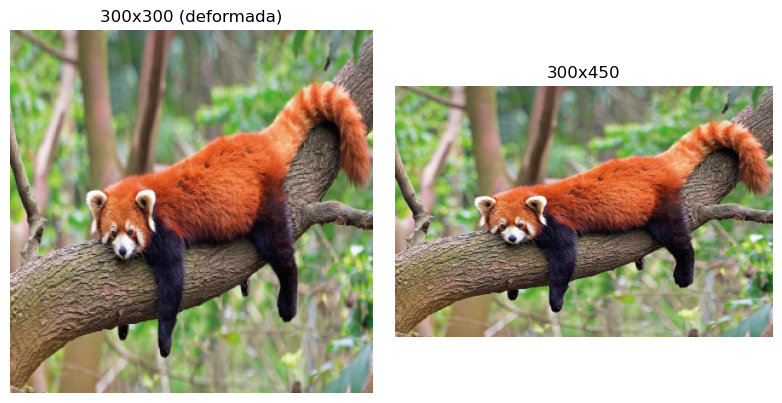

In [125]:
p = io.imread(IMG + 'panda.jpg')
h, w = p.shape[:2]
a = img_as_ubyte(resize(p, (300, 300)))               # resize acepta (alto, ancho); canales se mantienen
nuevo_alto = 300
nuevo_ancho = int(round(w * nuevo_alto / h))          # regla de tres: w/h = ancho/alto
b = img_as_ubyte(resize(p, (nuevo_alto, nuevo_ancho)))
info('300x300', a); info('proporcional', b)
mostrar([a, b], ['300x300 (deformada)', f'{nuevo_alto}x{nuevo_ancho}'])

### H3. 15% más grande con rescale (opcional de la P1)
Escala el panda un 15% con `rescale` y compara el shape con el lienzo de la P1 (`int(h*1.15)`).

In [126]:
p = io.imread(IMG + 'panda.jpg')
big = img_as_ubyte(rescale(p, 1.15, channel_axis=-1))
print('rescale  :', big.shape)
print('int(1.15):', (int(p.shape[0]*1.15), int(p.shape[1]*1.15), 3))
# rescale REDONDEA (920) mientras int() TRUNCA (919): pueden diferir en 1 píxel

rescale  : (920, 1380, 3)
int(1.15): (919, 1380, 3)


### H4. Pixelar
Pixela el panda: redúcelo a 1/20 y vuelve a ampliarlo al tamaño original **sin suavizar** (vecino más cercano).

pequeña              shape=(40, 60, 3) dtype=uint8 min=0 max=255
pixelada             shape=(800, 1200, 3) dtype=uint8 min=0 max=255


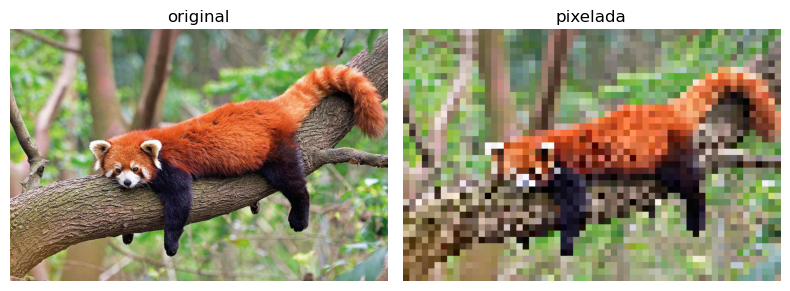

In [127]:
p = io.imread(IMG + 'panda.jpg')
peq = p[::20, ::20]                                     # (40, 60, 3)
pix = np.repeat(np.repeat(peq, 20, axis=0), 20, axis=1) # cada píxel -> bloque 20x20
# Con skimage: resize(peq, p.shape, order=0) -> order=0 = vecino más cercano (sin interpolar)
info('pequeña', peq); info('pixelada', pix)
mostrar([p, pix], ['original', 'pixelada'])

### H5. Mismo tamaño para operar
Intenta sumar `panda.jpg` y `barcelona.jpg`. ¿Qué error da? Arréglalo redimensionando barcelona al tamaño del panda.

ERROR: operands could not be broadcast together with shapes (800,1200,3) (682,1024,3) 


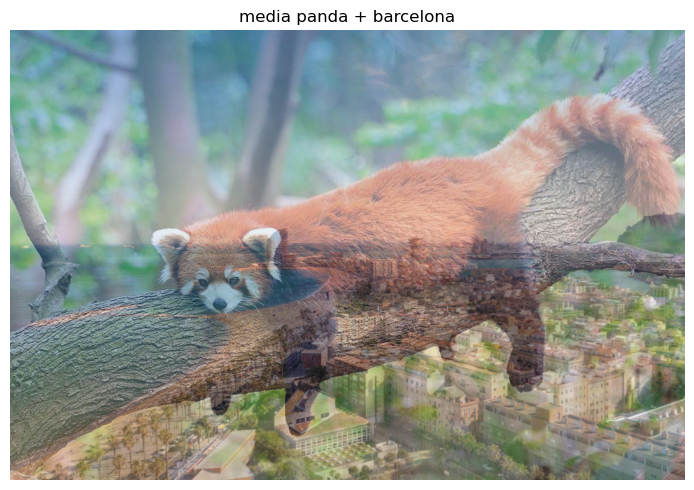

In [128]:
p = io.imread(IMG + 'panda.jpg'); b = io.imread(IMG + 'barcelona.jpg')
try:
    p + b
except ValueError as e:
    print('ERROR:', e)                       # shapes (800,1200,3) y (682,1024,3) no son compatibles
b2 = img_as_ubyte(resize(b, p.shape))        # resize al shape completo (incluye los 3 canales)
suma = ((p.astype(np.uint16) + b2) // 2).astype(np.uint8)
mostrar([suma], ['media panda + barcelona'], figsize=(8, 5))

---
## I. Visualización

### I1. vmin/vmax: por qué importan
Muestra `cell_lowcontrast2.png` con autoescala y con `vmin=0, vmax=255`, y la versión `/2` con ambos. Explica.

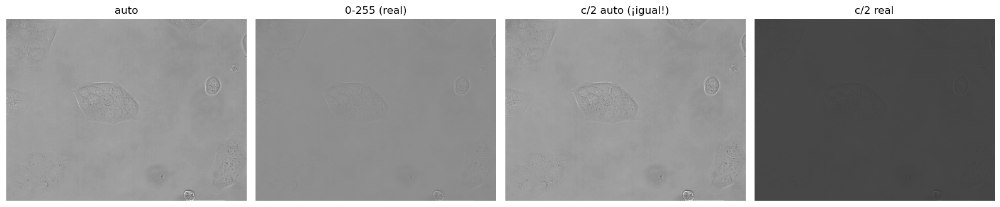

In [129]:
c = io.imread(IMG + 'cell_lowcontrast2.png')
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(c, cmap='gray');                       axes[0].set_title('auto')
axes[1].imshow(c, cmap='gray', vmin=0, vmax=255);     axes[1].set_title('0-255 (real)')
axes[2].imshow(c / 2, cmap='gray');                   axes[2].set_title('c/2 auto (¡igual!)')
axes[3].imshow(c / 2, cmap='gray', vmin=0, vmax=255); axes[3].set_title('c/2 real')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()
# Con autoescala imshow pinta min->negro y max->blanco: oculta cambios de brillo/contraste.

### I2. Rejilla 2×3 con títulos y una sin usar
Muestra 5 imágenes en una rejilla 2×3 con títulos y oculta el sexto hueco vacío.

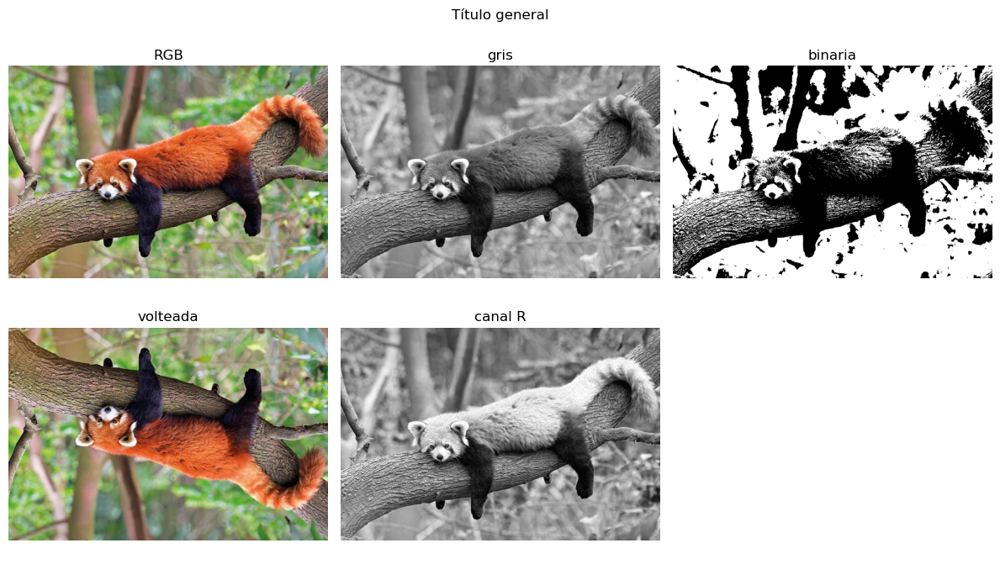

In [130]:
p = io.imread(IMG + 'panda.jpg'); g = rgb2gray(p)
imgs = [p, g, g > g.mean(), p[::-1], p[:, :, 0]]
tits = ['RGB', 'gris', 'binaria', 'volteada', 'canal R']
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.ravel()                      # matriz 2x3 -> vector de 6 para recorrerlo fácil
for ax, im, t in zip(axes, imgs, tits):
    ax.imshow(im, cmap='gray'); ax.set_title(t)
for ax in axes:
    ax.axis('off')                       # también oculta el 6º hueco vacío
fig.suptitle('Título general')           # título de toda la figura
plt.tight_layout(); plt.show()

### I3. Estilo add_subplot (como el tutorial)
Muestra 3 imágenes con `fig.add_subplot` en lugar de `plt.subplots`.

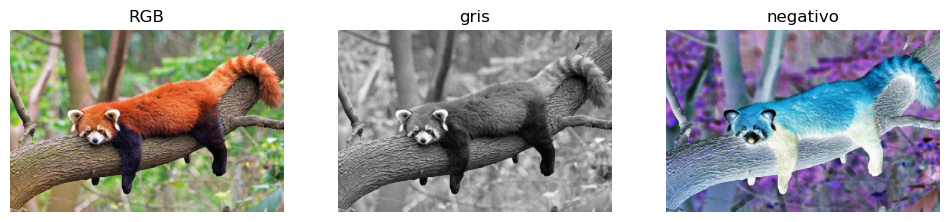

In [131]:
p = io.imread(IMG + 'panda.jpg')
fig = plt.figure(figsize=(12, 4))
for i, (im, t) in enumerate([(p, 'RGB'), (rgb2gray(p), 'gris'), (255 - p, 'negativo')]):
    fig.add_subplot(1, 3, i + 1)        # ¡la posición empieza en 1, no en 0!
    plt.imshow(im, cmap='gray')
    plt.title(t)                        # con add_subplot se usa plt.title / plt.axis
    plt.axis('off')
plt.show()

### I4. Colormaps y colorbar
Muestra la gris del panda con los colormaps `gray`, `viridis`, `hot` y `jet`, cada uno con su barra de color.

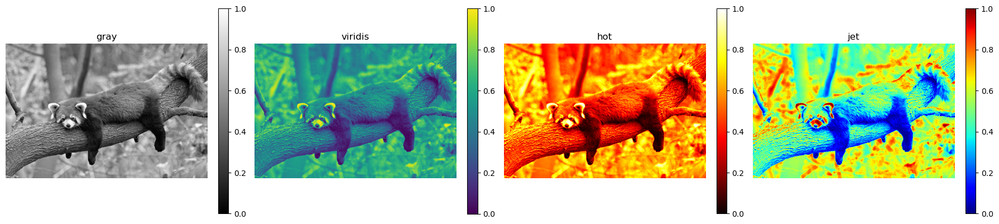

In [132]:
g = rgb2gray(io.imread(IMG + 'panda.jpg'))
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, cm in zip(axes, ['gray', 'viridis', 'hot', 'jet']):
    im = ax.imshow(g, cmap=cm, vmin=0, vmax=1)
    ax.set_title(cm); ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046)     # barra con la correspondencia valor -> color
plt.tight_layout(); plt.show()

### I5. Mostrar a tamaño real
Muestra `coins` a su tamaño original en píxeles (como en el tutorial: `figsize = (ancho/dpi, alto/dpi)`).

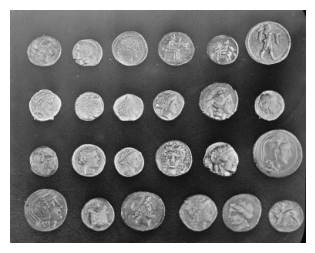

In [133]:
coins = data.coins()
dpi = 100
plt.figure(figsize=(coins.shape[1] / dpi, coins.shape[0] / dpi), dpi=dpi)   # (ancho, alto) en pulgadas
plt.imshow(coins, cmap='gray', vmin=0, vmax=255)
plt.axis('off'); plt.show()

## J. Preguntas teóricas cortas (respuestas)

| Pregunta | Respuesta |
|---|---|
| ¿Cuántos niveles tiene un píxel `uint8`? | 2⁸ = **256** (0…255) |
| ¿Y `uint16`? ¿`bool`? | 65 536 ; 2 |
| `shape` de una gris, RGB, RGBA | `(h,w)`, `(h,w,3)`, `(h,w,4)` |
| ¿Qué devuelve `rgb2gray`? | `float64` en **[0,1]**, shape `(h,w)` |
| Fórmula de `rgb2gray` | `0.2125 R + 0.7154 G + 0.0721 B` |
| `astype(float)` vs `img_as_float` | El primero solo cambia el tipo; el segundo además **reescala** a [0,1] |
| ¿Por qué no `astype(np.uint8)` sobre un float [0,1]? | **Trunca** → casi todo 0. Usar `img_as_ubyte` |
| `np.uint8(10) - np.uint8(50)` | **216** (wrap-around, módulo 256) |
| `np.uint8(200) + np.uint8(100)` | **44** |
| ¿Qué hace `imshow` sin `vmin/vmax` en 2D? | Autoescala: min→negro, max→blanco (oculta el contraste real) |
| ¿Se ignora `cmap` en una RGB? | Sí |
| Volteo vertical / horizontal | `img[::-1, :]` / `img[:, ::-1]` |
| `b = a` ¿copia? | **No**, es el mismo array. Usar `a.copy()` |
| `rescale` vs `resize` | Factor de escala vs tamaño exacto (puede deformar). Ambos devuelven float |
| ¿Para qué `preserve_range=True`? | Para que no normalice a [0,1] (mantiene 0..255, aunque en float) |
| ¿Qué hace `rgba2rgb`? | Mezcla con fondo blanco usando el alfa → float [0,1], 3 canales |
| ¿Qué es el canal alfa? | Opacidad: 0 transparente, 255 opaco |
| `rescale_intensity(uint8)` | Estira a [0,255] **manteniendo uint8** |
| ¿Mejora el contraste restar el mínimo? | **No**, solo desplaza; el contraste (max−min) no cambia |
| ¿Qué es contrast stretching? | `(I−min)/(max−min)`: usa todo el rango disponible |
| `img[mask]` con img `(h,w,3)` y mask `(h,w)` | Array `(N,3)` con los N píxeles True |
| `np.any(x, axis=2)` | True si algún canal cumple → máscara 2D |
| ¿Por qué `(a > 1) & (a < 5)` lleva paréntesis? | Porque `&` tiene más prioridad que `>`/`<` |
| PNG vs JPG | PNG sin pérdida; JPG con pérdida (los valores cambian al guardar) |
| R+G, R+B, G+B, R+G+B | Amarillo, magenta, cian, blanco |
| `img[f, c]` ¿es (x, y)? | No: es **(fila, columna) = (y, x)**; fila 0 arriba |